# Automated Marine Debris Detection using Deep Learning


## 1. Introduction, Motivation and Problem Statement

Detecting marine debris in underwater footage can help researchers and remotely operated vehicle (ROV) operators review long surveys. Colour cast, low visibility, occlusion and recurring backgrounds make the task difficult. Given an RGB frame, the detector must locate visible objects with bounding boxes and assign each one of 22 labels, including debris, marine life, plants and the ROV itself.

We compare a compact one-stage baseline, **YOLO11n**, with a two-stage detector, **Faster R-CNN**, on footage from held-out videos. The main questions are how their detection accuracy and recall differ, and which classes, object sizes and image conditions account for that difference. A supplementary experiment evaluates the larger YOLO11l variant fine-tuned from COCO-pretrained weights on the same video-disjoint split.

**Reading the notebook.** The saved outputs show the completed experiments. Open the notebook to inspect the logs, tables and figures. Training cells are switched off by default: set `RUN_YOLO_TRAINING` (Section 4.1) or `RUN_TRAINING` (Section 4.2) to `True` to retrain. The saved results can be viewed without rerunning training. The code cells retain the source notebooks' setup, paths and dependencies. Execute only the relevant cells in their original environment if you need to reproduce a result.

## 2. Data Sources

We use **TrashCan 1.0, Instance**, introduced by [Hong, Fulton and Sattar (2020)](https://arxiv.org/abs/2007.08097). Its underwater imagery comes from the JAMSTEC J-EDI archive. The data include COCO instance annotations for 14 debris classes, six animal classes, one plant class and the ROV. The data are available from the University of Minnesota Data Repository (<https://conservancy.umn.edu/handle/11299/214865>). This project evaluates bounding-box detection. The original segmentation annotations remain in the COCO records.

The team's frozen data are under `Project_part1_2.0/Project_part1/dataset/video_split`. The COCO JSONs, `split_manifest.csv`, `video_assignment.json`, `split_report.json` and `category_mapping.json` record the split and label mapping. The handover's `code/split_by_video.py` and `code/validate_video_split.py` implement and verify the split.

## 3. Exploratory Analysis of Data

### 3.1 Video-disjoint split


The original training and validation sets shared 113 source videos. Since frames from the same video can look very similar, this could cause data leakage and make the evaluation results too optimistic. To solve this, we used `split_by_video.py` to group images by their source video IDs. The script tested 5,000 possible splits with a fixed random seed of 42. It aimed for a 70/15/15 split while keeping all 22 classes in each set.

The final dataset contains 5,124 training images, 1,095 validation images and 993 test images. There are no shared videos between the three sets. Both models use this same split for a fair comparison. Validation is used for model selection, while the test set is kept for final evaluation.

| Split | Videos | Frames | Boxes | Frames without boxes | Share of frames |
|---|---:|---:|---:|---:|---:|
| Train | 218 | 5,124 | 8,940 | 48 | 71.0% |
| Validation | 47 | 1,095 | 1,535 | 39 | 15.2% |
| Test | 47 | 993 | 1,653 | 42 | 13.8% |
| Total | 312 | 7,212 | 12,128 | 129 | 100.0% |

### 3.2 Class Imbalance and Preprocessing

**Class imbalance:** The dataset has an uneven number of objects across classes. In the training set, ROV has 2,634 bounding boxes, while cup has only 17. This means some classes have fewer examples for the models to learn from.

**Bounding box cleaning:** Some bounding boxes extend outside the image boundaries. During YOLO label generation, our code clipped 3,286 boxes to keep their coordinates within the images. No boxes were removed as invalid.

**Label formats:** We used the same data for both models, but their label formats are different. Faster R-CNN uses COCO category IDs from 1 to 22, with 0 reserved for background. YOLO uses class IDs from 0 to 21 and normalised bounding box coordinates.

Some classes have very few test examples, so their class-wise Average Precision (AP) may be unstable.

In [ ]:
import json
from pathlib import Path
from collections import Counter
root = Path.cwd()
if not (root / 'dataset' / 'video_split').is_dir():
    raise RuntimeError('Open this notebook from the project root.')
data_root = root / 'dataset' / 'video_split'
for split in ('train', 'val', 'test'):
    data = json.loads((data_root / f'instances_{split}_trashcan.json').read_text(encoding='utf-8'))
    counts = Counter(a['category_id'] for a in data['annotations'])
    print(f"\n{split}: {len(data['images'])} images, {len(data['annotations'])} annotations")
    for category in data['categories']:
        print(f"  {category['id']:2} {category['name']:<25} {counts[category['id']]}")
report = json.loads((data_root / 'split_report.json').read_text(encoding='utf-8'))
print('\nVideo overlaps:', report['pairwise_video_overlap'])



train: 5124 images, 8940 annotations
   1 rov                       2634
   2 plant                     436
   3 animal_fish               524
   4 animal_starfish           311
   5 animal_shells             232
   6 animal_crab               257
   7 animal_eel                241
   8 animal_etc                203
   9 trash_clothing            70
  10 trash_pipe                74
  11 trash_bottle              85
  12 trash_bag                 750
  13 trash_snack_wrapper       73
  14 trash_can                 279
  15 trash_cup                 17
  16 trash_container           409
  17 trash_unknown_instance    1834
  18 trash_branch              169
  19 trash_wreckage            125
  20 trash_tarp                102
  21 trash_rope                70
  22 trash_net                 45

val: 1095 images, 1535 annotations
   1 rov                       353
   2 plant                     5
   3 animal_fish               97
   4 animal_starfish           72
   5 animal_shells       

![Class distribution across the frozen video split](attachment:trashcan-class-distribution.png)

### 3.3 Split Implementation

We used `split_by_video.py` to split the dataset into training, validation and test sets.

The code follows these steps:

1. Read the original COCO annotation files.
2. Get the video ID from each image filename.
3. Keep images from the same video together to avoid data leakage.
4. Use a random seed of 42 and test 5,000 possible splits, aiming for a 70/15/15 ratio while keeping all 22 classes in each set.
5. Save the annotations in COCO and YOLO formats and check for video overlap.

The final split has no shared videos between training, validation and test sets. Both models use the same split for a fair comparison.

The code below shows how we created the dataset split.

In [ ]:
"""Create reproducible, video-disjoint COCO and YOLO detection splits.
Run from project root: python code/split_by_video.py
Original images/annotations are never changed. Output must not already exist.
"""
import argparse
import sys
from collections import Counter, defaultdict
import csv
import hashlib
import json
import math
from pathlib import Path
import random
import re
import shutil

SPLITS = ('train', 'val', 'test')


def video_id(name):
    match = re.search(r'vid_\d+', Path(name).name)
    if not match:
        raise ValueError(f'Cannot extract video ID: {name}')
    return match.group()


def write_json(path, data):
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    base = Path(__file__).resolve().parents[1] / 'dataset'
    parser.add_argument('--source', type=Path, default=base / 'instance_version')
    parser.add_argument('--output', type=Path, default=base / 'video_split')
    parser.add_argument('--ratios', nargs=3, type=float, default=[0.70, 0.15, 0.15])
    parser.add_argument('--seed', type=int, default=42)
    parser.add_argument('--trials', type=int, default=5000)
    args = parser.parse_args()
    if any(r <= 0 for r in args.ratios) or not math.isclose(sum(args.ratios), 1.0):
        parser.error('Three positive ratios must sum to 1.')
    if args.trials < 1:
        parser.error('--trials must be positive')
    if args.output.exists():
        parser.error('Output already exists; use a new --output directory to avoid replacing a frozen split.')

    images, annotations, categories = {}, [], None
    paths, groups, annotation_ids = {}, defaultdict(list), set()
    hashes = {}
    source_hashes = {}
    original_videos = {}
    for split in ('train', 'val'):
        src = args.source / f'instances_{split}_trashcan.json'
        source_hashes[src.name] = hashlib.sha256(src.read_bytes()).hexdigest()
        data = json.loads(src.read_text(encoding='utf-8'))
        if categories is None:
            categories = data['categories']
        if sorted(categories, key=lambda c: c['id']) != sorted(data['categories'], key=lambda c: c['id']):
            raise ValueError('Source category definitions differ')
        original_videos[split] = set()
        for im in data['images']:
            iid, name = im['id'], im['file_name']
            if iid in images or name in paths:
                raise ValueError(f'Duplicate image ID or filename: {iid}, {name}')
            path = args.source / split / name
            if not path.is_file():
                raise FileNotFoundError(path)
            if Path(name).name != name:
                raise ValueError(f'Expected a flat image filename: {name}')
            vid = video_id(name)
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            if digest in hashes and hashes[digest] != vid:
                raise ValueError(f'Identical images in different videos: {name}; resolve duplicates before splitting')
            hashes[digest] = vid
            images[iid], paths[name] = im, path
            groups[vid].append(iid)
            original_videos[split].add(vid)
        for ann in data['annotations']:
            if ann['id'] in annotation_ids:
                raise ValueError(f'Duplicate annotation ID: {ann["id"]}')
            annotation_ids.add(ann['id'])
            annotations.append(ann)
    if len(categories) != 22:
        raise ValueError('Expected 22 foreground categories')
    category_ids = sorted(c['id'] for c in categories)
    counts = {v: Counter() for v in groups}
    anns_by_image = defaultdict(list)
    for ann in annotations:
        if ann['image_id'] not in images or ann['category_id'] not in category_ids:
            raise ValueError(f'Invalid annotation reference: {ann["id"]}')
        counts[video_id(images[ann['image_id']]['file_name'])][ann['category_id']] += 1
        anns_by_image[ann['image_id']].append(ann)
    totals = Counter(a['category_id'] for a in annotations)

    rng = random.Random(args.seed)
    videos = sorted(groups)
    ntrain = round(len(videos) * args.ratios[0])
    nval = round(len(videos) * args.ratios[1])
    if min(ntrain, nval, len(videos) - ntrain - nval) < 1:
        raise ValueError('Too few videos for these ratios')
    best = None
    # Choose only using image/annotation counts, never model/test performance.
    for trial in range(args.trials):
        shuffled = videos.copy()
        rng.shuffle(shuffled)
        parts = [shuffled[:ntrain], shuffled[ntrain:ntrain+nval], shuffled[ntrain+nval:]]
        score, missing = 0.0, 0
        for part, ratio in zip(parts, args.ratios):
            nimages = sum(len(groups[v]) for v in part)
            cls = Counter()
            for v in part:
                cls.update(counts[v])
            missing += sum(cls[c] == 0 for c in category_ids)
            score += ((nimages / len(images) - ratio) / ratio) ** 2
            score += sum(((cls[c] / totals[c] - ratio) / ratio) ** 2 for c in category_ids) / len(category_ids)
        key = (missing, score)
        if best is None or key < best[0]:
            best = (key, parts)
        if (trial + 1) % 1000 == 0:
            print(f'Split search: {trial+1}/{args.trials}', flush=True)
    if best[0][0]:
        raise ValueError('Could not cover all 22 classes in all splits. Increase --trials or review per-video class availability.')
    assignment = {v: s for s, part in zip(SPLITS, best[1]) for v in part}
    sets = {s: {v for v in videos if assignment[v] == s} for s in SPLITS}
    assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test'])
    args.output.mkdir(parents=True)
    yolo = args.output / 'yolo'
    report = {'seed': args.seed, 'trials': args.trials, 'requested_ratios': args.ratios,
              'source_sha256': source_hashes, 'original_train_val_video_overlap': len(original_videos['train'] & original_videos['val']),
              'pairwise_video_overlap': {'train_val': 0, 'train_test': 0, 'val_test': 0},
              'total_images': len(images), 'total_annotations': len(annotations), 'total_videos': len(videos),
              'splits': {}, 'yolo_bbox_clipped': 0, 'yolo_bbox_skipped_invalid': 0}
    mapping = {cid: i for i, cid in enumerate(category_ids)}
    with (args.output / 'split_manifest.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow(['image_id', 'file_name', 'video_id', 'split'])
        for s in SPLITS:
            out_images = [im for im in images.values() if assignment[video_id(im['file_name'])] == s]
            ids = {im['id'] for im in out_images}
            out_anns = [a for a in annotations if a['image_id'] in ids]
            write_json(args.output / f'instances_{s}_trashcan.json', {'images': out_images, 'annotations': out_anns, 'categories': categories})
            (args.output / s).mkdir()
            (yolo / 'images' / s).mkdir(parents=True)
            (yolo / 'labels' / s).mkdir(parents=True)
            for i, im in enumerate(out_images):
                name = im['file_name']
                shutil.copy2(paths[name], args.output / s / name)
                shutil.copy2(paths[name], yolo / 'images' / s / name)
                writer.writerow([im['id'], name, video_id(name), s])
                lines = []
                w, h = im['width'], im['height']
                for a in anns_by_image[im['id']]:
                    x, yy, bw, bh = map(float, a['bbox'])
                    if not all(math.isfinite(z) for z in (x, yy, bw, bh)) or bw <= 0 or bh <= 0:
                        report['yolo_bbox_skipped_invalid'] += 1
                        continue
                    x1, y1, x2, y2 = max(0., min(x, w)), max(0., min(yy, h)), max(0., min(x+bw, w)), max(0., min(yy+bh, h))
                    if x2 <= x1 or y2 <= y1:
                        report['yolo_bbox_skipped_invalid'] += 1
                        continue
                    report['yolo_bbox_clipped'] += int((x1,y1,x2,y2) != (x,yy,x+bw,yy+bh))
                    lines.append(f'{mapping[a["category_id"]]} {(x1+x2)/2/w:.10f} {(y1+y2)/2/h:.10f} {(x2-x1)/w:.10f} {(y2-y1)/h:.10f}')
                (yolo / 'labels' / s / Path(name).with_suffix('.txt')).write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')
                if (i + 1) % 500 == 0:
                    print(f'{s}: {i+1}/{len(out_images)} images exported', flush=True)
            cls = Counter(a['category_id'] for a in out_anns)
            report['splits'][s] = {'images': len(out_images), 'videos': len(sets[s]), 'annotations': len(out_anns),
                                     'image_ratio': len(out_images)/len(images), 'annotations_per_category': dict(cls)}
    names = {c['id']: c['name'] for c in categories}
    # Relative to the YAML file; portable when the dataset directory is moved.
    yaml = ['train: images/train', 'val: images/val', 'test: images/test', 'nc: 22', 'names:']
    yaml += [f'  {mapping[c]}: {json.dumps(names[c])}' for c in category_ids]
    (yolo / 'data.yaml').write_text('\n'.join(yaml)+'\n', encoding='utf-8')
    write_json(args.output / 'category_mapping.json', [{'coco_id': c, 'faster_rcnn_label': i+1, 'yolo_label': i, 'name': names[c]} for i,c in enumerate(category_ids)])
    write_json(args.output / 'video_assignment.json', dict(sorted(assignment.items())))
    write_json(args.output / 'split_report.json', report)
    assert sum(x['images'] for x in report['splits'].values()) == len(images)
    assert sum(x['annotations'] for x in report['splits'].values()) == len(annotations)
    checksums = {p.relative_to(args.output).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted(args.output.rglob('*')) if p.is_file() and p.name != 'checksums.json'}
    write_json(args.output / 'checksums.json', checksums)
    print(json.dumps(report, indent=2))
    print(f'Saved to {args.output.resolve()}')


if __name__ == '__main__' and 'ipykernel' not in sys.modules:
    main()
else:
    print('split_by_video.py is a command-line script; this notebook uses the frozen split.')


## 4. Models and Methods

### 4.1 YOLO11n baseline

YOLO11n is the nano variant of [Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11/). It predicts boxes and classes in one stage and has 2.61 million parameters in the checkpoint used for the unified comparison. We reused Ultralytics' architecture, trainer and COCO-pretrained weights. Our work was adapting the shared video split to its label format, fine-tuning on the 22 categories, running controlled parameter trials, selecting a checkpoint on validation and evaluating it on the held-out test set.

The reference trial (`baseline`) used 640 px, 50 epochs and batch size 8. We changed one factor per trial: batch size to 16, input resolution to 800 px, or training length to 100 epochs. Each trial started from the same COCO-pretrained weights and used SGD, initial LR 0.01, final LR factor 1.0, momentum 0.937, weight decay 0.0005, three warm-up epochs, mosaic throughout training, mixed precision and seed 42. The training function and log below document the original runs. The saved log records the four training runs. The training cells run only when `RUN_YOLO_TRAINING` is set to `True`.

#### Initial configuration

In [ ]:
from pathlib import Path
from collections import defaultdict
import json
import shutil

import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from ultralytics import YOLO
import ultralytics

BASE = Path.cwd()

# The path of original imgs
IMAGE_ROOT = BASE.parent / "Project_part1_2.0" / "Project_part1" / "dataset" / "video_split"


DATASET = IMAGE_ROOT / "yolo"
RUNS = BASE / "runs_yolo11"
DEVICE = 0 if torch.cuda.is_available() else "cpu"
RUN_YOLO_TRAINING = False  # True retrains the four YOLO11n trials and YOLO11l (several hours)

display(pd.DataFrame([{
    "Torch": torch.__version__,
    "Ultralytics": ultralytics.__version__,
    "Device": torch.cuda.get_device_name(0)
              if torch.cuda.is_available() else "CPU"
}]))

,Torch,Ultralytics,Device
0,2.8.0+cu128,8.4.198,NVIDIA GeForce RTX 4080 SUPER


#### Dataset annotations and configuration

In [ ]:
annotations = {
    split: json.loads(
        (IMAGE_ROOT / f"instances_{split}_trashcan.json")
        .read_text(encoding="utf-8")
    )
    for split in ["train", "val", "test"]
}

categories = sorted(
    annotations["train"]["categories"],
    key=lambda c: c["id"]
)

names = {i: c["name"] for i, c in enumerate(categories)}

# use yaml from dataset
DATA_YAML = DATASET / "data.yaml"

display(pd.DataFrame([
    {
        "Split": split,
        "Images": len(coco["images"]),
        "Boxes": len(coco["annotations"])
    }
    for split, coco in annotations.items()
]))

,Split,Images,Boxes
0,train,5124,8940
1,val,1095,1535
2,test,993,1653


#### YOLO11n training examples

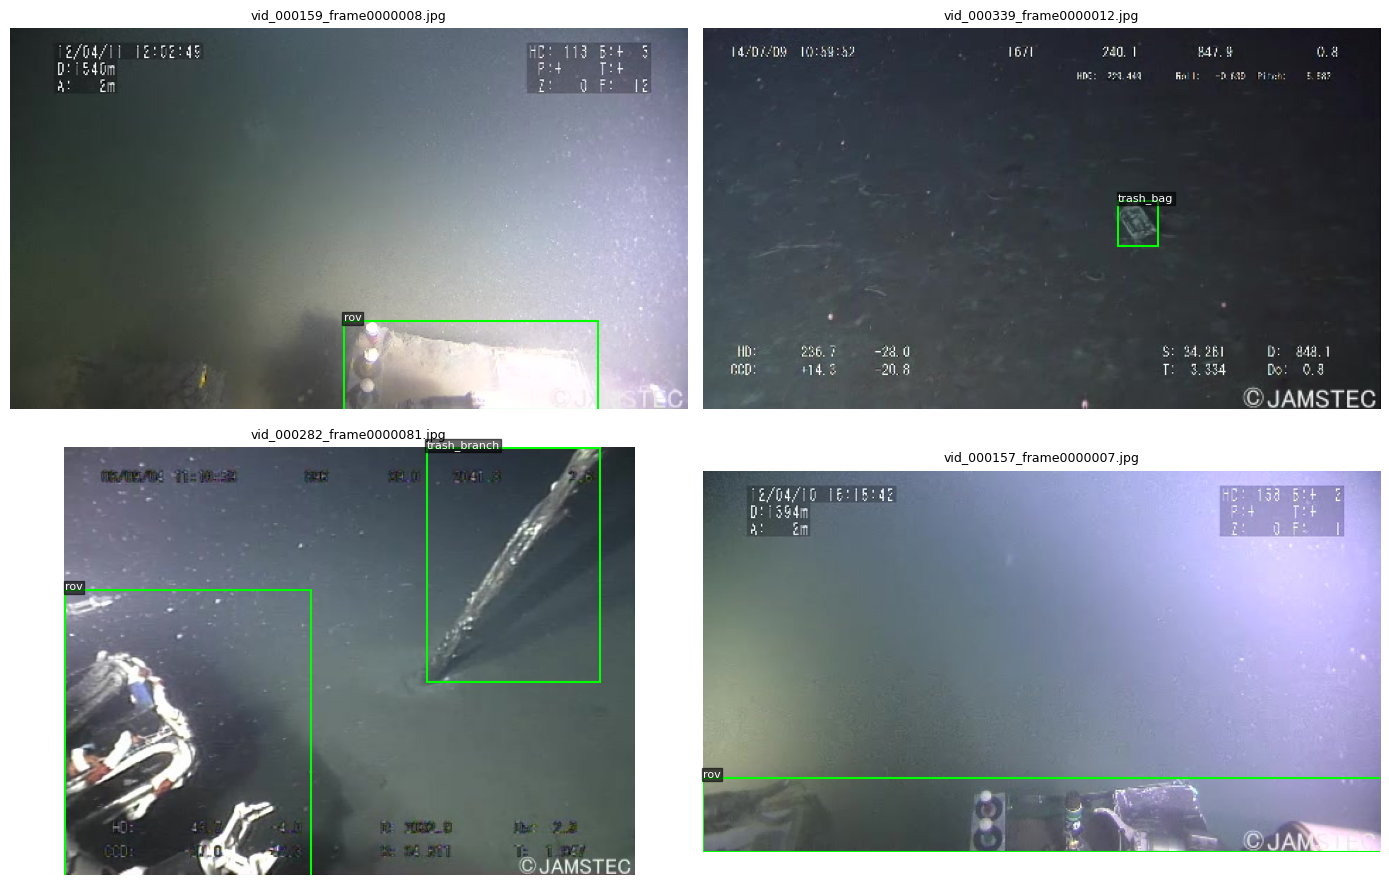

In [ ]:
from matplotlib.patches import Rectangle

samples = annotations["train"]["images"][:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, item in zip(axes.flat, samples):
    filename = item["file_name"]
    image = Image.open(DATASET / "images/train" / filename)
    width, height = image.size

    ax.imshow(image)

    label_path = DATASET / "labels/train" / Path(filename).with_suffix(".txt")
    for line in label_path.read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x = (xc - bw / 2) * width
        y = (yc - bh / 2) * height

        ax.add_patch(Rectangle(
            (x, y), bw * width, bh * height,
            fill=False, edgecolor="lime", linewidth=1.5
        ))
        ax.text(
            x, y, names[int(cls)], color="white", fontsize=8,
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1}
        )

    ax.set_title(filename, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Experimental configurations

In [ ]:
experiments = {
    "baseline":       {"imgsz": 640, "epochs": 50,  "batch": 8},
    "batch_16":       {"imgsz": 640, "epochs": 50,  "batch": 16},
    "resolution_800": {"imgsz": 800, "epochs": 50,  "batch": 8},
    "epochs_100":     {"imgsz": 640, "epochs": 100, "batch": 8},
}

run_dirs = {}

def train_experiment(name):
    cfg = experiments[name]

    # each group starts from the same COCO pre trained model
    model = YOLO("yolo11n.pt")

    model.train(
        data=str(DATA_YAML),
        **cfg,
        device=DEVICE,
        workers=0,
        optimizer="SGD",
        lr0=0.01,
        lrf=1.0,
        momentum=0.937,
        weight_decay=0.0005,
        nbs=cfg["batch"],
        warmup_epochs=3,
        close_mosaic=0,
        patience=0,
        seed=42,
        deterministic=True,
        amp=True,
        plots=True,
        project=str(RUNS),
        name=name
    )

    run_dirs[name] = Path(model.trainer.save_dir)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

#### Original training run and saved log

In [ ]:
if globals().get("RUN_YOLO_TRAINING", False):
    for name in experiments:
        train_experiment(name)
else:
    print("RUN_YOLO_TRAINING is False: the saved log of the original runs is shown below.")

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.198  Python-3.13.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 16376MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<project_dir>\Project_part1_2.0\Project_part1\dataset\video_split\yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=1.0, mask_ratio

#### Supplementary YOLO11l fine-tuning

Both YOLO11n and YOLO11l start from their corresponding official COCO-pretrained weights and are fine-tuned on the same video-disjoint TrashCan split. YOLO11l retains the selected YOLO11n `batch_16` settings (640 px, batch 16, 50 epochs, SGD and seed 42). Validation selects the best checkpoint. With `RUN_YOLO_TRAINING = True`, the training cell starts a fresh run from `yolo11l.pt`.

In [ ]:
from datetime import datetime
from pathlib import Path
from shutil import copytree, ignore_patterns
from uuid import uuid4

import torch
import yaml
from ultralytics import YOLO

YOLO11L_BEST = None
if globals().get("RUN_YOLO_TRAINING", False):
    relative_data = Path("Project_part1_2.0/Project_part1/dataset/video_split/yolo/data.yaml")
    data_override = globals().get("DATA_YAML")
    candidates = [Path.cwd() / relative_data, Path.cwd().parent / relative_data]
    if data_override is not None:
        candidates.insert(0, Path(data_override))
    source_yaml = next((path.resolve() for path in candidates if path.is_file()), None)
    if source_yaml is None:
        raise FileNotFoundError("Set DATA_YAML or run from the project root or its YOLO directory.")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a CUDA-enabled Python kernel for the batch-16 training run.")

    run_id = f"{datetime.now():%Y%m%d_%H%M%S}_{uuid4().hex[:6]}"
    YOLO11L_RUN = Path.cwd().resolve() / "runs_yolo11_scale" / run_id
    run_dataset = YOLO11L_RUN / "yolo"
    copytree(source_yaml.parent, run_dataset, ignore=ignore_patterns("*.cache", "*.cache.npy"))
    data_config = yaml.safe_load(source_yaml.read_text(encoding="utf-8"))
    data_config.update(
        path=run_dataset.as_posix(), train="images/train", val="images/val", test="images/test"
    )
    YOLO11L_DATA_YAML = run_dataset / "data.yaml"
    YOLO11L_DATA_YAML.write_text(yaml.safe_dump(data_config, sort_keys=False), encoding="utf-8")

    def require_batch_16(trainer):
        if trainer.batch_size != 16:
            raise RuntimeError("Ultralytics lowered the training batch. This experiment requires batch 16.")

    large_model = YOLO("yolo11l.pt")
    large_model.add_callback("on_train_batch_start", require_batch_16)
    large_model.train(
        data=str(YOLO11L_DATA_YAML), pretrained=True, resume=False,
        imgsz=640, batch=16, epochs=50, device=0, workers=0,
        optimizer="SGD", lr0=0.01, lrf=1.0, momentum=0.937, weight_decay=0.0005,
        nbs=16, warmup_epochs=3, close_mosaic=0, patience=0,
        seed=42, deterministic=True, amp=True, val=True, split="val", plots=False,
        project=str(YOLO11L_RUN), name="train",
    )
    checkpoint = Path(large_model.trainer.best).resolve()
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Training did not save best.pt: {checkpoint}")
    YOLO11L_BEST = checkpoint
    del large_model
    torch.cuda.empty_cache()
    print(f"New checkpoint: {YOLO11L_BEST}")
else:
    print("RUN_YOLO_TRAINING is False: Section 5.1 evaluates the saved YOLO11l checkpoint.")

### 4.2 Faster R-CNN

Faster R-CNN uses a region proposal network (RPN) to propose objects and a second-stage head to classify and refine the proposed boxes. Our main detector uses torchvision's COCO-pretrained ResNet-50-FPN v2. Its RoIAlign layer pools proposals across pyramid levels. We replaced the predictor with a 23-output head, fine-tuned the last three backbone stages and held backbone batch-normalisation statistics fixed. This architecture provides a proposal-based comparison with the compact YOLO11n baseline.

Our pipeline implements box clipping, data loading, checkpointing, model evaluation and augmentation, including a mosaic trial. We reused torchvision's detector and weights and pycocotools for COCO metrics. The standard training schedule used SGD (LR 0.005, momentum 0.9, weight decay 0.0001), batch size 4, 20 epochs, 500 iterations of warm-up, cosine decay and mixed precision. The basic training augmentation was horizontal flipping. The loss combines RPN objectness and box regression with RoI classification and box regression.

| Primary run | Backbone initialisation | Short / maximum long edge | Comparison |
|---|---|---:|---|
| `r50v2_coco_800` | ResNet-50-FPN v2, COCO detector | 800 / 1333 px | Reference |
| `r50v2_imagenet_800` | ResNet-50, ImageNet backbone | 800 / 1333 px | Detection-level pretraining |
| `r50v2_coco_480` | ResNet-50-FPN v2, COCO detector | 480 / 854 px | Input scale |
| `mnv3_coco_800` | MobileNetV3-Large-FPN, COCO detector | 800 / 1333 px | Lightweight backbone |
| `official_r50v2_coco_480` | ResNet-50-FPN v2, COCO detector | 480 / 854 px | Control: original frame-level split |

Two additional trials used the 800 px ResNet family: photometric augmentation with multi-scale training (640–800 px, 12 epochs), and mosaic with probability 0.5 (20 epochs). These were validation-only experiments. A control run trained the selected 480 px configuration on the original frame-level TrashCan split, to separate the effect of the split from the quality of the training (Section 5.2). The setup, the metric sanity check and the training commands follow; the pipeline source code is in Appendix A.

#### Original Faster R-CNN setup

In [ ]:
import csv
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image as IPImage, Markdown, display

# Project root: the folder holding Project_part1_2.0/ and runs/ (this notebook's folder or its parent).
PROJECT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "Project_part1_2.0").is_dir()), Path.cwd())
DATA = PROJECT / "Project_part1_2.0" / "Project_part1_2.0" / "Project_part1" / "dataset" / "video_split"
# Saved runs: the project's runs/ folder, or results/ next to this notebook in the delivery zip.
FRCNN_RUNS = PROJECT / "runs" if (PROJECT / "runs").exists() else Path("results")
CODE = Path("faster_rcnn")
FIGS = FRCNN_RUNS / "figures"
CODE.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

RUN_TRAINING = False        # True retrains and re-evaluates the four runs and the control (about 12 h)
RUN_CHECKS = DATA.exists()  # the metric sanity check needs the dataset
print(f"results: {FRCNN_RUNS.resolve()} | dataset found: {DATA.exists()}")

results: <project_dir>\runs | dataset found: True


#### Implementation

The pipeline consists of six Python files. Their full source is in **Appendix A**, where each cell writes one file to `faster_rcnn/` with `%%writefile`. Run those cells first when reproducing the sanity check or the training runs.

| File | Role |
|---|---|
| `common.py` | COCO dataset with box clipping and optional mosaic, augmentation, model builder, checkpoints |
| `metrics.py` | inference, COCO mAP, Ultralytics-style P/R, latency benchmark, training curves |
| `train.py` | training loop; validation mAP after every epoch; keeps `best.pt` and `last.pt` |
| `evaluate.py` | full evaluation of a checkpoint: metrics, per-class AP, PR curves, `predictions.json` |
| `predict.py` | ground truth next to predictions, for visual inspection |
| `verify_metrics.py` | scores the ground truth as predictions; mAP, P and R must come out at 1.0 |

#### Metric sanity check

Before trusting any mAP, the ground truth of the validation split is fed back in as detections with score 1.0. Both passes should give about 1.0. The second pass goes through the training dataset class, so it also checks the label mapping and box clipping, and that no box is lost.

In [ ]:
if RUN_CHECKS:
    out = subprocess.run([sys.executable, str(CODE / "verify_metrics.py"),
                          "--json", str(DATA / "instances_val_trashcan.json"), "--images", str(DATA / "val")],
                         capture_output=True, text=True)
    print(out.stdout or out.stderr)
else:
    print("dataset not found, sanity check skipped")

raw json     1535 dets | mAP@.5:.95 1.0000 | mAP@.5 1.0000 | P 1.0000 | R 1.0000
via dataset  1535 dets | mAP@.5:.95 0.9992 | mAP@.5 1.0000 | P 1.0000 | R 1.0000
boxes kept for training: 1535 / 1535
PASS



#### Training runs

The cell below reproduces the four runs in the table above and the control on the original split when `RUN_TRAINING` is set. The two augmentation trials used the same `train.py` (`--aug strong --min-size 640 672 704 736 768 800 --epochs 12`, and `--mosaic 0.5`) and were judged on the validation split only (Table FR2).

In [ ]:
EXPERIMENTS = {
    "r50v2_coco_800": ["--min-size", "800"],
    "r50v2_imagenet_800": ["--pretrained", "imagenet", "--min-size", "800"],
    "r50v2_coco_480": ["--min-size", "480", "--max-size", "854"],
    "mnv3_coco_800": ["--model", "mobilenet_v3_fpn", "--min-size", "800"],
}
SPLIT = ["--train-json", str(DATA / "instances_train_trashcan.json"), "--train-images", str(DATA / "train"),
         "--val-json", str(DATA / "instances_val_trashcan.json"), "--val-images", str(DATA / "val")]
# Original TrashCan train/val (frame-level split), only for the control run.
OFFICIAL = PROJECT / "Project_part1" / "Project_part1" / "dataset" / "instance_version"
OFFICIAL_SPLIT = ["--train-json", str(OFFICIAL / "instances_train_trashcan.json"), "--train-images", str(OFFICIAL / "train"),
                  "--val-json", str(OFFICIAL / "instances_val_trashcan.json"), "--val-images", str(OFFICIAL / "val")]

if RUN_TRAINING:
    for name, extra in EXPERIMENTS.items():
        run = FRCNN_RUNS / name
        subprocess.run([sys.executable, str(CODE / "train.py"), *SPLIT, "--out", str(run), *extra], check=True)
        subprocess.run([sys.executable, str(CODE / "evaluate.py"), "--weights", str(run / "best.pt"),
                        "--json", str(DATA / "instances_test_trashcan.json"), "--images", str(DATA / "test"),
                        "--out", str(run / "eval_test"), "--score-thresh", "0.001"], check=True)
    control = FRCNN_RUNS / "official_r50v2_coco_480"
    subprocess.run([sys.executable, str(CODE / "train.py"), *OFFICIAL_SPLIT, "--out", str(control),
                    "--min-size", "480", "--max-size", "854"], check=True)
    subprocess.run([sys.executable, str(CODE / "evaluate.py"), "--weights", str(control / "best.pt"),
                    "--json", str(OFFICIAL / "instances_val_trashcan.json"), "--images", str(OFFICIAL / "val"),
                    "--out", str(control / "diag_official_val"), "--score-thresh", "0.001", "--bench-images", "0"],
                   check=True)
else:
    print("RUN_TRAINING is False: using the saved runs in", FRCNN_RUNS)

RUN_TRAINING is False: using the saved runs in <project_dir>\runs


### 4.3 Unified evaluation protocol

The comparison uses the selected YOLO11n `batch_16` and Faster R-CNN `r50v2_coco_480` checkpoints on the same **993 test frames, 1,653 boxes and 47 held-out video IDs**. Each model contributes up to 100 boxes per image with scores of at least 0.001. Both sets of detections use COCO IDs and coordinates in original pixels. We compute COCO bbox AP over IoU 0.50–0.95, AP50, AP75, size-specific AP and AR@100 with pycocotools.

The team reused the Faster R-CNN precision/recall implementation for both models: greedy matching within each class at IoU 0.5, then macro-averaging at the confidence that maximises mean per-class F1. Those confidence thresholds were chosen on the test outputs for descriptive analysis. Deployment would need thresholds set on validation data.

We use Ultralytics' `model.val(save_json=True)` export for YOLO11n, with rectangular letterboxing, FP32, NMS IoU 0.7 and up to 100 detections per image. The export maps filenames to COCO image IDs and validates the class mapping. Faster R-CNN predictions come from the supplied `predictions.json`. Recomputing the unified results requires `ultralytics`, `pycocotools`, `opencv-python`, `pandas` and `matplotlib`. It exports YOLO predictions from the saved checkpoint because the original YOLO prediction cache was not part of the handover.

#### Evaluation setup

In [ ]:
import json, time, contextlib, io
from collections import defaultdict, Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# ---- paths: edit these to match your folder layout ----
DATA_ROOT    = Path("Project_part1_2.0/Project_part1/dataset/video_split")
TEST_JSON    = DATA_ROOT / "instances_test_trashcan.json"
TEST_IMG_DIR = DATA_ROOT / "test"
YOLO_WEIGHTS = Path("YOLO/runs_yolo11/batch_16/weights/best.pt")
YOLO_DATA_YAML = DATA_ROOT / "yolo/data.yaml"      # Member 1's YOLO-format copy of the same split
YOLO_IMGSZ   = 640
FRCNN_ROOT   = Path("member3_faster_rcnn_final")
FRCNN_EVAL   = FRCNN_ROOT / "results/r50v2_coco_480/eval_test"
FRCNN_WEIGHTS = FRCNN_ROOT / "weights/r50v2_coco_480_best.pt"
OUT = Path("member4_eval")
OUT.mkdir(exist_ok=True)

# The YOLO export runs only if its output file is missing (delete it to redo the export).
# It works on any machine: CUDA GPU, Apple-silicon GPU ("mps") or CPU.
EXPORT_YOLO = not (OUT / "yolo_predictions.json").exists()

MODELS = ["YOLO11n", "Faster R-CNN"]
COLORS = {"YOLO11n": "#2a78d6", "Faster R-CNN": "#eb6834"}   # fixed per model in every figure
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 10, "legend.frameon": False})

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(str(TEST_JSON))
categories = sorted(coco_gt.dataset["categories"], key=lambda c: c["id"])
CAT_NAME = {c["id"]: c["name"] for c in categories}
test_images = sorted(coco_gt.dataset["images"], key=lambda im: im["id"])
n_videos = len({im["file_name"].split("_frame")[0] for im in test_images})
print(f"test set: {len(test_images)} images, {len(coco_gt.dataset['annotations'])} boxes, "
      f"{len(categories)} classes, {n_videos} videos")

test set: 993 images, 1653 boxes, 22 classes, 47 videos


#### YOLO predictions in COCO format

In [ ]:
def export_yolo_predictions(weights, out_json, device=0):
    """Run Ultralytics' own test-set validation with save_json=True and convert its output to our COCO ids."""
    from ultralytics import YOLO
    model = YOLO(str(weights))
    for k, name in model.names.items():               # YOLO class k must be COCO category k+1
        assert CAT_NAME[k + 1] == name, (k, name, CAT_NAME[k + 1])
    res = model.val(data=str(YOLO_DATA_YAML), split="test", imgsz=YOLO_IMGSZ, batch=8, conf=0.001, iou=0.7,
                    max_det=100, half=False, device=device, save_json=True, plots=False, workers=0,
                    project=str(OUT.resolve()), name="yolo_val", exist_ok=True, verbose=False)
    raw = json.loads((Path(res.save_dir) / "predictions.json").read_text())
    stem_to_id = {Path(im["file_name"]).stem: im["id"] for im in test_images}
    offset = 1 if min(d["category_id"] for d in raw) == 0 else 0     # 0- or 1-based depending on version
    dets = [{"image_id": stem_to_id[str(d["image_id"])], "category_id": int(d["category_id"]) + offset,
             "bbox": [round(float(v), 2) for v in d["bbox"]], "score": round(float(d["score"]), 5)} for d in raw]
    assert {d["category_id"] for d in dets} <= set(CAT_NAME)
    Path(out_json).write_text(json.dumps(dets))
    params = sum(p.numel() for p in model.model.parameters()) / 1e6
    return model, dets, params


def pick_device():
    import torch
    if torch.cuda.is_available():
        return torch.device("cuda:0"), 0, torch.cuda.get_device_name(0)
    if torch.backends.mps.is_available():
        return torch.device("mps"), "mps", "Apple silicon GPU (MPS)"
    return torch.device("cpu"), "cpu", "CPU"


import os
# Apple silicon: run any op MPS lacks on CPU. Must be set before torch is first imported in the notebook.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

if EXPORT_YOLO:
    import torch
    dev, yolo_dev, device_name = pick_device()
    print("exporting YOLO predictions on", device_name)
    _, _, yolo_params = export_yolo_predictions(YOLO_WEIGHTS, OUT / "yolo_predictions.json", device=yolo_dev)
    (OUT / "model_info.json").write_text(json.dumps({"YOLO11n": {"params_M": yolo_params}}, indent=2))
    print("saved", OUT / "yolo_predictions.json")

PARAMS_M = {"YOLO11n": json.loads((OUT / "model_info.json").read_text())["YOLO11n"]["params_M"],
            "Faster R-CNN": json.loads((FRCNN_EVAL / "metrics.json").read_text())["params_M"]}
for m in MODELS:
    print(f"  {m:<13} {PARAMS_M[m]:.1f} M parameters")

  YOLO11n       2.6 M parameters
  Faster R-CNN  43.4 M parameters


#### Scoring and matching functions

In [ ]:
PRED = {"YOLO11n": json.loads((OUT / "yolo_predictions.json").read_text()),
        "Faster R-CNN": json.loads((FRCNN_EVAL / "predictions.json").read_text())}
for m in MODELS:
    d = PRED[m]
    assert {x["category_id"] for x in d} <= set(CAT_NAME), m
    assert {x["image_id"] for x in d} <= {im["id"] for im in test_images}, m
    print(f"{m:<13} {len(d):>6} detections, min score {min(x['score'] for x in d):.4f}")

STAT_NAMES = ["mAP50_95", "mAP50", "mAP75", "AP_small", "AP_medium", "AP_large",
              "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]


def coco_score(dets, img_ids=None):
    """COCO bbox metrics, optionally restricted to a subset of images. Returns (stats dict, COCOeval)."""
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(coco_gt, coco_gt.loadRes([dict(d) for d in dets]), "bbox")
        if img_ids is not None:
            E.params.imgIds = sorted(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    return dict(zip(STAT_NAMES, map(float, E.stats))), E


def per_class_ap(E):
    n_gt = Counter(a["category_id"] for a in coco_gt.dataset["annotations"])
    rows = []
    for c in categories:
        k = E.params.catIds.index(c["id"])
        p, p50 = E.eval["precision"][:, :, k, 0, -1], E.eval["precision"][0, :, k, 0, -1]
        rows.append({"category": c["name"], "n_gt": n_gt[c["id"]],
                     "AP50_95": p[p > -1].mean() if (p > -1).any() else np.nan,
                     "AP50": p50[p50 > -1].mean() if (p50 > -1).any() else np.nan})
    return pd.DataFrame(rows)


def _xyxy(b):
    return [b[0], b[1], b[0] + b[2], b[1] + b[3]]


def _iou(a, b):
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    return inter / ((a[:, 2:] - a[:, :2]).prod(-1)[:, None] + (b[:, 2:] - b[:, :2]).prod(-1)[None] - inter + 1e-9)


def precision_recall(dets, iou_thr=0.5):
    """Member 3's Ultralytics-style P/R (metrics.py): class-mean P and R at the best mean-F1 confidence."""
    gts, dts = defaultdict(list), defaultdict(list)
    for a in coco_gt.dataset["annotations"]:
        gts[(a["image_id"], a["category_id"])].append(_xyxy(a["bbox"]))
    for d in dets:
        dts[(d["image_id"], d["category_id"])].append((d["score"], _xyxy(d["bbox"])))
    scores, tps, n_gt = defaultdict(list), defaultdict(list), defaultdict(int)
    for key in set(gts) | set(dts):
        cat = key[1]
        g = np.array(gts.get(key, []), dtype=float).reshape(-1, 4)
        d = sorted(dts.get(key, []), key=lambda x: -x[0])
        n_gt[cat] += len(g)
        if not d:
            continue
        iou = _iou(np.array([b for _, b in d], dtype=float), g) if len(g) else np.zeros((len(d), 0))
        matched = np.zeros(len(g), bool)
        for i, (s, _) in enumerate(d):
            tp = False
            if len(g):
                cand = np.where(matched, -1.0, iou[i]); j = int(cand.argmax())
                if cand[j] >= iou_thr:
                    matched[j] = tp = True
            scores[cat].append(s); tps[cat].append(tp)
    conf = np.linspace(0, 1, 1001)
    cats = [c["id"] for c in categories if n_gt[c["id"]] > 0]
    P, R = np.ones((len(cats), len(conf))), np.zeros((len(cats), len(conf)))
    for k, cat in enumerate(cats):
        s = np.array(scores[cat])
        if len(s) == 0:
            continue
        order = np.argsort(-s); s = s[order]
        cum_tp = np.concatenate([[0], np.cumsum(np.array(tps[cat])[order])])
        n = np.searchsorted(-s, -conf, side="right")
        P[k] = np.where(n > 0, cum_tp[n] / np.maximum(n, 1), 1.0); R[k] = cum_tp[n] / n_gt[cat]
    F1 = 2 * P * R / (P + R + 1e-16)
    i = int(F1.mean(0).argmax())
    return {"precision": float(P[:, i].mean()), "recall": float(R[:, i].mean()),
            "f1": float(F1[:, i].mean()), "conf": float(conf[i])}


ERR_TYPES = ["Correct (TP)", "Classification", "Localisation", "Cls + Loc", "Duplicate", "Background"]


def match_at_conf(dets, conf, fg=0.5, bg=0.1):
    """Label every kept detection (score >= conf) and every GT box, TIDE-style.

    Detections, in descending score per image:
      TP             same class, IoU >= 0.5 with a still-unmatched GT
      Duplicate      same class, IoU >= 0.5, but that GT was already matched
      Classification IoU >= 0.5 with a GT of another class
      Localisation   same class, 0.1 <= IoU < 0.5
      Cls + Loc      other class, 0.1 <= IoU < 0.5
      Background     IoU < 0.1 with every GT
    GT boxes left unmatched are misses: 'Missed (wrong class)' if a kept box of another class covers
    them with IoU >= 0.5, otherwise 'Missed (no box)'.
    """
    by_img = defaultdict(list)
    for d in dets:
        if d["score"] >= conf:
            by_img[d["image_id"]].append(d)
    det_rows, gt_rows, confusion = [], [], Counter()
    for im in test_images:
        anns = coco_gt.imgToAnns[im["id"]]
        G = np.array([_xyxy(a["bbox"]) for a in anns], dtype=float).reshape(-1, 4)
        gcat = np.array([a["category_id"] for a in anns])
        D = sorted(by_img[im["id"]], key=lambda d: -d["score"])
        matched = np.zeros(len(G), bool); covered_other = np.zeros(len(G), bool)
        for d in D:
            if len(G) == 0:
                det_rows.append((im["id"], "Background")); continue
            iou = _iou(np.array([_xyxy(d["bbox"])], dtype=float), G)[0]
            same = gcat == d["category_id"]
            covered_other |= (~same) & (iou >= fg)
            cand = np.where(same & ~matched, iou, -1)
            j = int(cand.argmax())
            if cand[j] >= fg:
                matched[j] = True; t = "Correct (TP)"
            elif (same & (iou >= fg)).any():
                t = "Duplicate"
            elif ((~same) & (iou >= fg)).any():
                t = "Classification"
                g = int(np.argmax(np.where(~same, iou, -1)))
                confusion[(CAT_NAME[gcat[g]], CAT_NAME[d["category_id"]])] += 1
            elif (same & (iou >= bg)).any():
                t = "Localisation"
            elif ((~same) & (iou >= bg)).any():
                t = "Cls + Loc"
            else:
                t = "Background"
            det_rows.append((im["id"], t))
        for a, m, cov in zip(anns, matched, covered_other):
            status = "Detected" if m else ("Missed (wrong class)" if cov else "Missed (no box)")
            gt_rows.append({"image_id": im["id"], "category": CAT_NAME[a["category_id"]], "area": a["bbox"][2] * a["bbox"][3],
                            "status": status})
    return (pd.DataFrame(det_rows, columns=["image_id", "type"]), pd.DataFrame(gt_rows), confusion)

YOLO11n        46797 detections, min score 0.0010
Faster R-CNN   48788 detections, min score 0.0010


## 5. Results

### 5.1 YOLO11n parameter comparison

The **batch-16** trial had the highest validation AP@[.50:.95] (0.1011), followed by the 100-epoch run (0.0999), the reference run (0.0938) and the 800 px run (0.0847). The 100-epoch trial had the highest AP50 (0.1552). The selected batch-16 checkpoint reached test AP@[.50:.95] of 0.0729 and AP50 of 0.1132 in the native Ultralytics evaluator. The saved validation curves, confusion matrix, precision–recall curve, test metrics and qualitative examples follow.

#### Validation table and logs

In [ ]:
rows = []

for name, cfg in experiments.items():
    model = YOLO(str(run_dirs[name] / "weights/best.pt"))

    metrics = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=cfg["imgsz"],
        batch=8,
        device=DEVICE,
        workers=0,
        conf=0.001,
        iou=0.7,
        plots=True,
        project=str(RUNS / "evaluation"),
        name=name
    )

    history = pd.read_csv(run_dirs[name] / "results.csv")
    history.columns = history.columns.str.strip()

    rows.append({
        "experiment": name,
        **cfg,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "train_minutes": float(history["time"].iloc[-1]) / 60,
        "run_dir": str(run_dirs[name]),
        "eval_dir": str(metrics.save_dir)
    })

results = pd.DataFrame(rows).sort_values(
    "mAP50-95", ascending=False
).reset_index(drop=True)

results.to_csv(RUNS / "val_results.csv", index=False)

display(results.drop(columns=["run_dir", "eval_dir"]).round(4))

Ultralytics 8.4.198  Python-3.13.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 16376MiB)
YOLO11n summary (fused): 101 layers, 2,602,154 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 154.4±69.8 MB/s, size: 28.2 KB)
val: Scanning <project_dir>\Project_part1_2.0\Project_part1\dataset\video_split\yolo\labels\val.cache... 1095 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1095/1095 510.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 137/137 27.3it/s 5.0s0.1s
                   all       1095       1535      0.765      0.114      0.136     0.0938
                   rov        286        353      0.551      0.754      0.711      0.537
                 plant          4          5          0          0     0.0129     0.0014
           animal_fish         96         97      0.575      0.361      0.465      0.321
       animal_starfish         16         72          1

,experiment,imgsz,epochs,batch,Precision,Recall,mAP50,mAP50-95,train_minutes
0,batch_16,640,50,16,0.4018,0.1379,0.1506,0.1011,45.1038
1,epochs_100,640,100,8,0.3439,0.1591,0.1552,0.0999,108.5878
2,baseline,640,50,8,0.7652,0.1140,0.1359,0.0938,57.8330
3,resolution_800,800,50,8,0.5090,0.1402,0.1484,0.0847,71.3870


#### Training and validation curves

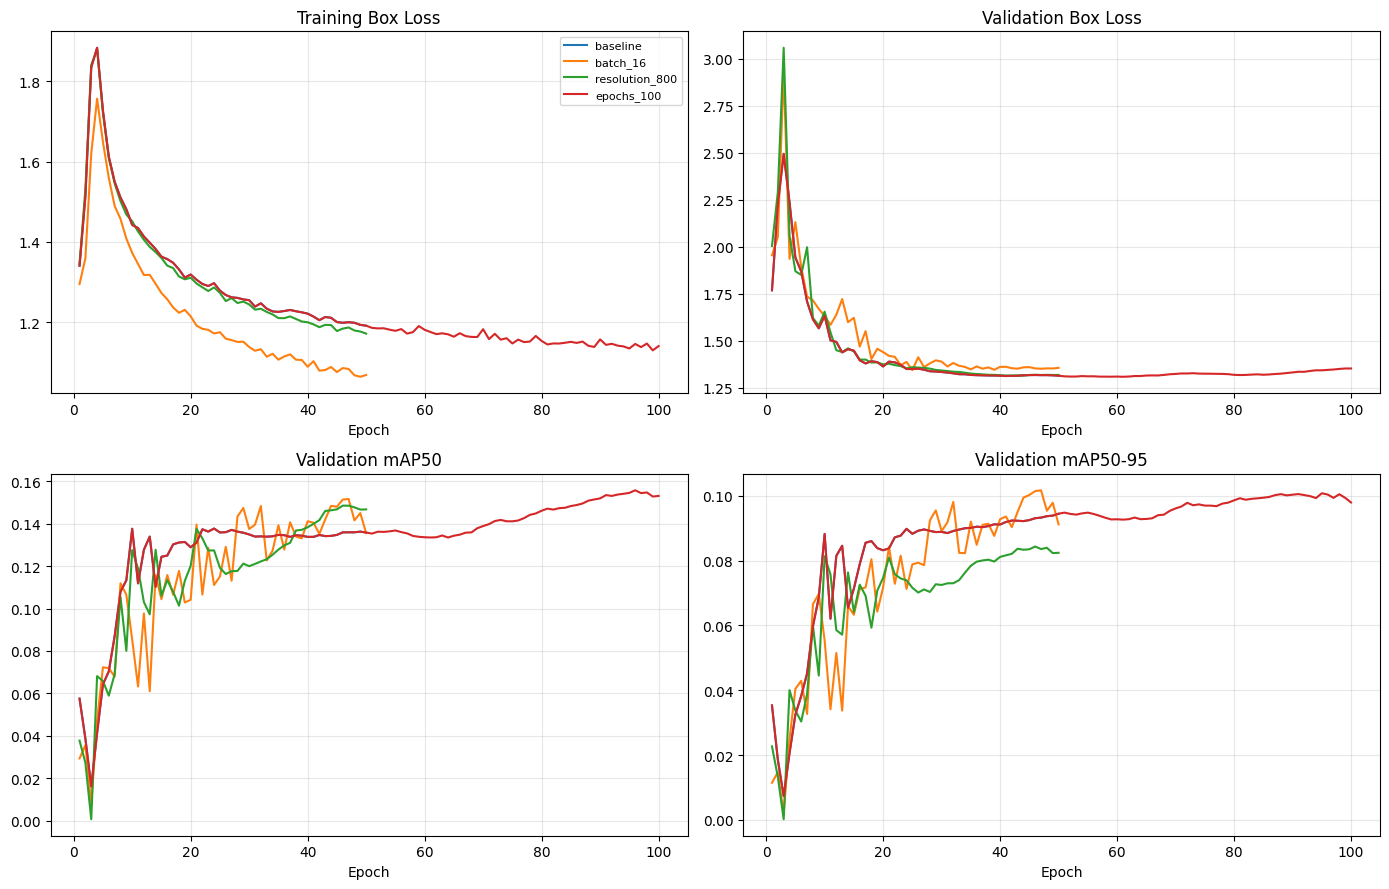

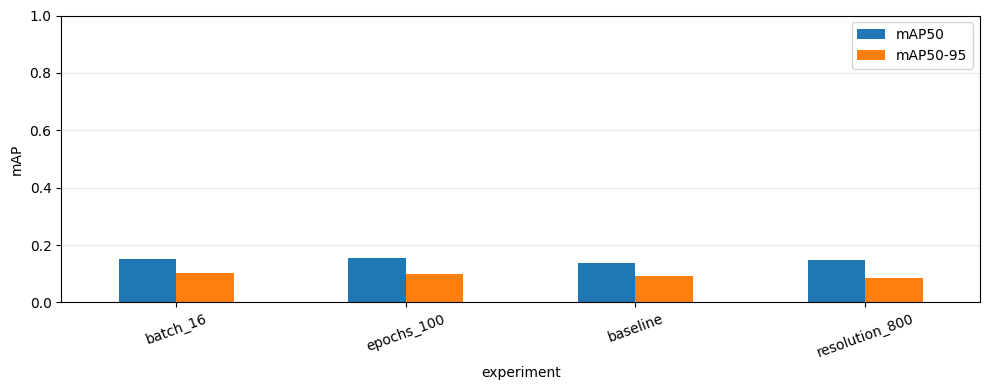

In [ ]:
columns = {
    "train/box_loss": "Training Box Loss",
    "val/box_loss": "Validation Box Loss",
    "metrics/mAP50(B)": "Validation mAP50",
    "metrics/mAP50-95(B)": "Validation mAP50-95"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for name, run_dir in run_dirs.items():
    history = pd.read_csv(run_dir / "results.csv")
    history.columns = history.columns.str.strip()

    for ax, (column, title) in zip(axes.flat, columns.items()):
        ax.plot(history["epoch"], history[column], label=name)
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

results.set_index("experiment")[["mAP50", "mAP50-95"]].plot.bar(
    figsize=(10, 4), rot=20
)
plt.ylabel("mAP")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Selected configuration and validation plots

,experiment,imgsz,epochs,batch,Precision,Recall,mAP50,mAP50-95,train_minutes
0,batch_16,640,50,16,0.4018,0.1379,0.1506,0.1011,45.1038


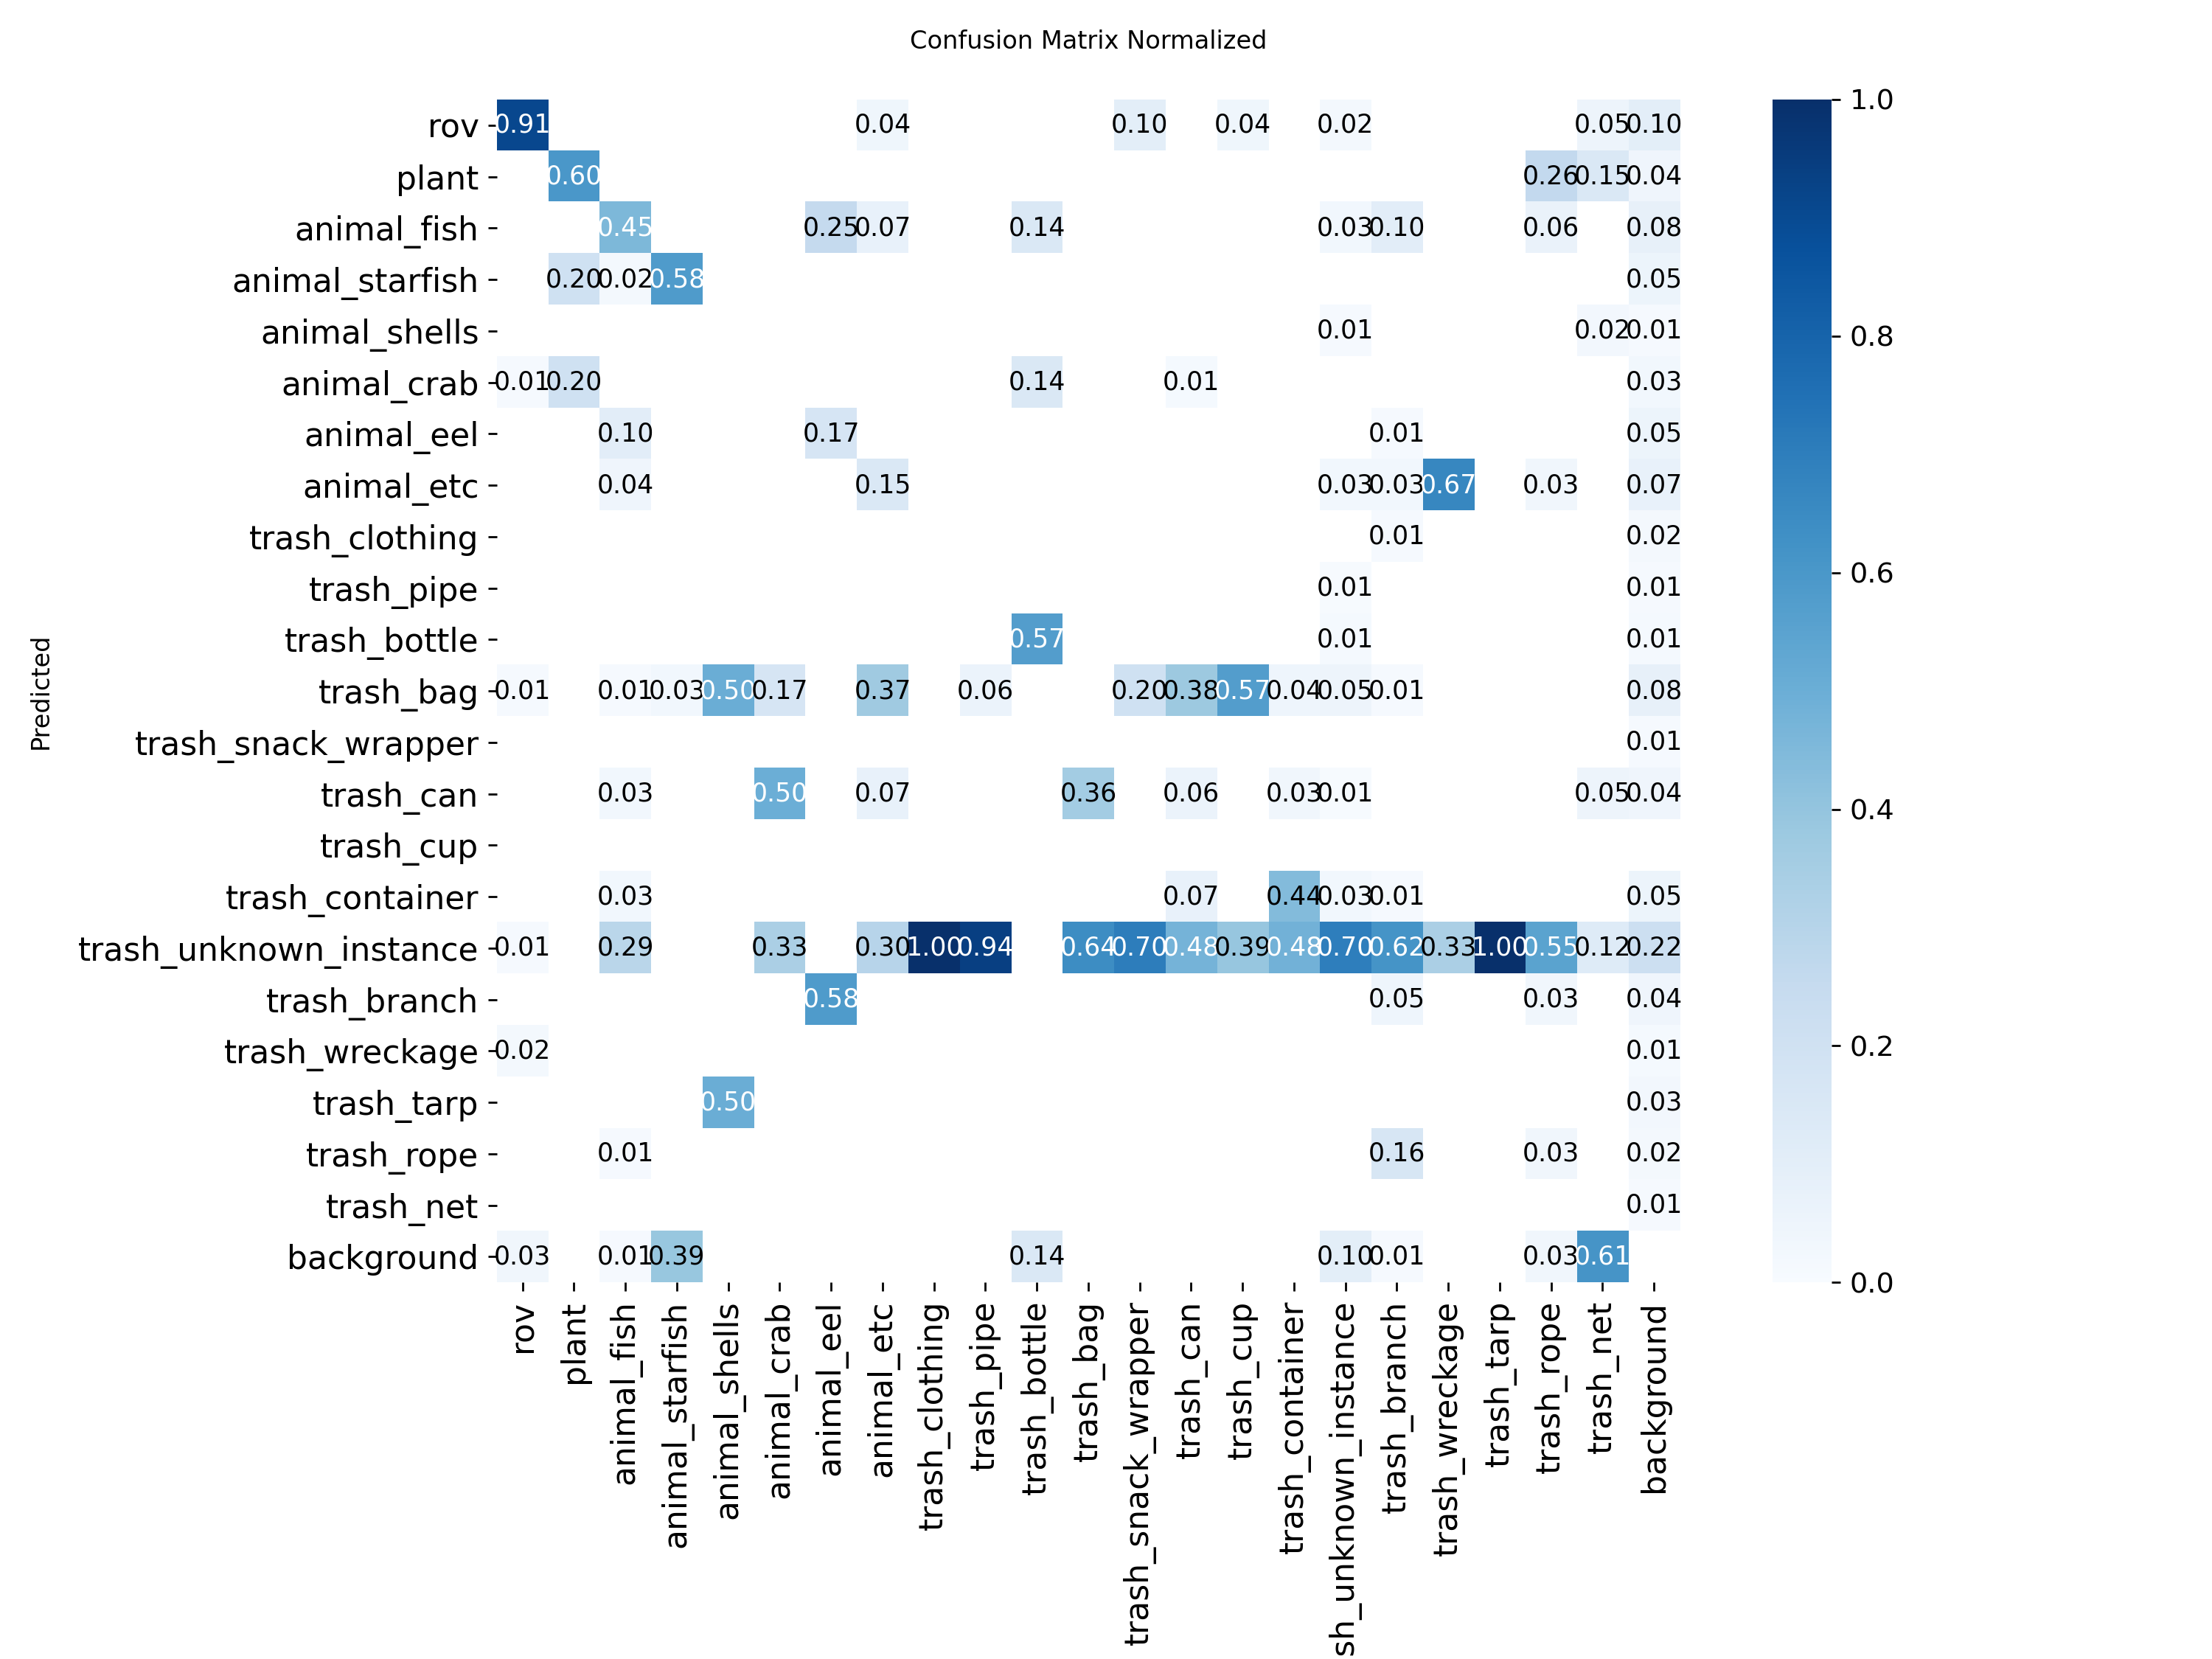

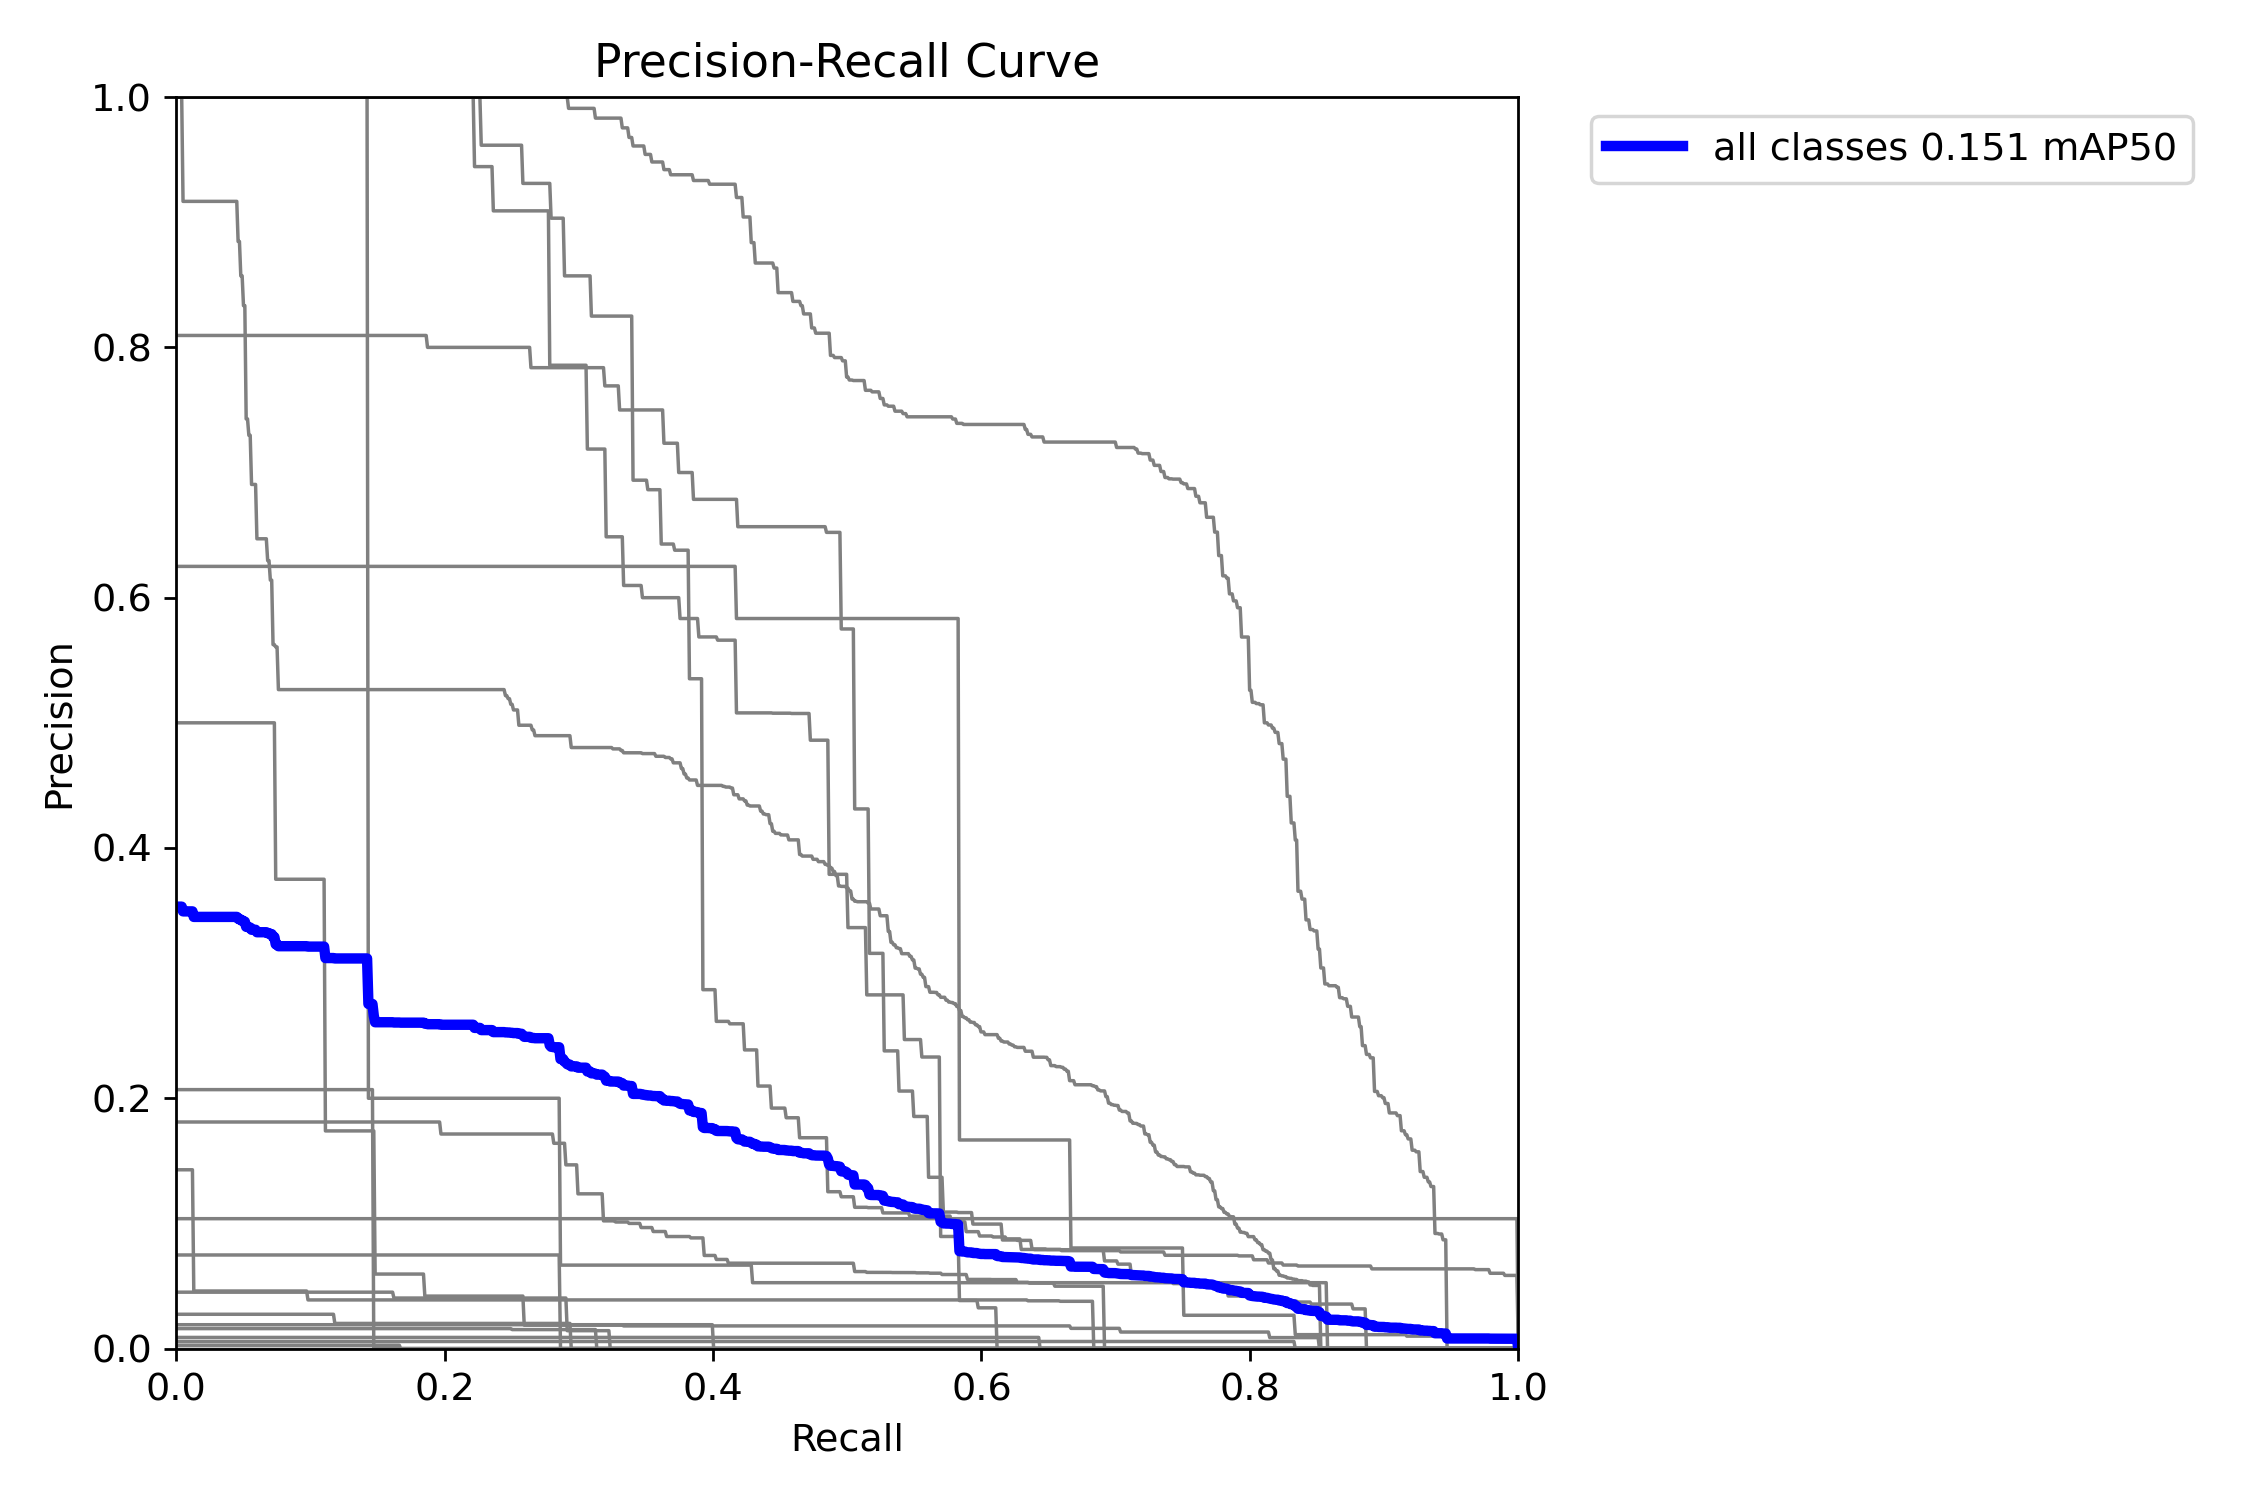

In [ ]:
best = results.iloc[0]
best_model = YOLO(str(Path(best["run_dir"]) / "weights/best.pt"))
best_eval_dir = Path(best["eval_dir"])

display(results.iloc[[0]].drop(columns=["run_dir", "eval_dir"]).round(4))

for filename in ["confusion_matrix_normalized.png", "BoxPR_curve.png"]:
    display(Image.open(best_eval_dir / filename))

#### Native test metrics

In [ ]:
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=int(best["imgsz"]),
    batch=8,
    device=DEVICE,
    workers=0,
    conf=0.001,
    iou=0.7,
    plots=True,
    project=str(RUNS / "test_evaluation"),
    name=str(best["experiment"])
)

test_results = pd.DataFrame([{
    "experiment": best["experiment"],
    "split": "test",
    "Precision": float(test_metrics.box.mp),
    "Recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50-95": float(test_metrics.box.map)
}])

test_results.to_csv(RUNS / "test_results.csv", index=False)

display(test_results.round(4))

Ultralytics 8.4.198  Python-3.13.3 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4080 SUPER, 16376MiB)
YOLO11n summary (fused): 101 layers, 2,602,154 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 93.4±17.8 MB/s, size: 23.8 KB)
val: Scanning <project_dir>\Project_part1_2.0\Project_part1\dataset\video_split\yolo\labels\test... 993 images, 42 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 993/993 1.7Kit/s 0.6s0.1s
val: New cache created: <project_dir>\Project_part1_2.0\Project_part1\dataset\video_split\yolo\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 28.8it/s 4.3s0.1s
                   all        993       1653      0.181      0.183      0.113     0.0729
                   rov        301        330       0.38      0.685      0.538      0.373
                 plant         66         66      0.163      0.167     0.0613     0.0258
           animal_fish        105     

,experiment,split,Precision,Recall,mAP50,mAP50-95
0,batch_16,test,0.1813,0.183,0.1132,0.0729


#### Ground truth and test predictions

Results saved to <project_dir>\YOLO\runs_yolo11\predictions


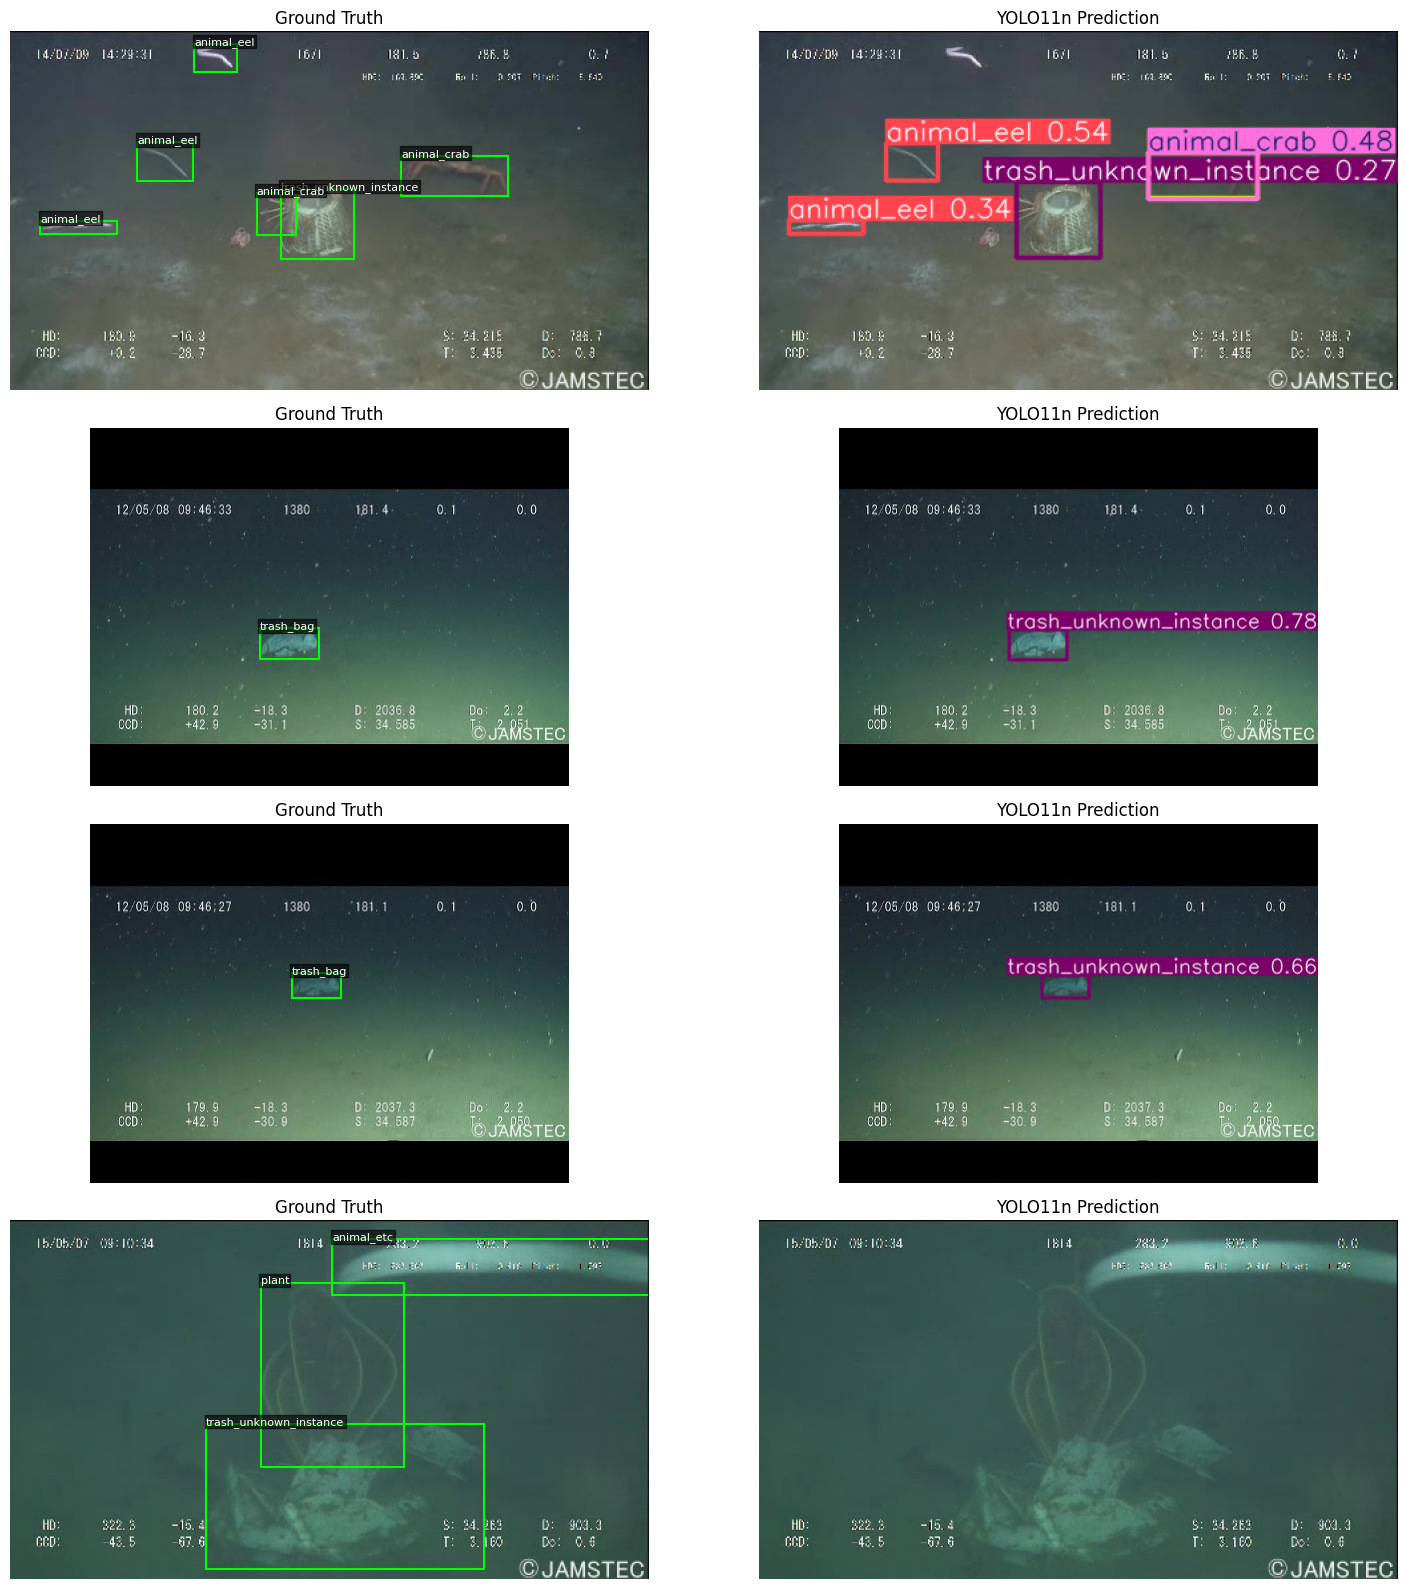

In [ ]:
val_items = annotations["test"]["images"]
indices = torch.linspace(0, len(val_items) - 1, steps=4).long().tolist()
selected = [val_items[i] for i in indices]

sources = [
    str(DATASET / "images/test" / item["file_name"])
    for item in selected
]

predictions = best_model.predict(
    source=sources,
    imgsz=int(best["imgsz"]),
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(RUNS),
    name="predictions",
    verbose=False
)

fig, axes = plt.subplots(len(selected), 2, figsize=(16, 4 * len(selected)))

for row, (item, prediction) in enumerate(zip(selected, predictions)):
    image = Image.open(DATASET / "images/test" / item["file_name"])
    width, height = image.size

    ax = axes[row, 0]
    ax.imshow(image)

    label_path = (
        DATASET / "labels/test" / Path(item["file_name"]).with_suffix(".txt")
    )

    for line in label_path.read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x = (xc - bw / 2) * width
        y = (yc - bh / 2) * height

        ax.add_patch(Rectangle(
            (x, y), bw * width, bh * height,
            fill=False, edgecolor="lime", linewidth=1.5
        ))
        ax.text(
            x, y, names[int(cls)], color="white", fontsize=8,
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1}
        )

    ax.set_title("Ground Truth")
    ax.axis("off")

    axes[row, 1].imshow(prediction.plot()[..., ::-1])
    axes[row, 1].set_title("YOLO11n Prediction")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

#### Supplementary YOLO11l validation and test results

The saved table comes from the completed COCO-pretrained fine-tuning run `20261114_013619_b63e6b`. The Ultralytics evaluation uses 640 px, batch 8, FP32, a confidence floor of 0.001 and NMS IoU of 0.70. Precision and Recall use the best mean-F1 operating point for each model and split. To repeat the evaluation with the saved checkpoint, open the project folder or its `YOLO` subfolder. Running the training cell first evaluates the new checkpoint instead.

In [ ]:
from pathlib import Path

import pandas as pd
from IPython.display import display
from ultralytics import YOLO

checkpoint = globals().get("YOLO11L_BEST")
if checkpoint is None:
    # Use the completed COCO-pretrained run when viewing the reproduction from a fresh kernel.
    relative_run = Path("runs_yolo_comparison/20261114_013619_b63e6b")
    run = next(
        (candidate for base in (Path.cwd(), Path.cwd().parent)
         if (candidate := base / relative_run).is_dir()),
        None,
    )
    if run is None:
        raise FileNotFoundError("Open the project folder or run the new fine-tuning cell first.")
    checkpoint = run / "training/YOLO11l/weights/best.pt"
    data_yaml = run / "yolo/data.yaml"
else:
    run = YOLO11L_RUN
    data_yaml = YOLO11L_DATA_YAML

if not Path(checkpoint).is_file() or not data_yaml.is_file():
    raise FileNotFoundError(f"Expected a trained checkpoint and split configuration: {checkpoint}, {data_yaml}")

model = YOLO(str(checkpoint))
records = []
for split in ("val", "test"):
    scores = model.val(
        data=str(data_yaml), split=split, imgsz=640, batch=8,
        device=0, workers=0, quantize=32, conf=0.001, iou=0.70,
        max_det=300, plots=False, verbose=False,
        project=str(run / "evaluation"), name=split,
    ).box
    records.append({
        "Model": "YOLO11l (COCO fine-tuned)", "Split": split,
        "Precision": float(scores.mp), "Recall": float(scores.mr),
        "mAP50": float(scores.map50), "mAP50–95": float(scores.map),
    })

results_11l = pd.DataFrame(records)
results_11l.to_csv(run / "val_test_metrics.csv", index=False)
display(results_11l.round(4))

Model,Split,Precision,Recall,mAP50,mAP50–95
YOLO11l (COCO fine-tuned),val,0.4226,0.1535,0.1681,0.0982
YOLO11l (COCO fine-tuned),test,0.1759,0.1442,0.0981,0.0598


**Held-out test comparison using Ultralytics**

| Model | Precision | Recall | mAP50 | mAP50–95 |
|---|---:|---:|---:|---:|
| YOLO11n (COCO fine-tuned) | 18.13% | 18.30% | 11.32% | 7.29% |
| YOLO11l (COCO fine-tuned) | 17.59% | 14.42% | 9.81% | 5.98% |

YOLO11l's test mAP50–95 was 1.31 percentage points lower under the shared training settings on this split. Section 5.3 presents the unified COCOeval comparison.

### 5.2 Faster R-CNN ablations

The 480 px COCO-pretrained ResNet-50-FPN v2 had the best validation AP of the four primary runs and was selected for the unified comparison. Its saved test AP was 0.1500, versus 0.1102 for the 800 px COCO reference and 0.0604 for the 800 px ImageNet-only run. MobileNetV3 achieved 0.1112 with a smaller model. In the native Faster R-CNN benchmark, the 480 px model took 39.5 ms per image, versus 65.4 ms for the 800 px reference and 12.8 ms for MobileNetV3. These times describe the Faster R-CNN runs at batch size 1 on their original hardware.

At a common score floor of 0.001, the 800 px reference had validation AP 0.1037. Photometric and multi-scale augmentation reached 0.1058, and mosaic reached 0.1124. Neither met the 0.12 adoption threshold. The much higher score when the reference was evaluated on its own training frames (0.780, first 1,000 frames at score floor 0.05) points to a generalisation gap.

A control run tests whether the low scores come from the training or from the split. Trained identically on the original frame-level split, where 97% of the validation images come from training videos, the same configuration reaches AP@[.50:.95] 0.476 and AP50 0.679 on that validation set, above the published X-101-FPN baseline of 0.345 and 0.554 (Table FR4, Figure FR6).

In [ ]:
RUN_LABELS = {
    "r50v2_coco_800": "R50-FPN v2, COCO, 800 (reference)",
    "r50v2_imagenet_800": "R50-FPN v2, ImageNet only, 800",
    "r50v2_coco_480": "R50-FPN v2, COCO, 480 (final)",
    "mnv3_coco_800": "MobileNetV3-FPN, COCO, 800",
}
# Fixed categorical order: each run keeps its colour in every chart.
RUN_COLORS = {"r50v2_coco_800": "#2a78d6", "r50v2_imagenet_800": "#eb6834",
              "r50v2_coco_480": "#1baf7a", "mnv3_coco_800": "#eda100"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e2e1dc", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})


def read_csv(path):
    with open(path, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def column(rows, key):
    return np.array([float(r[key]) if r[key] != "" else np.nan for r in rows])


history = {r: read_csv(FRCNN_RUNS / r / "results.csv") for r in RUN_LABELS}
test = {r: read_json(FRCNN_RUNS / r / "eval_test" / "metrics.json") for r in RUN_LABELS}
summary = {r: read_json(FRCNN_RUNS / r / "summary.json") for r in RUN_LABELS}

In [ ]:
def f3(x):
    return f"{x:.3f}"


lines = ["| Model | Val mAP | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP_S | AP_M | AP_L | P | R | ms/img | FPS | Params (M) |",
         "|---|---|---|---|---|---|---|---|---|---|---|---|---|"]
for r, label in RUN_LABELS.items():
    c, pr, sp = test[r]["coco"], test[r]["pr_iou50"]["best_f1"], test[r]["speed"]
    cells = [label, f3(summary[r]["best_val_mAP50_95"]), f3(c["mAP50_95"]), f3(c["mAP50"]), f3(c["mAP75"]),
             f3(c["mAP_small"]), f3(c["mAP_medium"]), f3(c["mAP_large"]), f3(pr["precision"]), f3(pr["recall"]),
             f"{sp['ms_per_img_mean']:.1f}", f"{sp['fps']:.1f}", f"{test[r]['params_M']:.1f}"]
    lines.append("| " + " | ".join(cells) + " |")
lines.append("| Hong et al. [2020], X-101-FPN, original split\\* | - | 0.345 | 0.554 | 0.381 | 0.276 | 0.362 | 0.514 | - | - | - | - | - |")
display(Markdown("**Table FR1.** Faster R-CNN on the test split (993 images). Val mAP is the selection metric.\n\n"
                 + "\n".join(lines)
                 + "\n\n\\* Quoted from Hong et al. (instance version, original frame-level split), "
                   "so not directly comparable with our video-disjoint split; Table FR4 compares on their split."))

**Table FR1.** Faster R-CNN on the test split (993 images). Val mAP is the selection metric.

| Model | Val mAP | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP_S | AP_M | AP_L | P | R | ms/img | FPS | Params (M) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| R50-FPN v2, COCO, 800 (reference) | 0.090 | 0.110 | 0.170 | 0.129 | 0.218 | 0.160 | 0.114 | 0.175 | 0.304 | 65.4 | 15.3 | 43.4 |
| R50-FPN v2, ImageNet only, 800 | 0.064 | 0.060 | 0.122 | 0.053 | 0.139 | 0.105 | 0.045 | 0.316 | 0.131 | 65.0 | 15.4 | 43.4 |
| R50-FPN v2, COCO, 480 (final) | 0.103 | 0.150 | 0.233 | 0.165 | 0.245 | 0.218 | 0.160 | 0.188 | 0.327 | 39.5 | 25.3 | 43.4 |
| MobileNetV3-FPN, COCO, 800 | 0.100 | 0.111 | 0.181 | 0.117 | 0.160 | 0.179 | 0.130 | 0.232 | 0.252 | 12.8 | 78.4 | 19.1 |
| Hong et al. [2020], X-101-FPN, original split\* | - | 0.345 | 0.554 | 0.381 | 0.276 | 0.362 | 0.514 | - | - | - | - | - |

\* Quoted from Hong et al. (instance version, original frame-level split), so not directly comparable with our video-disjoint split; Table FR4 compares on their split.

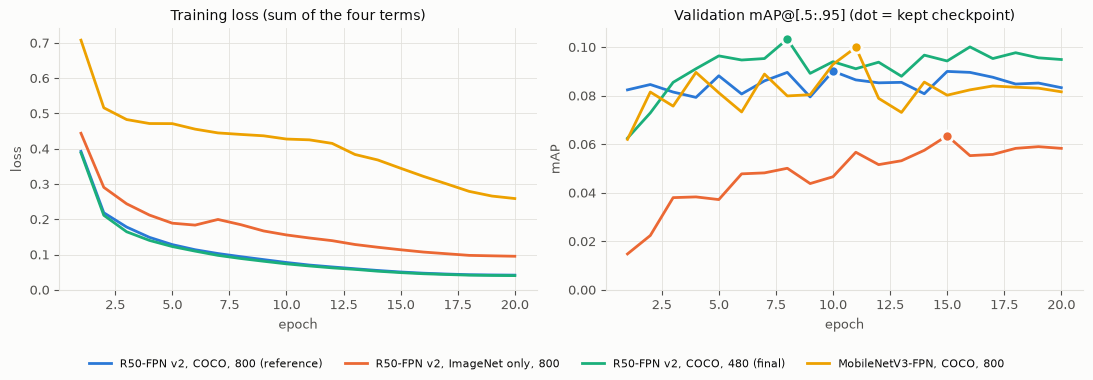

**Figure FR1.** For the COCO-initialised models, training loss keeps falling while validation mAP stops improving after a few epochs: they fit the training videos but do not carry that gain over to unseen videos. The ImageNet-only model, whose detection heads start from scratch, improves until epoch 15.

In [ ]:
fig, (ax_loss, ax_map) = plt.subplots(1, 2, figsize=(11, 3.8))
for r, label in RUN_LABELS.items():
    h, color = history[r], RUN_COLORS[r]
    epochs, val = column(h, "epoch"), column(h, "mAP50_95")
    ax_loss.plot(epochs, column(h, "loss"), color=color, lw=2, label=label)
    ax_map.plot(epochs, val, color=color, lw=2)
    best = int(np.nanargmax(val))
    ax_map.plot(epochs[best], val[best], "o", ms=8, color=color, mec=SURFACE, mew=2)
ax_loss.set(title="Training loss (sum of the four terms)", xlabel="epoch", ylabel="loss", ylim=(0, None))
ax_map.set(title="Validation mAP@[.5:.95] (dot = kept checkpoint)", xlabel="epoch", ylabel="mAP", ylim=(0, None))
handles, labels = ax_loss.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIGS / "fig1_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
display(Markdown("**Figure FR1.** For the COCO-initialised models, training loss keeps falling while validation mAP "
                 "stops improving after a few epochs: they fit the training videos but do not carry that gain over "
                 "to unseen videos. The ImageNet-only model, whose detection heads start from scratch, "
                 "improves until epoch 15."))

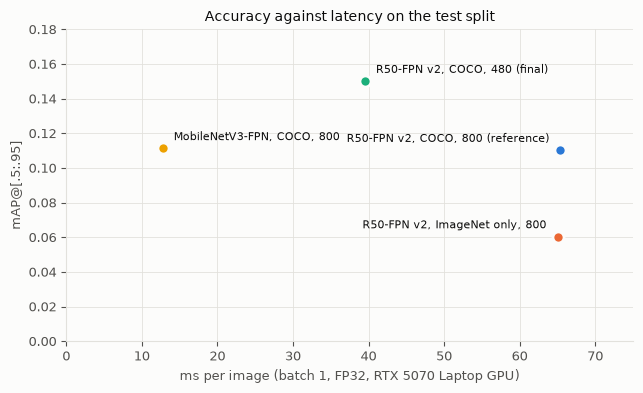

**Figure FR2.** The 480 px model is both the most accurate and 1.65x faster than the 800 px reference; MobileNetV3 matches the reference accuracy at about a fifth of its latency.

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for r, label in RUN_LABELS.items():
    x, y = test[r]["speed"]["ms_per_img_mean"], test[r]["coco"]["mAP50_95"]
    ax.scatter(x, y, s=64, color=RUN_COLORS[r], edgecolor=SURFACE, linewidth=2, zorder=3)
    right = x > 50
    ax.annotate(label, (x, y), xytext=(-8 if right else 8, 6), textcoords="offset points",
                ha="right" if right else "left", fontsize=8, color=INK)
ax.set(title="Accuracy against latency on the test split", xlabel="ms per image (batch 1, FP32, RTX 5070 Laptop GPU)",
       ylabel="mAP@[.5:.95]", xlim=(0, 75), ylim=(0, 0.18))
fig.tight_layout()
fig.savefig(FIGS / "fig2_accuracy_vs_latency.png", dpi=200, bbox_inches="tight")
plt.show()
display(Markdown("**Figure FR2.** The 480 px model is both the most accurate and 1.65x faster than the 800 px reference; "
                 "MobileNetV3 matches the reference accuracy at about a fifth of its latency."))

In [ ]:
rows = read_csv(FRCNN_RUNS / "tables" / "validation_tuning_and_diagnosis.csv")
lines = ["| Run | Augmentation | Epochs | Evaluated on | Score thr. | Kept epoch | mAP@[.5:.95] | mAP@.5 | AR100 |",
         "|---|---|---|---|---|---|---|---|---|"]
for r in rows:
    lines.append(f"| {r['run']} | {r['augmentation']} | {r['epochs']} | {r['split']} | {r['score_thresh']} | "
                 f"{r['best_epoch']} | {float(r['mAP50_95']):.3f} | {float(r['mAP50']):.3f} | {float(r['AR100']):.3f} |")
display(Markdown("**Table FR2.** Augmentation trials and diagnosis with the 800 px model. Before the trials we fixed "
                 "a validation mAP@[.5:.95] of 0.12 as the bar for adopting a change; neither trial reached it. "
                 "The training-image row shows the size of the generalisation gap.\n\n" + "\n".join(lines)))

**Table FR2.** Augmentation trials and diagnosis with the 800 px model. Before the trials we fixed a validation mAP@[.5:.95] of 0.12 as the bar for adopting a change; neither trial reached it. The training-image row shows the size of the generalisation gap.

| Run | Augmentation | Epochs | Evaluated on | Score thr. | Kept epoch | mAP@[.5:.95] | mAP@.5 | AR100 |
|---|---|---|---|---|---|---|---|---|
| r50v2_coco_800 | flip | 20 | val | 0.05 | 10 | 0.090 | 0.145 | 0.194 |
| r50v2_coco_800 | flip | 20 | val | 0.001 | 10 | 0.104 | 0.170 | 0.381 |
| r50v2_coco_800 | flip | 20 | train (first 1000 images) | 0.05 | 10 | 0.780 | 0.988 | 0.819 |
| tune_r50v2_strong | flip + photometric + multi-scale 640-800 | 12 | val | 0.05 | 9 | 0.095 | 0.159 | 0.249 |
| tune_r50v2_strong | flip + photometric + multi-scale 640-800 | 12 | val | 0.001 | 9 | 0.106 | 0.178 | 0.451 |
| mosaic_r50v2_800 | flip + mosaic p=0.5 | 20 | val | 0.05 | 10 | 0.105 | 0.191 | 0.242 |
| mosaic_r50v2_800 | flip + mosaic p=0.5 | 20 | val | 0.001 | 10 | 0.112 | 0.204 | 0.483 |

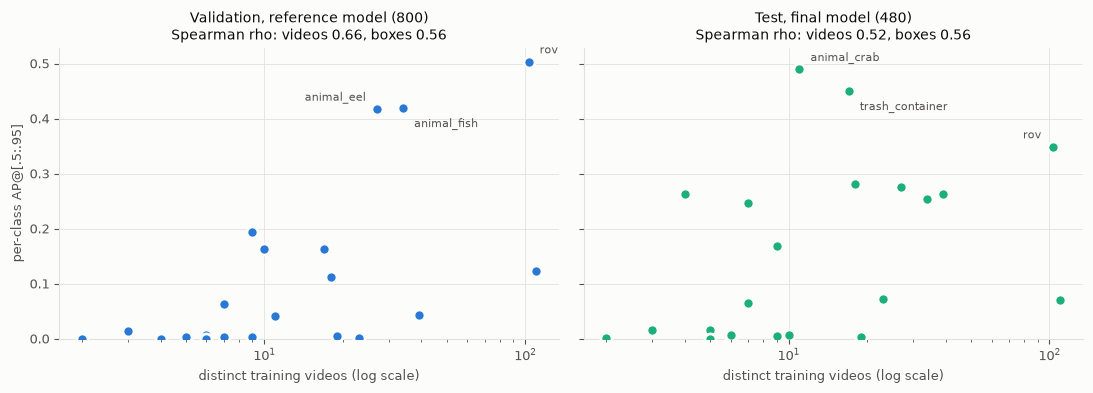

**Figure FR3.** Each dot is one of the 22 classes; the three best are labelled. On the validation split, per-class AP follows the number of distinct training videos more closely than the number of boxes. On the test split the relation is weaker, and a few classes from only a handful of videos still score well (e.g. `trash_bottle`: 4 training videos, test AP 0.26).

In [ ]:
def avg_rank(x):
    return np.array([(x < v).sum() + ((x == v).sum() + 1) / 2 for v in x])


def spearman(a, b):
    return float(np.corrcoef(avg_rank(a), avg_rank(b))[0, 1])


cls = read_csv(FRCNN_RUNS / "tables" / "per_class_videos_and_ap.csv")
videos, boxes = column(cls, "train_videos"), column(cls, "train_boxes")
panels = [("val_AP50_95_r50v2_coco_800", "r50v2_coco_800", "Validation, reference model (800)"),
          ("test_AP50_95_r50v2_coco_480", "r50v2_coco_480", "Test, final model (480)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, (key, run, title) in zip(axes, panels):
    ap = column(cls, key)
    ax.scatter(videos, ap, s=64, color=RUN_COLORS[run], edgecolor=SURFACE, linewidth=2, zorder=3)
    # Label the three best classes: right-above, right-below, left-above, so close points keep apart.
    for (dx, dy, ha), i in zip([(8, 6, "left"), (8, -14, "left"), (-8, 6, "right")], np.argsort(-ap)[:3]):
        ax.annotate(cls[i]["class"], (videos[i], ap[i]), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, fontsize=8, color=INK_2)
    ax.set_xscale("log")
    ax.set(title=f"{title}\nSpearman rho: videos {spearman(ap, videos):.2f}, boxes {spearman(ap, boxes):.2f}",
           xlabel="distinct training videos (log scale)", ylim=(0, None))
axes[0].set_ylabel("per-class AP@[.5:.95]")
fig.tight_layout()
fig.savefig(FIGS / "fig3_class_ap_vs_videos.png", dpi=200, bbox_inches="tight")
plt.show()
display(Markdown("**Figure FR3.** Each dot is one of the 22 classes; the three best are labelled. On the validation "
                 "split, per-class AP follows the number of distinct training videos more closely than the number of "
                 "boxes. On the test split the relation is weaker, and a few classes from only a handful of videos "
                 "still score well (e.g. `trash_bottle`: 4 training videos, test AP 0.26)."))

In [ ]:
rows = read_csv(FRCNN_RUNS / "tables" / "per_class_ap_test_all_runs.csv")
order = ["r50v2_coco_800", "r50v2_imagenet_800", "r50v2_coco_480", "mnv3_coco_800"]
lines = ["| Class | Test boxes | " + " | ".join(order) + " |", "|---|---|" + "---|" * len(order)]
for r in rows:
    lines.append(f"| {r['class']} | {r['n_gt_test']} | "
                 + " | ".join(f"{float(r['AP50_95_' + o]):.3f}" for o in order) + " |")
display(Markdown("**Table FR3.** Per-class test AP@[.5:.95]. Three classes have a single test box, "
                 "so their AP (and through them the mean) is unstable.\n\n" + "\n".join(lines)))

**Table FR3.** Per-class test AP@[.5:.95]. Three classes have a single test box, so their AP (and through them the mean) is unstable.

| Class | Test boxes | r50v2_coco_800 | r50v2_imagenet_800 | r50v2_coco_480 | mnv3_coco_800 |
|---|---|---|---|---|---|
| rov | 330 | 0.353 | 0.204 | 0.349 | 0.405 |
| plant | 66 | 0.031 | 0.017 | 0.071 | 0.036 |
| animal_fish | 143 | 0.145 | 0.095 | 0.253 | 0.147 |
| animal_starfish | 15 | 0.010 | 0.008 | 0.007 | 0.031 |
| animal_shells | 1 | 0.018 | 0.001 | 0.015 | 0.004 |
| animal_crab | 46 | 0.473 | 0.311 | 0.489 | 0.459 |
| animal_eel | 90 | 0.203 | 0.149 | 0.275 | 0.209 |
| animal_etc | 5 | 0.032 | 0.001 | 0.002 | 0.004 |
| trash_clothing | 1 | 0.003 | 0.000 | 0.001 | 0.000 |
| trash_pipe | 65 | 0.028 | 0.001 | 0.015 | 0.012 |
| trash_bottle | 34 | 0.222 | 0.111 | 0.264 | 0.019 |
| trash_bag | 144 | 0.154 | 0.086 | 0.263 | 0.173 |
| trash_snack_wrapper | 1 | 0.000 | 0.000 | 0.000 | 0.000 |
| trash_can | 98 | 0.269 | 0.189 | 0.281 | 0.218 |
| trash_cup | 14 | 0.000 | 0.000 | 0.001 | 0.010 |
| trash_container | 10 | 0.093 | 0.036 | 0.451 | 0.408 |
| trash_unknown_instance | 435 | 0.088 | 0.053 | 0.071 | 0.091 |
| trash_branch | 60 | 0.239 | 0.055 | 0.169 | 0.183 |
| trash_wreckage | 25 | 0.027 | 0.001 | 0.007 | 0.004 |
| trash_tarp | 13 | 0.005 | 0.001 | 0.005 | 0.007 |
| trash_rope | 16 | 0.016 | 0.003 | 0.065 | 0.002 |
| trash_net | 41 | 0.016 | 0.006 | 0.246 | 0.025 |

**Figure FR4.** Final model on the test split: per-class precision-recall curves at IoU 0.5.

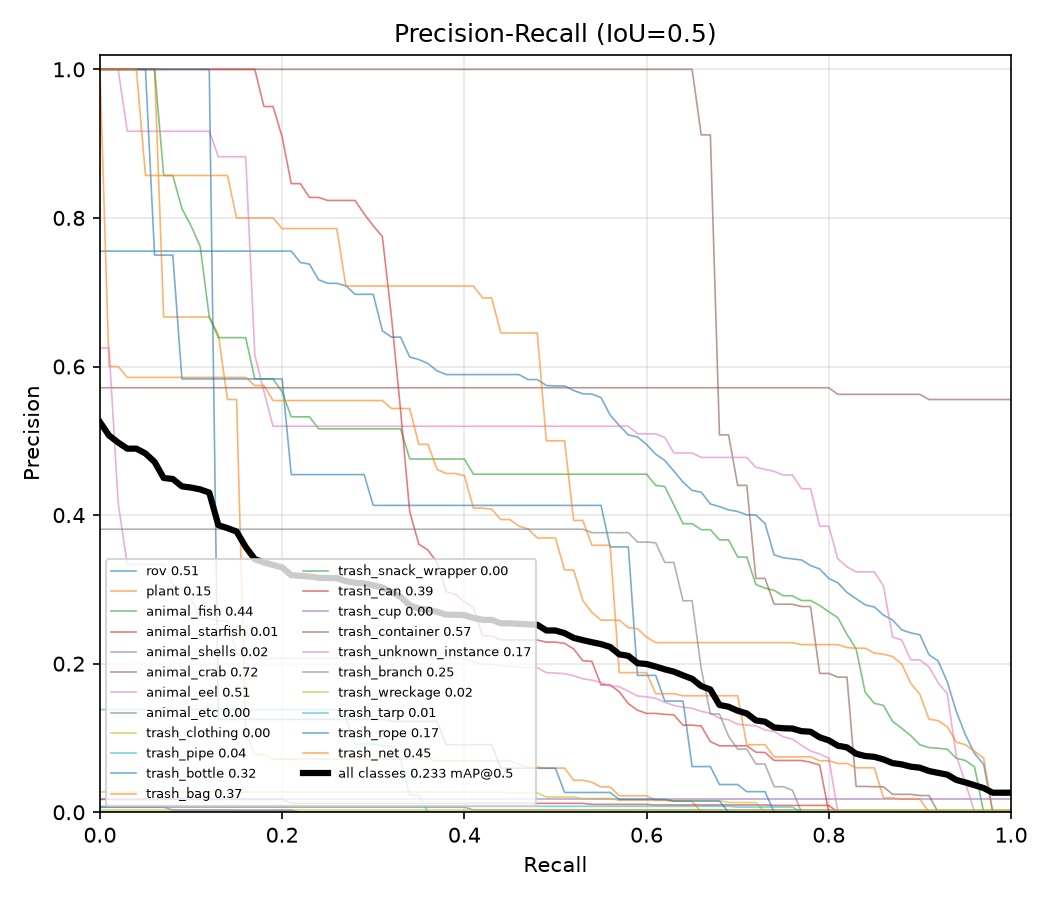

**Figure FR5.** Test images: ground truth (left) next to the final model's detections with score >= 0.5 (right).

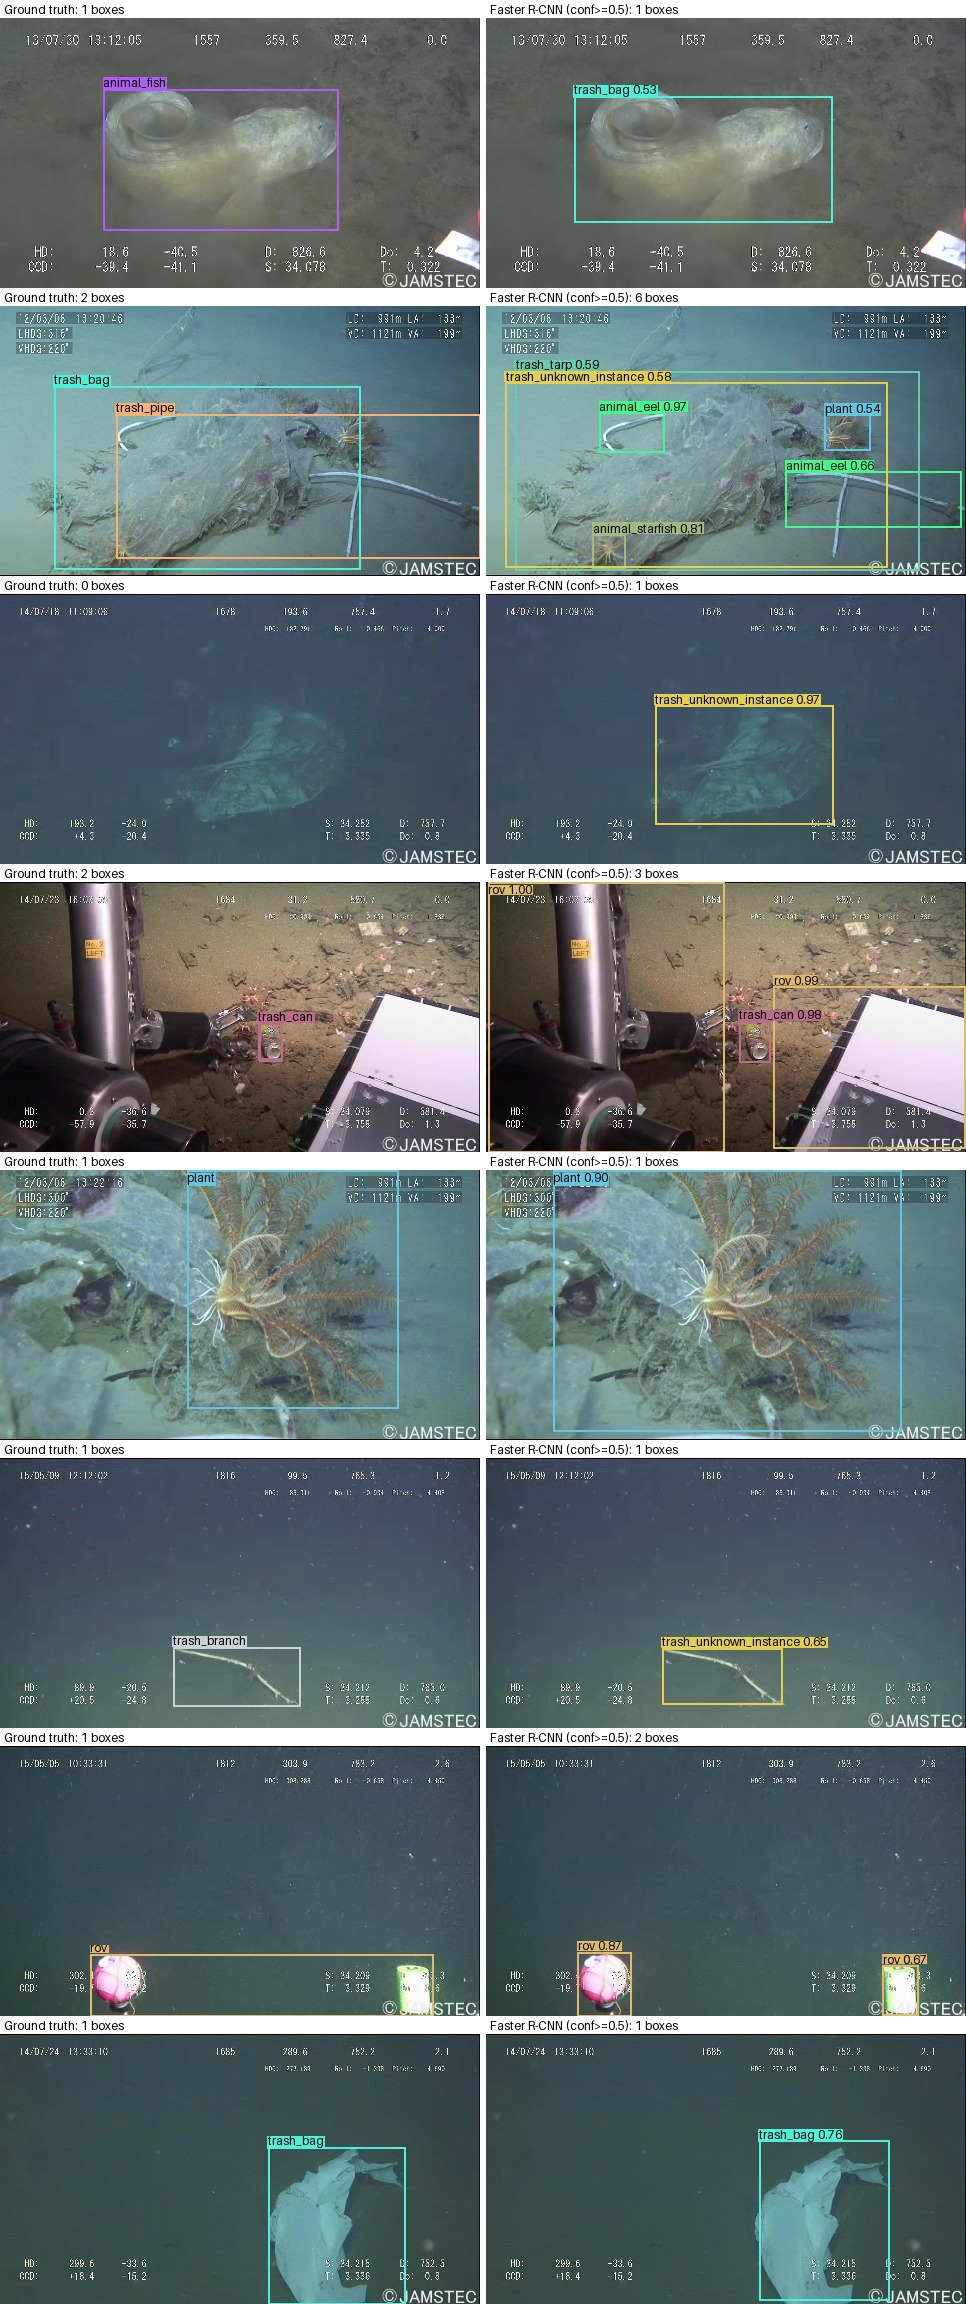

In [ ]:
final = FRCNN_RUNS / "r50v2_coco_480"
display(Markdown("**Figure FR4.** Final model on the test split: per-class precision-recall curves at IoU 0.5."))
display(IPImage(filename=str(final / "eval_test" / "pr_curve.png"), width=520))
display(Markdown("**Figure FR5.** Test images: ground truth (left) next to the final model's detections with score >= 0.5 (right)."))
display(IPImage(filename=str(final / "vis" / "montage.jpg"), width=900))

#### Control: the same model on the original split

Is the low test score a training problem or a property of the split? To check, the final configuration was trained once more, unchanged, on the original TrashCan train/val split. In that split 1,113 of the 1,147 validation images (97%) come from videos that also appear in training. It was evaluated on that validation set, the set the benchmark reports on.

**Table FR4.** ResNet-50-FPN v2, COCO-pretrained, 480 px, identical training on both splits. On the original split the validation set both picks the checkpoint and gives the score, so that number is slightly optimistic.

| Split and evaluation set | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP_S | AP_M | AP_L | P | R |
|---|---|---|---|---|---|---|---|---|
| Video-disjoint split, test (final model) | 0.150 | 0.233 | 0.165 | 0.245 | 0.218 | 0.160 | 0.188 | 0.327 |
| Original split, validation (same configuration) | 0.476 | 0.679 | 0.529 | 0.402 | 0.506 | 0.673 | 0.744 | 0.641 |
| Original split, Hong et al. [2020], X-101-FPN\* | 0.345 | 0.554 | 0.381 | 0.276 | 0.362 | 0.514 | - | - |

\* Quoted from Hong et al., Table 1 (instance version).

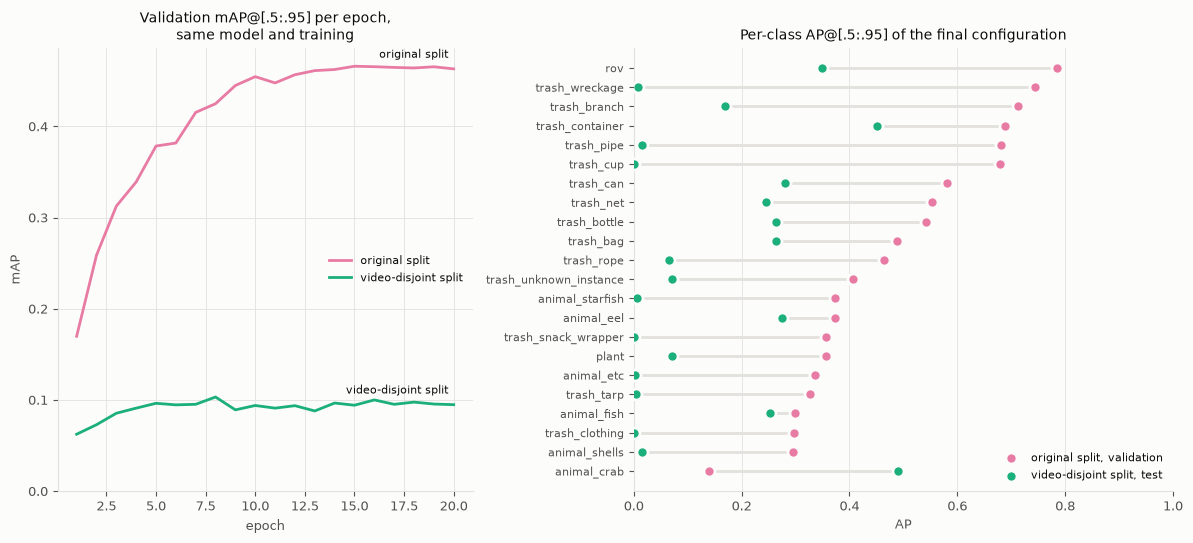

**Figure FR6.** Left: when the validation frames come from training videos, validation mAP keeps rising for 15 epochs; with unseen videos it stays near 0.1 from the first epoch. Right: 21 of the 22 classes score higher on the original split (exceptions: `animal_crab`), e.g. `trash_cup` 0.68 against 0.00.

In [ ]:
OFFICIAL_RUN, FINAL_RUN = "official_r50v2_coco_480", "r50v2_coco_480"
OFFICIAL_COLOR = "#e87ba4"  # next slot in the fixed categorical order
official = read_json(FRCNN_RUNS / OFFICIAL_RUN / "diag_official_val" / "metrics.json")
official_hist = read_csv(FRCNN_RUNS / OFFICIAL_RUN / "results.csv")

lines = ["| Split and evaluation set | mAP@[.5:.95] | mAP@.5 | mAP@.75 | AP_S | AP_M | AP_L | P | R |",
         "|---|---|---|---|---|---|---|---|---|"]
for name, m in [("Video-disjoint split, test (final model)", test[FINAL_RUN]),
                ("Original split, validation (same configuration)", official)]:
    c, pr = m["coco"], m["pr_iou50"]["best_f1"]
    lines.append(f"| {name} | {f3(c['mAP50_95'])} | {f3(c['mAP50'])} | {f3(c['mAP75'])} | {f3(c['mAP_small'])} | "
                 f"{f3(c['mAP_medium'])} | {f3(c['mAP_large'])} | {f3(pr['precision'])} | {f3(pr['recall'])} |")
lines.append("| Original split, Hong et al. [2020], X-101-FPN\\* | 0.345 | 0.554 | 0.381 | 0.276 | 0.362 | 0.514 | - | - |")
display(Markdown("**Table FR4.** ResNet-50-FPN v2, COCO-pretrained, 480 px, identical training on both splits. On the "
                 "original split the validation set both picks the checkpoint and gives the score, so that number is "
                 "slightly optimistic.\n\n" + "\n".join(lines)
                 + "\n\n\\* Quoted from Hong et al., Table 1 (instance version)."))

fig, (ax_curve, ax_cls) = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
for hist, color, label in [(official_hist, OFFICIAL_COLOR, "original split"),
                           (history[FINAL_RUN], RUN_COLORS[FINAL_RUN], "video-disjoint split")]:
    epochs, val = column(hist, "epoch"), column(hist, "mAP50_95")
    ax_curve.plot(epochs, val, color=color, lw=2, label=label)
    ax_curve.annotate(label, (epochs[-1], val[-1]), xytext=(-4, 8), textcoords="offset points",
                      ha="right", fontsize=8, color=INK)
ax_curve.set(title="Validation mAP@[.5:.95] per epoch,\nsame model and training", xlabel="epoch", ylabel="mAP",
             ylim=(0, None))
ax_curve.legend(loc="center right", fontsize=8)

off_cls = {r["category"]: float(r["AP50_95"]) for r in read_csv(FRCNN_RUNS / OFFICIAL_RUN / "diag_official_val" / "per_class_ap.csv")}
vid_cls = {r["category"]: float(r["AP50_95"]) for r in read_csv(FRCNN_RUNS / FINAL_RUN / "eval_test" / "per_class_ap.csv")}
names = sorted(off_cls, key=off_cls.get)
y = np.arange(len(names))
ax_cls.hlines(y, [vid_cls[n] for n in names], [off_cls[n] for n in names], color=GRID, lw=2, zorder=1)
ax_cls.scatter([off_cls[n] for n in names], y, s=64, color=OFFICIAL_COLOR, edgecolor=SURFACE, linewidth=2,
               zorder=3, label="original split, validation")
ax_cls.scatter([vid_cls[n] for n in names], y, s=64, color=RUN_COLORS[FINAL_RUN], edgecolor=SURFACE, linewidth=2,
               zorder=3, label="video-disjoint split, test")
ax_cls.set_yticks(y, names, fontsize=8)
ax_cls.set(title="Per-class AP@[.5:.95] of the final configuration", xlabel="AP", xlim=(0, 1))
ax_cls.grid(axis="y", visible=False)
ax_cls.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "fig6_original_vs_video_split.png", dpi=200, bbox_inches="tight")
plt.show()
higher = [n for n in names if off_cls[n] > vid_cls[n]]
lower = ", ".join(f"`{n}`" for n in names if n not in higher) or "none"
display(Markdown(f"**Figure FR6.** Left: when the validation frames come from training videos, validation mAP keeps "
                 f"rising for 15 epochs; with unseen videos it stays near 0.1 from the first epoch. Right: "
                 f"{len(higher)} of the {len(names)} classes score higher on the original split "
                 f"(exceptions: {lower}), e.g. `trash_cup` {off_cls['trash_cup']:.2f} against "
                 f"{vid_cls['trash_cup']:.2f}."))

### 5.3 Head-to-head comparison

Under the unified protocol, Faster R-CNN achieved AP@[.50:.95] of **0.1500** and AP50 of **0.2333**. YOLO11n achieved **0.0731** and **0.1140**, respectively. Faster R-CNN also led at IoU 0.75 (0.1648 vs 0.0780). At each model's descriptive best-F1 operating point, the precision gap was small (0.188 vs 0.181), while recall was 0.327 vs 0.186. AR@100 was 0.510 vs 0.309. The accuracy advantage came with a larger model: 43.36 M vs 2.61 M parameters.

The published Faster R-CNN X-101-FPN result on TrashCan-Instance was AP 0.345 and AP50 0.554. The published model used a larger backbone and the original split. The numbers provide benchmark context, but they cannot quantify a gain or loss under our video-disjoint protocol. Section 5.2 adds a like-for-like check: the selected Faster R-CNN configuration, retrained on the original split, reaches 0.476 and 0.679 there (Table FR4). The common test metrics below are the basis for the comparison between our models.

In [ ]:
STATS, EVALS, PR = {}, {}, {}
for m in MODELS:
    STATS[m], EVALS[m] = coco_score(PRED[m])
    PR[m] = precision_recall(PRED[m])

overall = pd.DataFrame({m: {
    "Precision": PR[m]["precision"], "Recall": PR[m]["recall"], "F1": PR[m]["f1"], "conf @ best F1": PR[m]["conf"],
    "mAP@.5": STATS[m]["mAP50"], "mAP@.75": STATS[m]["mAP75"], "mAP@[.5:.95]": STATS[m]["mAP50_95"],
    "AP small": STATS[m]["AP_small"], "AP medium": STATS[m]["AP_medium"], "AP large": STATS[m]["AP_large"],
    "AR@100": STATS[m]["AR100"],
    "Params (M)": PARAMS_M[m],
} for m in MODELS})
overall.to_csv(OUT / "table_overall.csv")
print(f"Table 5.1  Test set ({len(test_images)} images, {n_videos} unseen videos)")
display(overall.style.format("{:.3f}").format("{:.1f}", subset=pd.IndexSlice[["Params (M)"], :]))

# Reference only: Hong et al. (2020), TrashCan paper, Table 1 (bbox, TrashCan-Instance).
# Their split is the original image-level one (113 videos shared by train and val), so it is not comparable.
paper = pd.DataFrame(
    [["Faster R-CNN X-101-FPN (Hong et al.)", 0.345, 0.554, 0.381, 0.276, 0.362, 0.514],
     ["Mask R-CNN X-101-FPN (Hong et al.)",   0.300, 0.553, 0.294, 0.232, 0.317, 0.486]] +
    [[f"{m} (ours, video split)", STATS[m]["mAP50_95"], STATS[m]["mAP50"], STATS[m]["mAP75"],
      STATS[m]["AP_small"], STATS[m]["AP_medium"], STATS[m]["AP_large"]] for m in MODELS],
    columns=["Model", "AP", "AP50", "AP75", "APs", "APm", "APl"]).set_index("Model")
print("Table 5.2  Comparison with the published TrashCan baseline (different split, reference only)")
display(paper.style.format("{:.3f}"))

Table 5.1  Test set (993 images, 47 unseen videos)


,YOLO11n,Faster R-CNN
Precision,0.181,0.188
Recall,0.186,0.327
F1,0.139,0.213
conf @ best F1,0.160,0.175
mAP@.5,0.114,0.233
mAP@.75,0.078,0.165
mAP@[.5:.95],0.073,0.150
AP small,0.142,0.245
AP medium,0.103,0.218
AP large,0.119,0.160


Table 5.2  Comparison with the published TrashCan baseline (different split, reference only)


,AP,AP50,AP75,APs,APm,APl
Model,,,,,,
Faster R-CNN X-101-FPN (Hong et al.),0.345,0.554,0.381,0.276,0.362,0.514
Mask R-CNN X-101-FPN (Hong et al.),0.300,0.553,0.294,0.232,0.317,0.486
"YOLO11n (ours, video split)",0.073,0.114,0.078,0.142,0.103,0.119
"Faster R-CNN (ours, video split)",0.150,0.233,0.165,0.245,0.218,0.160


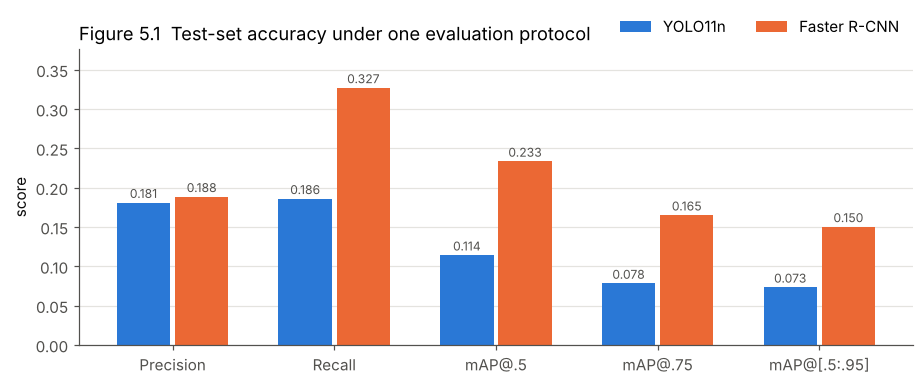

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
metrics = ["Precision", "Recall", "mAP@.5", "mAP@.75", "mAP@[.5:.95]"]
x = np.arange(len(metrics)); w = 0.36
for i, m in enumerate(MODELS):
    vals = overall.loc[metrics, m].values
    bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.03, color=COLORS[m], label=m)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f"{v:.3f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, metrics); ax.set_ylabel("score"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, overall.loc[metrics].values.max() * 1.15)
ax.set_title("Figure 5.1  Test-set accuracy under one evaluation protocol", loc="left")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
fig.tight_layout(); fig.savefig(OUT / "fig5_1_overall.png", dpi=200); plt.show()

#### Per-class and per-size results
Classes are sorted by the number of test boxes. Classes marked † have only 1 test box, so their AP is
either close to 0 or close to 1 and should not be interpreted.

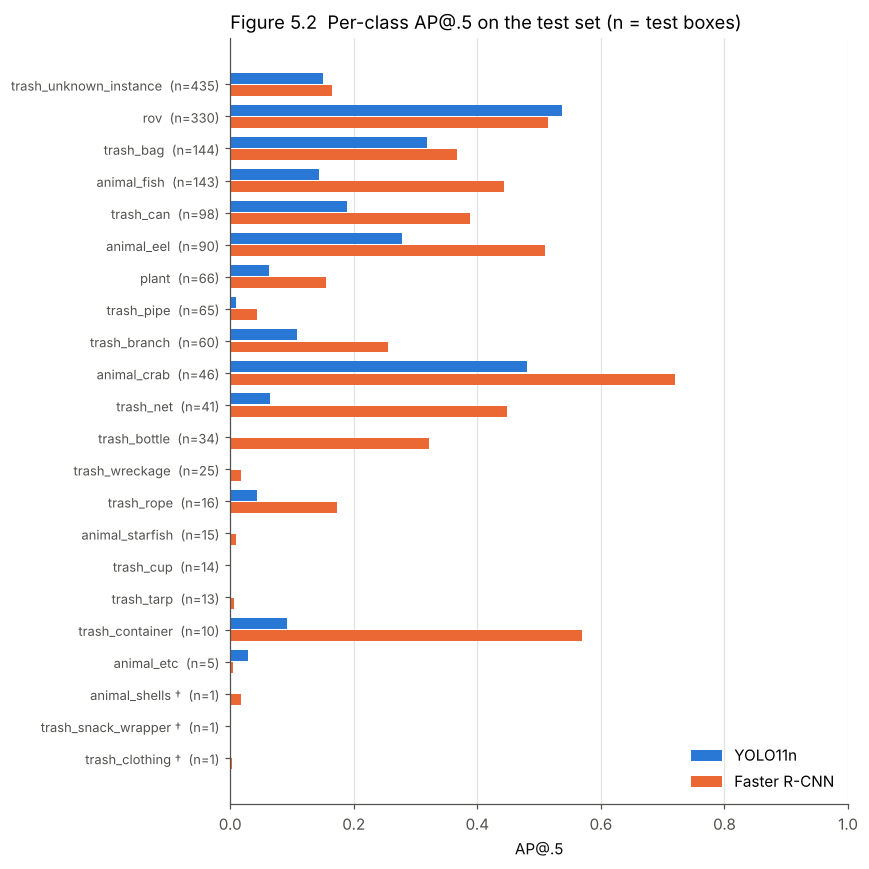

Faster R-CNN has the higher AP@.5 on 17 of 18 classes with >= 10 test boxes.


In [ ]:
pc = {m: per_class_ap(EVALS[m]) for m in MODELS}
per_class = pc[MODELS[0]][["category", "n_gt"]].copy()
for m in MODELS:
    per_class[f"AP50 {m}"] = pc[m]["AP50"]; per_class[f"AP50_95 {m}"] = pc[m]["AP50_95"]
per_class = per_class.sort_values("n_gt", ascending=False).reset_index(drop=True)
per_class.to_csv(OUT / "table_per_class.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(per_class))[::-1]; h = 0.38
for i, m in enumerate(MODELS):
    ax.barh(y + (0.5 - i) * h, per_class[f"AP50 {m}"].fillna(0), h - 0.04, color=COLORS[m], label=m)
labels = [f"{r.category}{' †' if r.n_gt <= 1 else ''}  (n={r.n_gt})" for r in per_class.itertuples()]
ax.set_yticks(y, labels, fontsize=8.5); ax.set_xlabel("AP@.5"); ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title("Figure 5.2  Per-class AP@.5 on the test set (n = test boxes)", loc="left")
fig.tight_layout(); fig.savefig(OUT / "fig5_2_per_class_ap.png", dpi=200); plt.show()

stable = per_class[per_class["n_gt"] >= 10]
wins = (stable[f"AP50 {MODELS[1]}"] > stable[f"AP50 {MODELS[0]}"]).sum()
print(f"Faster R-CNN has the higher AP@.5 on {wins} of {len(stable)} classes with >= 10 test boxes.")

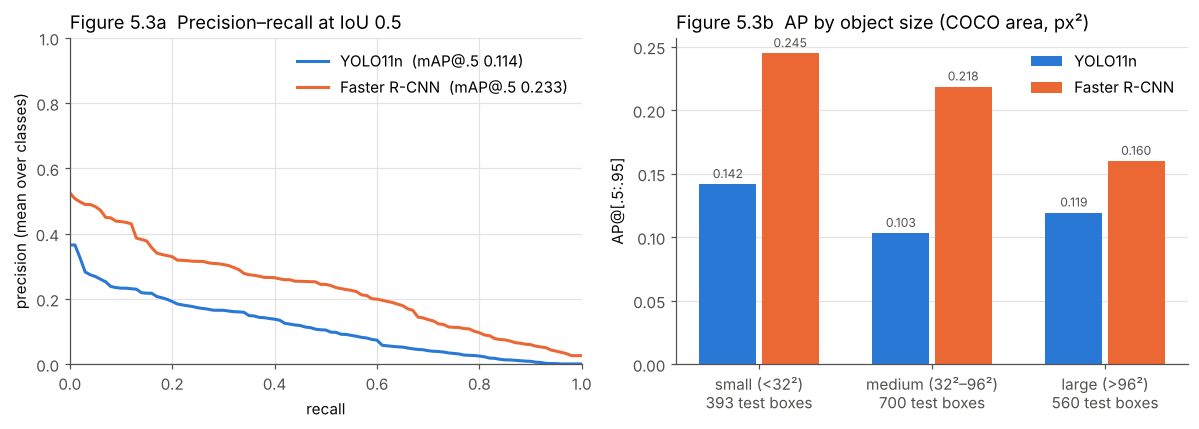

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rec = EVALS[MODELS[0]].params.recThrs
for m in MODELS:
    p = EVALS[m].eval["precision"][0, :, :, 0, -1]                 # IoU .5, all areas, 100 dets
    valid = [p[:, k] for k in range(p.shape[1]) if (p[:, k] > -1).any()]
    axes[0].plot(rec, np.mean(valid, 0), color=COLORS[m], lw=2, label=f"{m}  (mAP@.5 {STATS[m]['mAP50']:.3f})")
axes[0].set(xlabel="recall", ylabel="precision (mean over classes)", xlim=(0, 1), ylim=(0, 1))
axes[0].set_title("Figure 5.3a  Precision–recall at IoU 0.5", loc="left"); axes[0].legend()

sizes = ["AP_small", "AP_medium", "AP_large"]
area_share = pd.cut([a["area"] for a in coco_gt.dataset["annotations"]], [0, 32**2, 96**2, np.inf],
                    labels=["small", "medium", "large"]).value_counts().reindex(["small", "medium", "large"])
xs = np.arange(3); w = 0.36
for i, m in enumerate(MODELS):
    vals = [STATS[m][s] for s in sizes]
    bars = axes[1].bar(xs + (i - 0.5) * w, vals, w - 0.03, color=COLORS[m], label=m)
    for b, v in zip(bars, vals):
        axes[1].text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", fontsize=8, color=INK2)
rng = {"small": "<32²", "medium": "32²–96²", "large": ">96²"}
axes[1].set_xticks(xs, [f"{s} ({rng[s]})\n{n} test boxes" for s, n in area_share.items()])
axes[1].set_ylabel("AP@[.5:.95]"); axes[1].grid(axis="x", visible=False)
axes[1].set_title("Figure 5.3b  AP by object size (COCO area, px²)", loc="left"); axes[1].legend()
fig.tight_layout(); fig.savefig(OUT / "fig5_3_pr_and_size.png", dpi=200); plt.show()

#### Error analysis: false positives and missed detections

mAP summarises the whole ranking. To see *what kind* of mistakes each model makes, we fix each model at its own
operating point (the confidence that maximises its mean F1, Table 5.1) and label every kept box and every
ground-truth box with `match_at_conf` (rules in its docstring, adapted from the TIDE error categories).

Table 5.3  Kept detections by type, and ground-truth boxes by outcome (each model at its best-F1 confidence)


YOLO11n  Faster R-CNN
detections        Correct (TP)              599           846
                  Classification            692          1112
                  Localisation              170           338
                  Cls + Loc                 204           387
                  Duplicate                  47            30
                  Background                635          1010
GT boxes (n=1653) Detected                  599           846
                  Missed (wrong class)      447           394
                  Missed (no box)           607           413

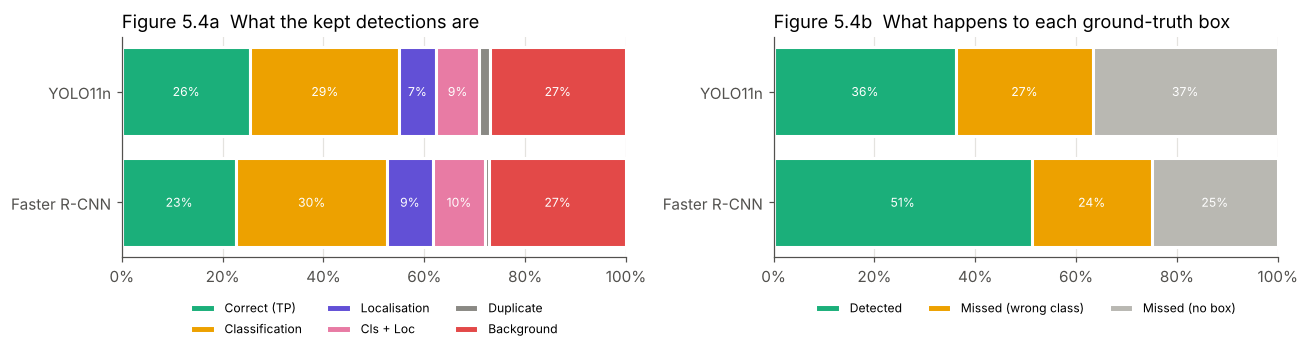

YOLO11n: most common class confusions (ground truth → predicted): trash_bag → trash_unknown_instance (99); animal_fish → trash_unknown_instance (76); trash_pipe → trash_unknown_instance (47); trash_branch → trash_unknown_instance (33); trash_unknown_instance → trash_container (28)
Faster R-CNN: most common class confusions (ground truth → predicted): trash_bag → trash_unknown_instance (114); trash_unknown_instance → trash_bag (75); animal_fish → trash_unknown_instance (74); animal_fish → trash_bag (67); trash_unknown_instance → trash_container (57)


In [ ]:
DET, GTS, CONF = {}, {}, {}
for m in MODELS:
    DET[m], GTS[m], CONF[m] = match_at_conf(PRED[m], PR[m]["conf"])

err = pd.DataFrame({m: DET[m]["type"].value_counts().reindex(ERR_TYPES, fill_value=0) for m in MODELS})
miss = pd.DataFrame({m: GTS[m]["status"].value_counts().reindex(["Detected", "Missed (wrong class)", "Missed (no box)"],
                                                                 fill_value=0) for m in MODELS})
print("Table 5.3  Kept detections by type, and ground-truth boxes by outcome (each model at its best-F1 confidence)")
display(pd.concat([err, miss], keys=["detections", f"GT boxes (n={len(coco_gt.dataset['annotations'])})"]))

ERR_COLORS = ["#1baf7a", "#eda100", "#6250d6", "#e87ba4", "#8a8984", "#e34948"]   # no model colours here
MISS_COLORS = ["#1baf7a", "#eda100", "#b9b8b2"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, tab, cols, title in [(axes[0], err, ERR_COLORS, "Figure 5.4a  What the kept detections are"),
                              (axes[1], miss, MISS_COLORS, "Figure 5.4b  What happens to each ground-truth box")]:
    share = tab / tab.sum()
    left = np.zeros(len(MODELS))
    for (name, row), c in zip(share.iterrows(), cols):
        ax.barh(MODELS[::-1], row[MODELS[::-1]], left=left, color=c, label=name,
                edgecolor="white", linewidth=2)
        for k, v in enumerate(row[MODELS[::-1]]):
            if v > 0.06:
                ax.text(left[k] + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white")
        left = left + row[MODELS[::-1]].values
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False); ax.set_title(title, loc="left")
    ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout(); fig.savefig(OUT / "fig5_4_errors.png", dpi=200); plt.show()

for m in MODELS:
    top = CONF[m].most_common(5)
    print(f"{m}: most common class confusions (ground truth → predicted): "
          + "; ".join(f"{g} → {p} ({n})" for (g, p), n in top))

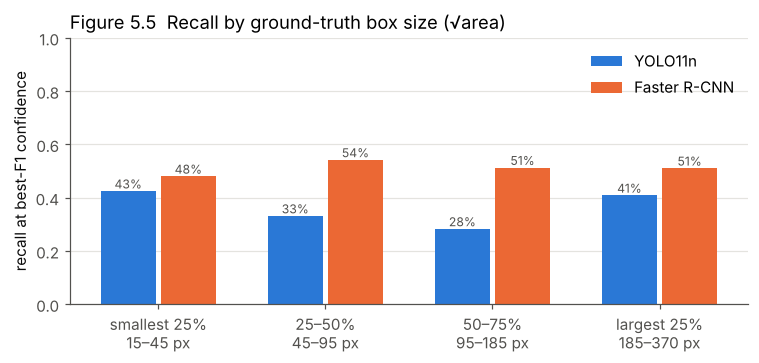

Lowest-recall classes with >= 10 test boxes:


,YOLO11n,Faster R-CNN,n_gt
category,,,
trash_pipe,0.00,0.00,65
trash_tarp,0.00,0.00,13
trash_cup,0.00,0.00,14
trash_wreckage,0.00,0.00,25
animal_starfish,0.00,0.07,15
plant,0.17,0.18,66


In [ ]:
# Recall by object size (equal-count bins of box area) and the classes that are missed most
size_bins = pd.qcut(GTS[MODELS[0]]["area"], 4, labels=["smallest 25%", "25–50%", "50–75%", "largest 25%"])
edges = pd.qcut(GTS[MODELS[0]]["area"], 4).cat.categories
fig, ax = plt.subplots(figsize=(7, 3.4))
xs = np.arange(4); w = 0.36
for i, m in enumerate(MODELS):
    r = (GTS[m]["status"] == "Detected").groupby(size_bins, observed=False).mean()
    bars = ax.bar(xs + (i - 0.5) * w, r.values, w - 0.03, color=COLORS[m], label=m)
    for b, v in zip(bars, r.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(xs, [f"{l}\n{int(e.left**0.5)}–{int(e.right**0.5)} px" for l, e in zip(size_bins.cat.categories, edges)])
ax.set_ylabel("recall at best-F1 confidence"); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False); ax.legend()
ax.set_title("Figure 5.5  Recall by ground-truth box size (√area)", loc="left")
fig.tight_layout(); fig.savefig(OUT / "fig5_5_recall_by_size.png", dpi=200); plt.show()

recall_cls = pd.DataFrame({m: (GTS[m]["status"] == "Detected").groupby(GTS[m]["category"]).mean() for m in MODELS})
recall_cls["n_gt"] = GTS[MODELS[0]].groupby("category").size()
print("Lowest-recall classes with >= 10 test boxes:")
display(recall_cls[recall_cls["n_gt"] >= 10].sort_values(MODELS[1]).head(6).style.format("{:.2f}", subset=MODELS))

#### Robustness to underwater image conditions

For every test image we measure four simple properties that capture typical underwater degradations:

* **brightness**: mean grey level (deep or poorly lit water is dark)
* **contrast**: standard deviation of grey levels (turbidity and back-scatter flatten contrast)
* **sharpness**: variance of the Laplacian (motion blur, suspended particles, defocus)
* **colour cast**: mean of blue and green minus mean of red (water absorbs red first; larger = stronger blue-green cast)

Images are split into three equal-sized groups (low / mid / high) on each property and both models are re-scored
on each group. Because neighbouring frames of one video look alike, each group contains only a few videos, so
these numbers show trends, not precise effects.

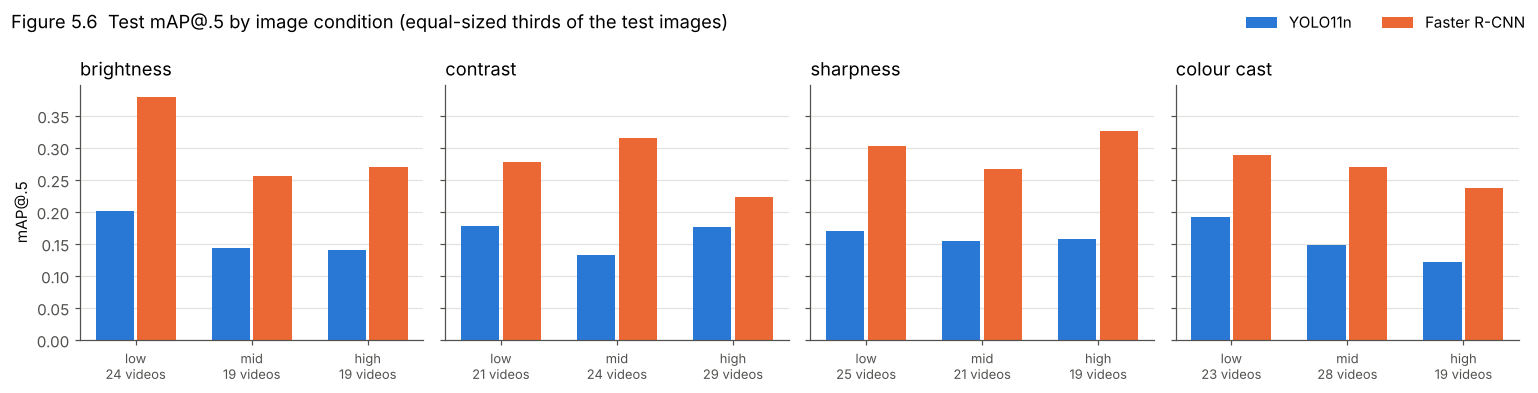

In [ ]:
rows = []
for im in test_images:
    bgr = cv2.imread(str(TEST_IMG_DIR / im["file_name"]))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
    b, g, r = bgr.reshape(-1, 3).mean(0)
    rows.append({"image_id": im["id"], "video": im["file_name"].split("_frame")[0],
                 "brightness": gray.mean(), "contrast": gray.std(),
                 "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(), "colour cast": (b + g) / 2 - r})
cond = pd.DataFrame(rows)
CONDS = ["brightness", "contrast", "sharpness", "colour cast"]
LEVELS = ["low", "mid", "high"]

res = []
for c in CONDS:
    cond[c + "_bin"] = pd.qcut(cond[c], 3, labels=LEVELS)
    for lv in LEVELS:
        ids = cond.loc[cond[c + "_bin"] == lv, "image_id"].tolist()
        n_box = sum(len(coco_gt.imgToAnns[i]) for i in ids)
        for m in MODELS:
            s, _ = coco_score(PRED[m], ids)
            res.append({"condition": c, "level": lv, "model": m, "mAP50": s["mAP50"], "mAP50_95": s["mAP50_95"],
                        "images": len(ids), "boxes": n_box, "videos": cond.loc[cond["image_id"].isin(ids), "video"].nunique()})
cond_res = pd.DataFrame(res)
cond_res.to_csv(OUT / "table_conditions.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, c in zip(axes, CONDS):
    sub = cond_res[cond_res["condition"] == c]
    for i, m in enumerate(MODELS):
        v = sub[sub["model"] == m].set_index("level").loc[LEVELS, "mAP50"]
        ax.bar(np.arange(3) + (i - 0.5) * 0.36, v.values, 0.33, color=COLORS[m], label=m)
    meta_lv = sub[sub["model"] == MODELS[0]].set_index("level").loc[LEVELS]
    ax.set_xticks(range(3), [f"{lv}\n{int(r.videos)} videos" for lv, r in meta_lv.iterrows()], fontsize=8.5)
    ax.set_title(c, loc="left"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mAP@.5")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.suptitle("Figure 5.6  Test mAP@.5 by image condition (equal-sized thirds of the test images)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT / "fig5_6_conditions.png", dpi=200); plt.show()

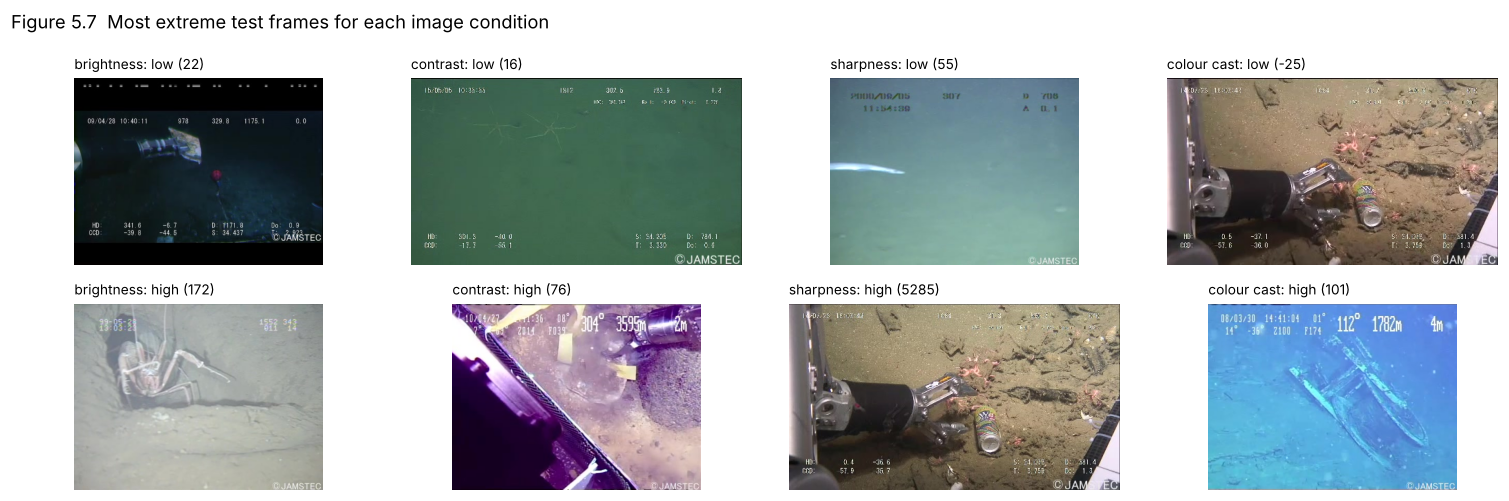

In [ ]:
# Example frames from the two ends of each condition, so the reader can see what "low" and "high" mean
fig, axes = plt.subplots(2, 4, figsize=(14, 4.6))
for j, c in enumerate(CONDS):
    for i, (lv, idx) in enumerate([("low", cond[c].idxmin()), ("high", cond[c].idxmax())]):
        im = coco_gt.imgs[cond.loc[idx, "image_id"]]
        axes[i, j].imshow(cv2.cvtColor(cv2.imread(str(TEST_IMG_DIR / im["file_name"])), cv2.COLOR_BGR2RGB))
        axes[i, j].set_title(f"{c}: {lv} ({cond.loc[idx, c]:.0f})", fontsize=9, loc="left"); axes[i, j].axis("off")
fig.suptitle("Figure 5.7  Most extreme test frames for each image condition", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(OUT / "fig5_7_condition_examples.png", dpi=200); plt.show()

#### Qualitative comparison
Ground truth (left), YOLO11n (middle) and Faster R-CNN (right), each model at its best-F1 confidence.
Green = correct, red = false positive, dashed white = missed ground truth. The rows are chosen automatically:
two frames where Faster R-CNN finds more objects, one where YOLO does, and one where both fail. At most one frame
per video is used.

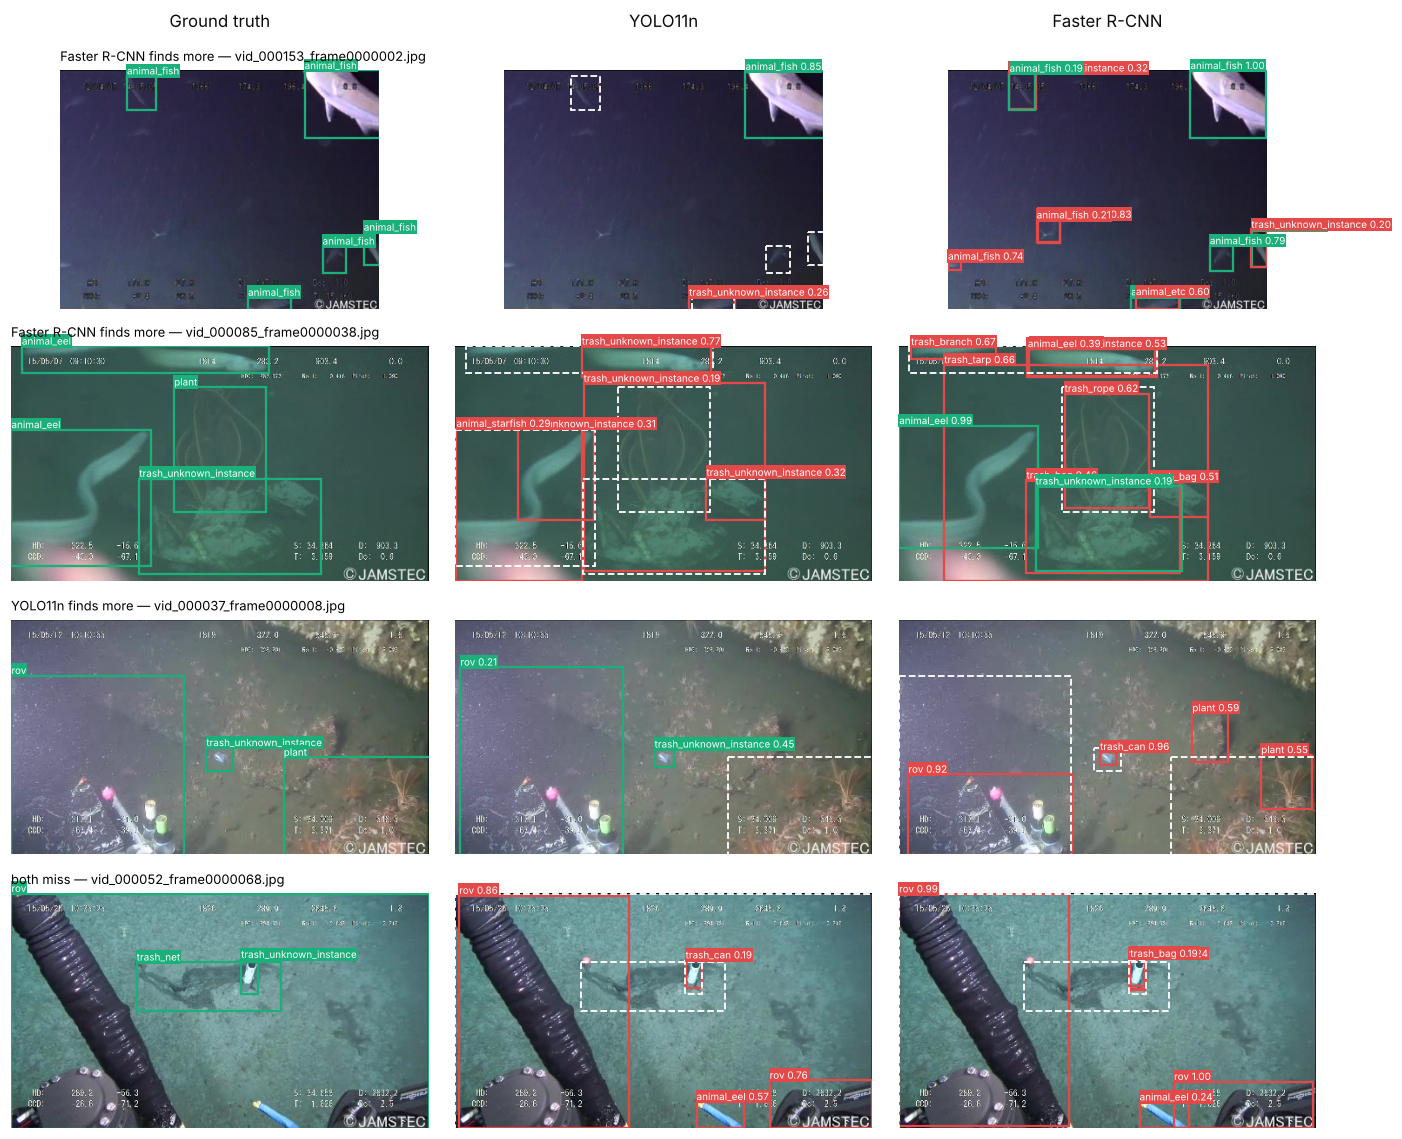

In [ ]:
def per_image_tp(m):
    d = DET[m]
    return d[d["type"] == "Correct (TP)"].groupby("image_id").size().reindex([im["id"] for im in test_images], fill_value=0)

tp = pd.DataFrame({m: per_image_tp(m) for m in MODELS})
tp["n_gt"] = [len(coco_gt.imgToAnns[im["id"]]) for im in test_images]
tp["video"] = [im["file_name"].split("_frame")[0] for im in test_images]
tp["diff"] = tp[MODELS[1]] - tp[MODELS[0]]
picked, used = [], set()
def take(frame, k, why):
    for iid, r in frame.iterrows():
        if k == 0:
            break
        if r["video"] not in used:
            used.add(r["video"]); picked.append((iid, why)); k -= 1
take(tp.sort_values("diff", ascending=False), 2, "Faster R-CNN finds more")
take(tp.sort_values("diff"), 1, "YOLO11n finds more")
take(tp[(tp[MODELS[0]] == 0) & (tp[MODELS[1]] == 0)].sort_values("n_gt", ascending=False), 1, "both miss")


def draw(ax, iid, model=None):
    im = coco_gt.imgs[iid]
    ax.imshow(cv2.cvtColor(cv2.imread(str(TEST_IMG_DIR / im["file_name"])), cv2.COLOR_BGR2RGB)); ax.axis("off")
    anns = coco_gt.imgToAnns[iid]
    if model is None:
        for a in anns:
            x, y, w, h = a["bbox"]
            ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec="#1baf7a", lw=1.5))
            ax.text(x, y - 2, CAT_NAME[a["category_id"]], fontsize=6.5, color="white",
                    bbox=dict(fc="#1baf7a", ec="none", pad=0.5))
        return
    kept = sorted([d for d in PRED[model] if d["image_id"] == iid and d["score"] >= PR[model]["conf"]],
                  key=lambda d: -d["score"])
    types = DET[model][DET[model]["image_id"] == iid]["type"].tolist()     # same order as kept
    for d, t in zip(kept, types):
        x, y, w, h = d["bbox"]; c = "#1baf7a" if t == "Correct (TP)" else "#e34948"
        ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec=c, lw=1.5))
        ax.text(x, y - 2, f"{CAT_NAME[d['category_id']]} {d['score']:.2f}", fontsize=6.5, color="white",
                bbox=dict(fc=c, ec="none", pad=0.5))
    g = GTS[model][GTS[model]["image_id"] == iid]
    for a, st in zip(anns, g["status"]):
        if st != "Detected":
            x, y, w, h = a["bbox"]
            ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec="white", lw=1.2, ls="--"))


fig, axes = plt.subplots(len(picked), 3, figsize=(13, 2.6 * len(picked)))
for row, (iid, why) in enumerate(picked):
    draw(axes[row, 0], iid); draw(axes[row, 1], iid, MODELS[0]); draw(axes[row, 2], iid, MODELS[1])
    axes[row, 0].set_title(f"{why} — {coco_gt.imgs[iid]['file_name']}", fontsize=8.5, loc="left")
for j, t in enumerate(["Ground truth", MODELS[0], MODELS[1]]):
    axes[0, j].text(0.5, 1.18, t, transform=axes[0, j].transAxes, ha="center", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(OUT / "fig5_8_qualitative.png", dpi=200); plt.show()

In [ ]:
# All numbers quoted in the Results / Discussion text come from this cell.
print(f"Operating points: " + ", ".join(f"{m} conf={PR[m]['conf']:.3f}" for m in MODELS))
for m in MODELS:
    e = err[m] / err[m].sum(); g = miss[m] / miss[m].sum()
    print(f"\n{m}: kept {err[m].sum()} boxes | TP {e['Correct (TP)']:.1%}, background {e['Background']:.1%}, "
          f"classification {e['Classification']:.1%}, localisation {e['Localisation']:.1%}, duplicate {e['Duplicate']:.1%}")
    print(f"  GT: detected {g['Detected']:.1%}, missed-wrong-class {g['Missed (wrong class)']:.1%}, "
          f"missed-no-box {g['Missed (no box)']:.1%}")
print()
display(cond_res.pivot_table(index=["condition", "level"], columns="model", values="mAP50", sort=False).round(3))

Operating points: YOLO11n conf=0.160, Faster R-CNN conf=0.175

YOLO11n: kept 2347 boxes | TP 25.5%, background 27.1%, classification 29.5%, localisation 7.2%, duplicate 2.0%
  GT: detected 36.2%, missed-wrong-class 27.0%, missed-no-box 36.7%

Faster R-CNN: kept 3723 boxes | TP 22.7%, background 27.1%, classification 29.9%, localisation 9.1%, duplicate 0.8%
  GT: detected 51.2%, missed-wrong-class 23.8%, missed-no-box 25.0%



model              YOLO11n  Faster R-CNN
condition   level                       
brightness  low      0.202         0.380
            mid      0.143         0.256
            high     0.140         0.270
contrast    low      0.177         0.277
            mid      0.132         0.315
            high     0.176         0.223
sharpness   low      0.170         0.302
            mid      0.155         0.267
            high     0.158         0.327
colour cast low      0.191         0.289
            mid      0.148         0.270
            high     0.122         0.237

## 6. Discussion

**Accuracy and recall.** The main difference is recall. At the confidence used for the error analysis, YOLO11n left 36.7% of ground-truth boxes without a retained detection meeting the analysis overlap threshold, compared with 25.0% for Faster R-CNN. Faster R-CNN led in all COCO size ranges, with the largest absolute AP gain on medium objects (0.218 vs 0.103) and a clear improvement on small objects (0.245 vs 0.142). It also led on 17 of the 18 classes with at least 10 test boxes. The exception was `rov`, where the YOLO11n AP50 was 0.537 versus 0.514.

**Model scale.** A larger one-stage model did not close the gap. YOLO11l, fine-tuned with the settings selected for YOLO11n (constant learning rate, mosaic throughout, 50 epochs), reached validation AP@[.50:.95] 0.0982 against 0.1011 for YOLO11n, and test AP 0.0598 against 0.0729 in the Ultralytics evaluator. These settings were tuned for the nano model and each configuration ran once, so the result shows that scale alone did not help under this protocol, not that YOLO11l cannot do better.

**Split versus training.** Both detectors score far below the published TrashCan baseline, but this reflects the evaluation split rather than undertraining. The Faster R-CNN reference model reaches AP@[.50:.95] 0.780 on its own training frames. Retrained on the original frame-level split, the selected configuration reaches 0.476 and 0.679 on that split's validation set, above the published 0.345 and 0.554 (Table FR4). On the original split 97% of the validation images come from training videos; on our video-disjoint test split the same configuration scores 0.150. The original benchmark therefore largely measures recognition of frames from seen videos, and our numbers are the more realistic estimate for new footage.

**Error sources.** Roughly 30% of retained detections were classification errors and 27% were background false positives for both models. Confusions such as `trash_bag` and `animal_fish` being predicted as `trash_unknown_instance` suggest that the broad unknown-debris label absorbs ambiguous objects. Rare categories have limited video coverage: the 74 `trash_pipe` training boxes came from three videos. The Faster R-CNN validation analysis found a stronger per-class association with training video count than with box count. This association was weaker on test and is evidence to investigate data diversity further. Wide `rov` ground-truth boxes and on-screen telemetry can also make some examples difficult to interpret.

**Underwater image conditions.** Both models' AP50 decreased across the low-to-high blue-green colour-cast thirds (YOLO11n 0.191 → 0.148 → 0.122; Faster R-CNN 0.289 → 0.270 → 0.237). The brightness, contrast and sharpness thirds showed no consistent trend. Frames from the same video remain correlated within these subsets, so differences in video composition may explain some of the pattern.

**Limitations.** The test split covers 47 videos and some classes have very few boxes or source videos. Grouping by video ID does not establish independence by recording site or scene. Trials were run once per configuration, so the results provide no estimate of training-seed variance. Faster R-CNN and YOLO11n differ in model size and tuning, which limits what the comparison can establish about two-stage versus one-stage detectors in general. The unified evaluation includes parameter counts but no controlled cross-family speed measurement.

**Future work.** Collect more independent videos for rare classes, test class-balanced sampling and underwater colour correction, and evaluate temporal tracking across consecutive frames. Re-tune YOLO11l with a decaying learning rate and mosaic shutoff, repeat the best configurations across seeds, and measure both detectors on the same target hardware at a fixed batch size.

## References

- Hong, J., Fulton, M., & Sattar, J. (2020). [TrashCan: A Semantically-Segmented Dataset towards Visual Detection of Marine Debris](https://arxiv.org/abs/2007.08097).
- Jocher, G., & Qiu, J. (2024). Ultralytics YOLO11 (version 11.0.0). [Model documentation](https://docs.ultralytics.com/models/yolo11/).
- Ren, S., He, K., Girshick, R., & Sun, J. (2015). [Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks](https://arxiv.org/abs/1506.01497).
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385).
- Lin, T.-Y. et al. (2017). [Feature Pyramid Networks for Object Detection](https://arxiv.org/abs/1612.03144).
- Howard, A. et al. (2019). [Searching for MobileNetV3](https://arxiv.org/abs/1905.02244).
- PyTorch. [Torchvision Faster R-CNN model documentation](https://pytorch.org/vision/stable/models/faster_rcnn.html).
- Lin, T.-Y. et al. (2014). [Microsoft COCO: Common Objects in Context](https://arxiv.org/abs/1405.0312).
- Bolya, D., Foley, S., Hays, J., & Hoffman, J. (2020). [TIDE: A General Toolbox for Identifying Object Detection Errors](https://arxiv.org/abs/2008.08115).

**Team materials.** `Project_part1_2.0/Project_part1/EDA.ipynb` (split and EDA); `YOLO/YOLO11n.ipynb` (baseline and parameter trials); `member3_faster_rcnn_final/member3_faster_rcnn.ipynb` (two-stage model and ablations); `evaluation.ipynb` (unified test evaluation).

## Appendix A. Faster R-CNN implementation

These cells hold the complete Faster R-CNN pipeline used in Sections 4.2 and 5.2. Each writes one file to `faster_rcnn/`; the saved outputs only confirm that the files were written. The training and evaluation scripts are called from the command line or from the training cell in Section 4.2.

In [ ]:
%%writefile faster_rcnn/common.py
"""Shared pieces for the Faster R-CNN pipeline: COCO dataset, model builder, checkpoints."""

import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_fpn,
    fasterrcnn_resnet50_fpn,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops.misc import FrozenBatchNorm2d
from torchvision.transforms import v2 as T

MODELS = {
    "resnet50_fpn_v2": (fasterrcnn_resnet50_fpn_v2, 5),
    "resnet50_fpn": (fasterrcnn_resnet50_fpn, 5),
    "mobilenet_v3_fpn": (fasterrcnn_mobilenet_v3_large_fpn, 6),
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def pick_device(name="auto"):
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


# ---------------------------------------------------------------- dataset


def load_categories(coco_json):
    """Categories sorted by id. Label 0 is background, so category i gets label i + 1."""
    with open(coco_json, encoding="utf-8") as f:
        cats = json.load(f)["categories"]
    return sorted(cats, key=lambda c: c["id"])


class CocoDetection(torch.utils.data.Dataset):
    """Reads a COCO detection json (TrashCan instance/material, or any split made from it).

    `categories` fixes the label mapping so train/val/test all use the same one.
    `mosaic` is the probability of replacing an image by a 4-frame mosaic (training only).
    """

    def __init__(self, coco_json, image_dir, categories, transforms=None, mosaic=0.0):
        with open(coco_json, encoding="utf-8") as f:
            data = json.load(f)
        self.image_dir = Path(image_dir)
        self.transforms = transforms
        self.mosaic = mosaic
        self.cat_to_label = {c["id"]: i + 1 for i, c in enumerate(categories)}
        self.images = sorted(data["images"], key=lambda im: im["id"])
        self.anns = {im["id"]: [] for im in self.images}
        for a in data["annotations"]:
            if a.get("iscrowd", 0) or a["image_id"] not in self.anns:
                continue
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.images)

    def _load(self, idx):
        """uint8 image [3, H, W], xyxy boxes [N, 4] and labels [N] of one image."""
        info = self.images[idx]
        img = read_image(str(self.image_dir / info["file_name"]), ImageReadMode.RGB)
        h, w = img.shape[-2:]
        boxes, labels = [], []
        for a in self.anns[info["id"]]:
            x, y, bw, bh = a["bbox"]
            # About 27% of TrashCan boxes run past the frame edge. Clip them here, because
            # SanitizeBoundingBoxes silently drops any box that leaves the image.
            x1, y1 = max(x, 0), max(y, 0)
            x2, y2 = min(x + bw, w), min(y + bh, h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                continue
            boxes.append([x1, y1, x2, y2])
            labels.append(self.cat_to_label[a["category_id"]])
        return (img, torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                torch.tensor(labels, dtype=torch.int64))

    def _mosaic(self, idx):
        """YOLO-style mosaic: this frame and three random others on a 2x2 canvas, cropped back to
        this frame's size around a random centre, so objects appear next to other videos' scenes."""
        img0, boxes0, labels0 = self._load(idx)
        H, W = img0.shape[-2:]
        canvas = torch.full((3, 2 * H, 2 * W), 114, dtype=torch.uint8)
        all_boxes, all_labels = [], []
        for k, j in enumerate([idx] + random.choices(range(len(self.images)), k=3)):
            img, boxes, labels = (img0, boxes0, labels0) if k == 0 else self._load(j)
            h, w = img.shape[-2:]
            s = min(H / h, W / w, 1.0)
            if s < 1:
                h, w = round(h * s), round(w * s)
                img = T.functional.resize(img, [h, w], antialias=True)
                boxes = boxes * s
            # Each frame touches the canvas centre: top-left, top-right, bottom-left, bottom-right.
            y0 = H - h if k < 2 else H
            x0 = W - w if k % 2 == 0 else W
            canvas[:, y0:y0 + h, x0:x0 + w] = img
            all_boxes.append(boxes + torch.tensor([x0, y0, x0, y0]))
            all_labels.append(labels)
        top = random.randint(0, H)
        left = random.randint(0, W)
        boxes = torch.cat(all_boxes) - torch.tensor([left, top, left, top])
        clipped = boxes.clone()
        clipped[:, 0::2] = clipped[:, 0::2].clamp(0, W)
        clipped[:, 1::2] = clipped[:, 1::2].clamp(0, H)
        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        cw, ch = clipped[:, 2] - clipped[:, 0], clipped[:, 3] - clipped[:, 1]
        # Ultralytics' rule: drop boxes cut to under 10% of their area or under 2 px.
        keep = (cw > 2) & (ch > 2) & (cw * ch > 0.1 * area)
        return canvas[:, top:top + H, left:left + W], clipped[keep], torch.cat(all_labels)[keep]

    def __getitem__(self, idx):
        if self.mosaic and random.random() < self.mosaic:
            img, boxes, labels = self._mosaic(idx)
        else:
            img, boxes, labels = self._load(idx)
        h, w = img.shape[-2:]
        target = {
            "boxes": tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(h, w)),
            "labels": labels,
            "image_id": self.images[idx]["id"],
        }
        img = tv_tensors.Image(img)
        if self.transforms is not None:
            img, target = self.transforms(img, target)
        return img, target


def take_subset(dataset, coco_gt, n):
    """Keep only the first n images of a dataset (and its pycocotools ground truth), for quick tests."""
    dataset.images = dataset.images[:n]
    if coco_gt is not None:
        keep = {im["id"] for im in dataset.images}
        coco_gt.dataset["images"] = dataset.images
        coco_gt.dataset["annotations"] = [a for a in coco_gt.dataset["annotations"] if a["image_id"] in keep]
        coco_gt.createIndex()


def get_transforms(train, aug="basic"):
    t = []
    if train and aug != "none":
        t.append(T.RandomHorizontalFlip(0.5))
        if aug == "strong":
            # Underwater colour/brightness varies a lot between dives.
            t.append(T.RandomPhotometricDistort(p=0.5))
    t += [T.ToDtype(torch.float32, scale=True), T.SanitizeBoundingBoxes()]
    return T.Compose(t)


def collate_fn(batch):
    return tuple(zip(*batch))


# ---------------------------------------------------------------- model


def freeze_batchnorm(module):
    """Swap BatchNorm2d for FrozenBatchNorm2d, keeping the pretrained statistics.

    With batch size 4 the BN statistics are too noisy to update, so the
    backbone keeps the ones learned on COCO / ImageNet.
    """
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            frozen = FrozenBatchNorm2d(child.num_features, eps=child.eps)
            frozen.weight.copy_(child.weight.detach())
            frozen.bias.copy_(child.bias.detach())
            frozen.running_mean.copy_(child.running_mean)
            frozen.running_var.copy_(child.running_var)
            setattr(module, name, frozen)
        else:
            freeze_batchnorm(child)
    return module


def build_model(name, num_classes, pretrained="coco", trainable_layers=3, min_size=(800,), max_size=1333):
    """Faster R-CNN with a new box predictor for `num_classes` (+ background).

    pretrained: "coco"     -> whole detector pretrained on COCO (transfer learning)
                "imagenet" -> only the backbone pretrained on ImageNet
                "none"     -> random init (also used to rebuild a model before loading a checkpoint)
    """
    builder, max_layers = MODELS[name]
    kwargs = dict(min_size=tuple(min_size), max_size=max_size)
    if pretrained == "coco":
        kwargs.update(weights="DEFAULT", trainable_backbone_layers=trainable_layers)
    elif pretrained == "imagenet":
        kwargs.update(weights=None, weights_backbone="DEFAULT", trainable_backbone_layers=trainable_layers)
    elif pretrained == "none":
        kwargs.update(weights=None, weights_backbone=None)
    else:
        raise ValueError(f"unknown pretrained mode {pretrained!r}")
    if not 0 <= trainable_layers <= max_layers:
        raise ValueError(f"{name} supports trainable_layers 0..{max_layers}")

    model = builder(**kwargs)
    if name == "resnet50_fpn_v2" and pretrained != "none":
        # v2 builds its ResNet with plain BatchNorm2d; v1/mobilenet already freeze it.
        freeze_batchnorm(model.backbone.body)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)
    return model


def save_checkpoint(path, model, args, categories, epoch, best_map, optimizer=None, scheduler=None, scaler=None):
    ckpt = {
        "model": model.state_dict(),
        "model_name": args.model,
        "categories": categories,
        "min_size": list(args.min_size),
        "max_size": args.max_size,
        "epoch": epoch,
        "best_map": best_map,
        "args": vars(args),
    }
    if optimizer is not None:
        ckpt.update(optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), scaler=scaler.state_dict())
    torch.save(ckpt, path)


def load_model_from_checkpoint(path, device):
    """Rebuild the network from a checkpoint alone (no pretrained download needed)."""
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cats = ckpt["categories"]
    model = build_model(ckpt["model_name"], len(cats), pretrained="none",
                        min_size=ckpt["min_size"], max_size=ckpt["max_size"])
    # A random-init rebuild uses BatchNorm2d where training used FrozenBatchNorm2d.
    # They are identical in eval mode; the only key difference is num_batches_tracked.
    missing, unexpected = model.load_state_dict(ckpt["model"], strict=False)
    bad = [k for k in missing + unexpected if not k.endswith("num_batches_tracked")]
    if bad:
        raise RuntimeError(f"checkpoint does not match model: {bad[:5]}")
    model.to(device).eval()
    return model, cats, ckpt

Overwriting faster_rcnn/common.py


In [ ]:
%%writefile faster_rcnn/metrics.py
"""Evaluation helpers: inference to COCO json, COCO mAP, YOLO-style P/R, speed, curves."""

import contextlib
import csv
import io
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

STAT_NAMES = ["mAP50_95", "mAP50", "mAP75", "mAP_small", "mAP_medium", "mAP_large",
              "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]


def load_coco(path):
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(path))


def autocast(device, enabled):
    return torch.autocast("cuda" if device.type == "cuda" else "cpu", dtype=torch.float16,
                          enabled=enabled and device.type == "cuda")


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


@torch.inference_mode()
def run_inference(model, loader, device, label_to_cat, amp=False):
    """Detections for every image in `loader`, as a COCO results list (xywh boxes, original ids)."""
    model.eval()
    dets = []
    for imgs, targets in loader:
        imgs = [im.to(device, non_blocking=True) for im in imgs]
        with autocast(device, amp):
            outs = model(imgs)
        for out, t in zip(outs, targets):
            boxes = out["boxes"].float().cpu()
            boxes[:, 2:] -= boxes[:, :2]
            for b, s, l in zip(boxes.tolist(), out["scores"].tolist(), out["labels"].tolist()):
                dets.append({"image_id": t["image_id"], "category_id": label_to_cat[l],
                             "bbox": [round(v, 2) for v in b], "score": round(s, 5)})
    return dets


def coco_evaluate(coco_gt, dets, verbose=False):
    """COCO bbox metrics. Returns (stats dict, COCOeval or None when there are no detections)."""
    if not dets:
        return {k: 0.0 for k in STAT_NAMES}, None
    out = io.StringIO()
    with contextlib.redirect_stdout(out):
        # loadRes adds fields to each dict, so give it copies.
        coco_dt = coco_gt.loadRes([dict(d) for d in dets])
        E = COCOeval(coco_gt, coco_dt, "bbox")
        E.evaluate()
        E.accumulate()
        E.summarize()
    if verbose:
        print(out.getvalue().split("DONE")[-1].strip())
    return dict(zip(STAT_NAMES, (float(s) for s in E.stats))), E


def per_class_ap(E, coco_gt, categories):
    """AP@[.5:.95] and AP@.5 per category from an accumulated COCOeval."""
    n_gt = defaultdict(int)
    for a in coco_gt.dataset["annotations"]:
        if not a.get("iscrowd", 0):
            n_gt[a["category_id"]] += 1
    rows = []
    precision = E.eval["precision"] if E is not None else None  # [IoU, recall, class, area, maxDets]
    for c in categories:
        ap = ap50 = float("nan")
        if precision is not None and c["id"] in E.params.catIds:
            k = E.params.catIds.index(c["id"])
            p = precision[:, :, k, 0, -1]
            p50 = precision[0, :, k, 0, -1]
            ap = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
            ap50 = float(p50[p50 > -1].mean()) if (p50 > -1).any() else float("nan")
        rows.append({"category": c["name"], "n_gt": n_gt[c["id"]], "AP50_95": ap, "AP50": ap50})
    return rows


def _iou(a, b):
    """IoU between xyxy arrays a [N,4] and b [M,4]."""
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    area_a = (a[:, 2:] - a[:, :2]).prod(-1)
    area_b = (b[:, 2:] - b[:, :2]).prod(-1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def _xyxy(bbox):
    x, y, w, h = bbox
    return [x, y, x + w, y + h]


def precision_recall(coco_gt, dets, categories, iou_thr=0.5, fixed_conf=0.5):
    """Precision / recall at IoU 0.5, computed the way Ultralytics reports them for YOLO.

    Detections are matched greedily per class by descending score. P and R are
    averaged over the classes present in the ground truth, at the confidence
    threshold that maximises the mean F1 (and also at `fixed_conf`).
    """
    gts, dts = defaultdict(list), defaultdict(list)
    for a in coco_gt.dataset["annotations"]:
        if not a.get("iscrowd", 0):
            gts[(a["image_id"], a["category_id"])].append(_xyxy(a["bbox"]))
    for d in dets:
        dts[(d["image_id"], d["category_id"])].append((d["score"], _xyxy(d["bbox"])))

    scores, tps, n_gt = defaultdict(list), defaultdict(list), defaultdict(int)
    for key in set(gts) | set(dts):
        cat = key[1]
        g = np.array(gts.get(key, []), dtype=np.float64).reshape(-1, 4)
        d = sorted(dts.get(key, []), key=lambda x: -x[0])
        n_gt[cat] += len(g)
        if not d:
            continue
        db = np.array([b for _, b in d], dtype=np.float64)
        iou = _iou(db, g) if len(g) else np.zeros((len(d), 0))
        matched = np.zeros(len(g), dtype=bool)
        for i, (s, _) in enumerate(d):
            tp = False
            if len(g):
                cand = np.where(matched, -1.0, iou[i])
                j = int(cand.argmax())
                if cand[j] >= iou_thr:
                    matched[j] = tp = True
            scores[cat].append(s)
            tps[cat].append(tp)

    conf = np.linspace(0, 1, 1001)
    cats = [c["id"] for c in categories if n_gt[c["id"]] > 0]
    P = np.ones((len(cats), len(conf)))
    R = np.zeros((len(cats), len(conf)))
    for k, cat in enumerate(cats):
        s = np.array(scores[cat])
        if len(s) == 0:
            continue
        order = np.argsort(-s)
        s = s[order]
        cum_tp = np.concatenate([[0], np.cumsum(np.array(tps[cat])[order])])
        n = np.searchsorted(-s, -conf, side="right")  # detections with score >= conf
        P[k] = np.where(n > 0, cum_tp[n] / np.maximum(n, 1), 1.0)
        R[k] = cum_tp[n] / n_gt[cat]
    F1 = 2 * P * R / (P + R + 1e-16)

    def at(i):
        return {"precision": float(P[:, i].mean()), "recall": float(R[:, i].mean()),
                "f1": float(F1[:, i].mean()), "conf": float(conf[i])}

    if not cats:
        return {"best_f1": None, "fixed_conf": None}
    best = int(F1.mean(0).argmax())
    fixed = int(np.abs(conf - fixed_conf).argmin())
    return {"best_f1": at(best), "fixed_conf": at(fixed)}


@torch.inference_mode()
def benchmark(model, dataset, device, n=200, warmup=20, amp=False):
    """Model forward time per image at batch size 1 (resize + network + NMS; JPEG decode excluded)."""
    model.eval()
    times = []
    for k in range(warmup + n):
        img = dataset[k % len(dataset)][0].to(device)
        synchronize(device)
        t0 = time.perf_counter()
        with autocast(device, amp):
            model([img])
        synchronize(device)
        if k >= warmup:
            times.append((time.perf_counter() - t0) * 1000)
    t = np.array(times)
    return {"ms_per_img_mean": float(t.mean()), "ms_per_img_median": float(np.median(t)),
            "fps": float(1000 / t.mean()), "n_images": n, "batch_size": 1, "amp": bool(amp)}


def plot_training_curves(run_dir):
    """Loss components and val mAP per epoch from results.csv -> curves.png."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    run_dir = Path(run_dir)
    with open(run_dir / "results.csv", newline="") as f:
        rows = list(csv.DictReader(f))
    if not rows:
        return
    ep = [int(r["epoch"]) for r in rows]
    col = lambda k: [float(r[k]) if r[k] != "" else np.nan for r in rows]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for k in ["loss", "loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
        axes[0].plot(ep, col(k), label=k, lw=2 if k == "loss" else 1.2)
    axes[0].set(title="Training loss", xlabel="epoch")
    axes[0].legend(fontsize=8)
    for k, lab in [("mAP50", "mAP@0.5"), ("mAP50_95", "mAP@0.5:0.95")]:
        axes[1].plot(ep, col(k), marker="o", ms=3, label=lab)
    axes[1].set(title="Validation mAP", xlabel="epoch")
    axes[1].legend(fontsize=8)
    axes[2].plot(ep, col("lr"))
    axes[2].set(title="Learning rate (end of epoch)", xlabel="epoch")
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(run_dir / "curves.png", dpi=150)
    plt.close(fig)


def plot_pr_curves(E, categories, out_path):
    """Per-class precision-recall curves at IoU 0.5 (thin) and their mean (bold)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    if E is None:
        return
    rec = E.params.recThrs
    prec = E.eval["precision"][0, :, :, 0, -1]  # [recall, class]
    fig, ax = plt.subplots(figsize=(7, 6))
    valid = []
    for c in categories:
        if c["id"] not in E.params.catIds:
            continue
        p = prec[:, E.params.catIds.index(c["id"])]
        if (p > -1).any():
            ax.plot(rec, p, lw=0.8, alpha=0.6, label=f"{c['name']} {p.mean():.2f}")
            valid.append(p)
    if valid:
        mean = np.mean(valid, 0)
        ax.plot(rec, mean, lw=3, color="black", label=f"all classes {mean.mean():.3f} mAP@0.5")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision-Recall (IoU=0.5)")
    ax.legend(fontsize=6, loc="lower left", ncol=2)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.close(fig)

Overwriting faster_rcnn/metrics.py


In [ ]:
%%writefile faster_rcnn/train.py
"""Fine-tune a COCO-pretrained torchvision Faster R-CNN on TrashCan (COCO-format json).

Example (Windows, RTX 5070):
    python train.py --train-json D:/debris/data/instances_train.json --train-images D:/debris/data/train ^
                    --val-json D:/debris/data/instances_val.json --val-images D:/debris/data/val ^
                    --out D:/debris/runs/frcnn_r50v2_800
"""

import argparse
import csv
import json
import math
import time
from pathlib import Path

import torch

from common import (MODELS, CocoDetection, build_model, collate_fn, get_transforms, load_categories,
                    pick_device, save_checkpoint, set_seed, take_subset)
from metrics import autocast, coco_evaluate, load_coco, plot_training_curves, run_inference

LOSS_KEYS = ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--train-json", required=True)
    p.add_argument("--train-images", required=True)
    p.add_argument("--val-json", required=True)
    p.add_argument("--val-images", required=True)
    p.add_argument("--out", default="runs/frcnn", help="run folder (keep it outside OneDrive)")
    p.add_argument("--model", default="resnet50_fpn_v2", choices=list(MODELS))
    p.add_argument("--pretrained", default="coco", choices=["coco", "imagenet", "none"])
    p.add_argument("--trainable-layers", type=int, default=3, help="backbone stages to fine-tune (0 = frozen)")
    p.add_argument("--epochs", type=int, default=20)
    p.add_argument("--batch-size", type=int, default=4)
    p.add_argument("--lr", type=float, default=None, help="default: 0.02 * batch_size / 16")
    p.add_argument("--momentum", type=float, default=0.9)
    p.add_argument("--weight-decay", type=float, default=1e-4)
    p.add_argument("--warmup-iters", type=int, default=500)
    p.add_argument("--min-size", type=int, nargs="+", default=[800],
                   help="shorter side after resize; several values = multi-scale training, last one used for eval")
    p.add_argument("--max-size", type=int, default=1333)
    p.add_argument("--aug", default="basic", choices=["none", "basic", "strong"],
                   help="basic = horizontal flip, strong = flip + photometric distortion")
    p.add_argument("--mosaic", type=float, default=0.0,
                   help="probability of a YOLO-style 4-frame mosaic per training image, 0 = off")
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--no-amp", action="store_true", help="disable mixed precision on CUDA")
    p.add_argument("--eval-every", type=int, default=1)
    p.add_argument("--subset", type=int, default=0, help="use only the first N train/val images (quick test)")
    p.add_argument("--resume", default=None, help="path to last.pt to continue training")
    p.add_argument("--device", default="auto")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--print-every", type=int, default=50)
    return p.parse_args()


def lr_lambda(warmup, total, min_factor=0.01):
    """Linear warmup, then cosine decay to min_factor * lr (per iteration)."""
    def f(it):
        if it < warmup:
            return 0.001 + (1 - 0.001) * it / warmup
        progress = (it - warmup) / max(1, total - warmup)
        return min_factor + (1 - min_factor) * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))
    return f


def make_loader(dataset, batch_size, shuffle, workers, device):
    return torch.utils.data.DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers, collate_fn=collate_fn,
        pin_memory=device.type == "cuda", persistent_workers=workers > 0)


def main():
    args = parse_args()
    if args.lr is None:
        args.lr = 0.02 * args.batch_size / 16
    set_seed(args.seed)
    device = pick_device(args.device)
    use_amp = device.type == "cuda" and not args.no_amp
    torch.backends.cudnn.benchmark = True
    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)

    categories = load_categories(args.train_json)
    val_ids = [c["id"] for c in load_categories(args.val_json)]
    if val_ids != [c["id"] for c in categories]:
        raise SystemExit("train and val json have different categories - use the same TrashCan version")
    label_to_cat = {i + 1: c["id"] for i, c in enumerate(categories)}

    train_set = CocoDetection(args.train_json, args.train_images, categories, get_transforms(True, args.aug),
                              mosaic=args.mosaic)
    val_set = CocoDetection(args.val_json, args.val_images, categories, get_transforms(False))
    coco_val = load_coco(args.val_json)
    if args.subset:
        take_subset(train_set, None, args.subset)
        take_subset(val_set, coco_val, args.subset)
    train_loader = make_loader(train_set, args.batch_size, True, args.workers, device)
    val_loader = make_loader(val_set, args.batch_size, False, args.workers, device)

    model = build_model(args.model, len(categories), args.pretrained, args.trainable_layers,
                        args.min_size, args.max_size).to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=args.lr, momentum=args.momentum, weight_decay=args.weight_decay)
    total_iters = args.epochs * len(train_loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda(args.warmup_iters, total_iters))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start_epoch, best_map = 1, -1.0
    if args.resume:
        ckpt = torch.load(args.resume, map_location="cpu", weights_only=False)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        scaler.load_state_dict(ckpt["scaler"])
        start_epoch, best_map = ckpt["epoch"] + 1, ckpt["best_map"]
        print(f"resumed from {args.resume} at epoch {ckpt['epoch']}")
    else:
        (out / "args.json").write_text(json.dumps(vars(args), indent=2))

    n_total = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in params)
    print(f"device={device} amp={use_amp} model={args.model} pretrained={args.pretrained} "
          f"classes={len(categories)} params={n_total / 1e6:.1f}M (trainable {n_train / 1e6:.1f}M)")
    print(f"train images={len(train_set)} val images={len(val_set)} iters/epoch={len(train_loader)} lr={args.lr}")

    results_path = out / "results.csv"
    fields = ["epoch", "lr", "loss", *LOSS_KEYS, "mAP50_95", "mAP50", "mAP75", "mAP_small", "mAP_medium",
              "mAP_large", "AR100", "epoch_min", "val_min"]
    if not results_path.exists():
        with open(results_path, "w", newline="") as f:
            csv.DictWriter(f, fields).writeheader()
    iter_log = open(out / "iter_log.csv", "a", newline="")
    iter_writer = csv.writer(iter_log)
    if iter_log.tell() == 0:
        iter_writer.writerow(["epoch", "iter", "global_iter", "lr", "loss", *LOSS_KEYS])

    train_start = time.time()
    for epoch in range(start_epoch, args.epochs + 1):
        model.train()
        t0 = time.time()
        sums = {k: 0.0 for k in ["loss", *LOSS_KEYS]}
        for it, (imgs, targets) in enumerate(train_loader, 1):
            imgs = [im.to(device, non_blocking=True) for im in imgs]
            targets = [{"boxes": t["boxes"].as_subclass(torch.Tensor).to(device),
                        "labels": t["labels"].to(device)} for t in targets]
            with autocast(device, use_amp):
                loss_dict = model(imgs, targets)
                loss = sum(loss_dict.values())
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise SystemExit(f"loss is {loss_value} at epoch {epoch} iter {it}: "
                                 f"{ {k: v.item() for k, v in loss_dict.items()} } - try a lower --lr")
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            parts = {k: loss_dict[k].item() for k in LOSS_KEYS}
            sums["loss"] += loss_value
            for k in LOSS_KEYS:
                sums[k] += parts[k]
            if it % args.print_every == 0 or it == len(train_loader):
                lr = optimizer.param_groups[0]["lr"]
                g_it = (epoch - 1) * len(train_loader) + it
                iter_writer.writerow([epoch, it, g_it, f"{lr:.6g}", f"{loss_value:.4f}",
                                      *(f"{parts[k]:.4f}" for k in LOSS_KEYS)])
                iter_log.flush()
                eta = (time.time() - t0) / it * (len(train_loader) - it)
                mem = f" mem={torch.cuda.max_memory_allocated() / 2**30:.1f}G" if device.type == "cuda" else ""
                print(f"epoch {epoch}/{args.epochs} iter {it}/{len(train_loader)} lr={lr:.5f} "
                      f"loss={sums['loss'] / it:.4f} cls={sums['loss_classifier'] / it:.3f} "
                      f"box={sums['loss_box_reg'] / it:.3f} obj={sums['loss_objectness'] / it:.3f} "
                      f"rpn={sums['loss_rpn_box_reg'] / it:.3f} eta={eta / 60:.1f}min{mem}", flush=True)
        epoch_min = (time.time() - t0) / 60

        row = {"epoch": epoch, "lr": f"{optimizer.param_groups[0]['lr']:.6g}", "epoch_min": f"{epoch_min:.2f}"}
        row.update({k: f"{v / len(train_loader):.4f}" for k, v in sums.items()})
        stats = None
        if epoch % args.eval_every == 0 or epoch == args.epochs:
            t1 = time.time()
            # FP32 like evaluate.py: under autocast the box decoder rounds coordinates to float16.
            dets = run_inference(model, val_loader, device, label_to_cat)
            stats, _ = coco_evaluate(coco_val, dets)
            row.update({k: f"{stats[k]:.4f}" for k in fields if k in stats})
            row["val_min"] = f"{(time.time() - t1) / 60:.2f}"
            print(f"epoch {epoch} val mAP@.5:.95={stats['mAP50_95']:.4f} mAP@.5={stats['mAP50']:.4f} "
                  f"({len(dets)} detections, {epoch_min:.1f} min train)", flush=True)
        with open(results_path, "a", newline="") as f:
            csv.DictWriter(f, fields).writerow(row)

        if stats is not None and stats["mAP50_95"] > best_map:
            best_map = stats["mAP50_95"]
            save_checkpoint(out / "best.pt", model, args, categories, epoch, best_map)
            print(f"  new best -> {out / 'best.pt'}")
        save_checkpoint(out / "last.pt", model, args, categories, epoch, best_map, optimizer, scheduler, scaler)
        plot_training_curves(out)

    iter_log.close()
    summary = {"best_val_mAP50_95": best_map, "epochs": args.epochs, "train_hours": (time.time() - train_start) / 3600,
               "params_M": n_total / 1e6, "device": torch.cuda.get_device_name(0) if device.type == "cuda" else str(device)}
    (out / "summary.json").write_text(json.dumps(summary, indent=2))
    print(f"done. best val mAP@.5:.95 = {best_map:.4f}")
    print(f"next: python evaluate.py --weights {out / 'best.pt'} --json <test json> --images <test images> "
          f"--out {out / 'eval_test'}")


if __name__ == "__main__":
    main()

Overwriting faster_rcnn/train.py


In [ ]:
%%writefile faster_rcnn/evaluate.py
"""Evaluate a trained checkpoint on a COCO-format split (normally the shared test split).

Writes to --out:
    metrics.json      COCO mAP@[.5:.95] / mAP@.5 / size breakdown, P/R, inference speed
    per_class_ap.csv  AP per category (+ number of GT boxes)
    predictions.json  COCO results format, for the team's unified evaluation against YOLO
    pr_curve.png      precision-recall curves at IoU 0.5
"""

import argparse
import csv
import json
from pathlib import Path

import torch

from common import (CocoDetection, collate_fn, get_transforms, load_categories, load_model_from_checkpoint,
                    pick_device, take_subset)
from metrics import (benchmark, coco_evaluate, load_coco, per_class_ap, plot_pr_curves, precision_recall,
                     run_inference)


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--weights", required=True, help="best.pt / last.pt from train.py")
    p.add_argument("--json", required=True, help="ground-truth COCO json of the split to evaluate")
    p.add_argument("--images", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--batch-size", type=int, default=4)
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--amp", action="store_true", help="fp16 inference on CUDA (also used for the speed test)")
    p.add_argument("--bench-images", type=int, default=200, help="images for the speed test, 0 to skip")
    p.add_argument("--conf", type=float, default=0.5, help="fixed confidence threshold for the extra P/R numbers")
    p.add_argument("--score-thresh", type=float, default=None,
                   help="drop detections below this score (torchvision default 0.05, Ultralytics val uses 0.001)")
    p.add_argument("--subset", type=int, default=0)
    p.add_argument("--device", default="auto")
    return p.parse_args()


def main():
    args = parse_args()
    device = pick_device(args.device)
    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)

    model, categories, ckpt = load_model_from_checkpoint(args.weights, device)
    if args.score_thresh is not None:
        model.roi_heads.score_thresh = args.score_thresh
    if [c["id"] for c in load_categories(args.json)] != [c["id"] for c in categories]:
        raise SystemExit("this json has different categories from the ones the model was trained on")
    label_to_cat = {i + 1: c["id"] for i, c in enumerate(categories)}

    dataset = CocoDetection(args.json, args.images, categories, get_transforms(False))
    coco_gt = load_coco(args.json)
    if args.subset:
        take_subset(dataset, coco_gt, args.subset)
    loader = torch.utils.data.DataLoader(dataset, batch_size=args.batch_size, num_workers=args.workers,
                                         collate_fn=collate_fn, pin_memory=device.type == "cuda")

    print(f"evaluating {args.weights} (epoch {ckpt['epoch']}) on {len(dataset)} images, device={device}")
    dets = run_inference(model, loader, device, label_to_cat, args.amp)
    (out / "predictions.json").write_text(json.dumps(dets))
    stats, E = coco_evaluate(coco_gt, dets, verbose=True)
    pr = precision_recall(coco_gt, dets, categories, fixed_conf=args.conf)
    rows = per_class_ap(E, coco_gt, categories)
    plot_pr_curves(E, categories, out / "pr_curve.png")

    speed = None
    if args.bench_images:
        speed = benchmark(model, dataset, device, n=args.bench_images, amp=args.amp)
        speed["device"] = torch.cuda.get_device_name(0) if device.type == "cuda" else str(device)

    metrics = {
        "weights": str(args.weights),
        "model": ckpt["model_name"],
        "epoch": ckpt["epoch"],
        "eval_min_size": ckpt["min_size"][-1],
        "score_thresh": model.roi_heads.score_thresh,
        "split_json": str(args.json),
        "n_images": len(dataset),
        "n_detections": len(dets),
        "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
        "coco": stats,
        "pr_iou50": pr,
        "speed": speed,
    }
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2))
    with open(out / "per_class_ap.csv", "w", newline="") as f:
        w = csv.DictWriter(f, ["category", "n_gt", "AP50_95", "AP50"])
        w.writeheader()
        w.writerows({**r, "AP50_95": f"{r['AP50_95']:.4f}", "AP50": f"{r['AP50']:.4f}"} for r in rows)

    b = pr["best_f1"] or {}
    print(f"\nmAP@.5:.95 {stats['mAP50_95']:.4f} | mAP@.5 {stats['mAP50']:.4f} | "
          f"P {b.get('precision', 0):.4f} R {b.get('recall', 0):.4f} (conf {b.get('conf', 0):.3f}, best F1)")
    if speed:
        print(f"speed: {speed['ms_per_img_mean']:.1f} ms/img ({speed['fps']:.1f} FPS) on {speed['device']}")
    print("\nper-class AP@.5:.95 / AP@.5:")
    for r in rows:
        print(f"  {r['category']:<24} n={r['n_gt']:<5} {r['AP50_95']:.3f} / {r['AP50']:.3f}")
    print(f"\nsaved to {out}")


if __name__ == "__main__":
    main()

Overwriting faster_rcnn/evaluate.py


In [ ]:
%%writefile faster_rcnn/predict.py
"""Draw Faster R-CNN predictions on images (for the report / slides).

With --json the ground truth is drawn next to the prediction (GT | prediction),
which makes missed and false detections easy to see.

    python predict.py --weights runs/frcnn/best.pt --images D:/debris/data/val --json D:/debris/data/instances_val.json --out vis
"""

import argparse
import json
import random
from pathlib import Path

import torch
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms.functional import pil_to_tensor

from common import load_model_from_checkpoint, pick_device

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--weights", required=True)
    p.add_argument("--images", required=True, help="image folder")
    p.add_argument("--json", default=None, help="optional GT json: pick images from it and draw GT alongside")
    p.add_argument("--files", nargs="*", default=None, help="specific file names inside --images")
    p.add_argument("--out", default="vis")
    p.add_argument("--conf", type=float, default=0.5)
    p.add_argument("--num", type=int, default=16, help="random images to draw when --files is not given")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--device", default="auto")
    return p.parse_args()


def get_font(size=12):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:  # Pillow < 10.1
        return ImageFont.load_default()


def color(i):
    rng = random.Random(i * 7919)
    return tuple(rng.randint(60, 255) for _ in range(3))


def draw_boxes(img, boxes, names, cat_ids, scores=None, font=None):
    img = img.copy()
    d = ImageDraw.Draw(img)
    for k, (box, cid) in enumerate(zip(boxes, cat_ids)):
        c = color(cid)
        d.rectangle(box, outline=c, width=2)
        text = names[cid] if scores is None else f"{names[cid]} {scores[k]:.2f}"
        x, y = box[0], max(0, box[1] - 14)
        tb = d.textbbox((x, y), text, font=font)
        d.rectangle(tb, fill=c)
        d.text((x, y), text, fill=(0, 0, 0), font=font)
    return img


def titled(img, title, font):
    canvas = Image.new("RGB", (img.width, img.height + 18), (255, 255, 255))
    canvas.paste(img, (0, 18))
    ImageDraw.Draw(canvas).text((4, 2), title, fill=(0, 0, 0), font=font)
    return canvas


def main():
    args = parse_args()
    device = pick_device(args.device)
    model, categories, _ = load_model_from_checkpoint(args.weights, device)
    names = {c["id"]: c["name"] for c in categories}
    label_to_cat = {i + 1: c["id"] for i, c in enumerate(categories)}
    font = get_font()
    image_dir, out = Path(args.images), Path(args.out)
    out.mkdir(parents=True, exist_ok=True)

    gt = {}
    if args.json:
        with open(args.json, encoding="utf-8") as f:
            data = json.load(f)
        by_id = {im["id"]: im["file_name"] for im in data["images"]}
        for name in by_id.values():
            gt[name] = []
        for a in data["annotations"]:
            x, y, w, h = a["bbox"]
            gt[by_id[a["image_id"]]].append(([x, y, x + w, y + h], a["category_id"]))
        pool = sorted(gt)
    else:
        pool = sorted(p.name for p in image_dir.iterdir() if p.suffix.lower() in IMG_EXTS)
    files = args.files or random.Random(args.seed).sample(pool, min(args.num, len(pool)))

    panels = []
    for name in files:
        img = Image.open(image_dir / name).convert("RGB")
        x = pil_to_tensor(img).float().div(255).to(device)
        with torch.inference_mode():
            o = model([x])[0]
        keep = o["scores"] >= args.conf
        boxes = o["boxes"][keep].cpu().tolist()
        cids = [label_to_cat[l] for l in o["labels"][keep].cpu().tolist()]
        pred = draw_boxes(img, boxes, names, cids, o["scores"][keep].cpu().tolist(), font)
        pred = titled(pred, f"Faster R-CNN (conf>={args.conf}): {len(boxes)} boxes", font)
        if args.json:
            g = gt.get(name, [])
            gimg = titled(draw_boxes(img, [b for b, _ in g], names, [c for _, c in g], font=font),
                          f"Ground truth: {len(g)} boxes", font)
            panel = Image.new("RGB", (gimg.width + pred.width + 6, gimg.height), (255, 255, 255))
            panel.paste(gimg, (0, 0))
            panel.paste(pred, (gimg.width + 6, 0))
        else:
            panel = pred
        panel.save(out / f"{Path(name).stem}_pred.jpg", quality=92)
        panels.append(panel)

    # One montage of the first 8 panels, handy as a report figure.
    grid = panels[:8]
    if grid:
        w, h = grid[0].size
        cols = 1 if args.json else 2
        rows = (len(grid) + cols - 1) // cols
        sheet = Image.new("RGB", (cols * w, rows * h), (255, 255, 255))
        for i, p in enumerate(grid):
            sheet.paste(p.resize((w, h)), ((i % cols) * w, (i // cols) * h))
        sheet.save(out / "montage.jpg", quality=92)
    print(f"saved {len(panels)} images + montage.jpg to {out}")


if __name__ == "__main__":
    main()

Overwriting faster_rcnn/predict.py


In [ ]:
%%writefile faster_rcnn/verify_metrics.py
"""Check metrics.py by scoring the ground truth against itself: mAP, P and R should be about 1.0.

Two passes over one split:
    raw json     annotations copied straight into detections (score 1.0)
    via dataset  the boxes and labels CocoDetection gives to training, mapped back the way
                 run_inference does it. Clipped boxes differ a little from the json, so this
                 pass can sit slightly below 1.0. It also shows how many boxes survive.

    python verify_metrics.py --json D:/debris/data/instances_val.json --images D:/debris/data/val
"""

import argparse

import torch

from common import CocoDetection, get_transforms, load_categories
from metrics import coco_evaluate, load_coco, precision_recall


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--json", required=True, help="ground-truth COCO json of one split")
    p.add_argument("--images", required=True)
    return p.parse_args()


def report(name, coco_gt, dets, categories):
    stats, _ = coco_evaluate(coco_gt, dets)
    pr = precision_recall(coco_gt, dets, categories)["best_f1"]
    print(f"{name:<12} {len(dets)} dets | mAP@.5:.95 {stats['mAP50_95']:.4f} | mAP@.5 {stats['mAP50']:.4f} | "
          f"P {pr['precision']:.4f} | R {pr['recall']:.4f}")
    return min(stats["mAP50_95"], stats["mAP50"], pr["precision"], pr["recall"])


def main():
    args = parse_args()
    categories = load_categories(args.json)
    coco_gt = load_coco(args.json)
    gt_anns = [a for a in coco_gt.dataset["annotations"] if not a.get("iscrowd", 0)]

    raw = [{"image_id": a["image_id"], "category_id": a["category_id"], "bbox": a["bbox"], "score": 1.0}
           for a in gt_anns]
    worst = report("raw json", coco_gt, raw, categories)

    label_to_cat = {i + 1: c["id"] for i, c in enumerate(categories)}
    dataset = CocoDetection(args.json, args.images, categories, get_transforms(False))
    dets = []
    for k in range(len(dataset)):
        target = dataset[k][1]
        boxes = target["boxes"].as_subclass(torch.Tensor).clone()
        boxes[:, 2:] -= boxes[:, :2]
        for b, l in zip(boxes.tolist(), target["labels"].tolist()):
            dets.append({"image_id": target["image_id"], "category_id": label_to_cat[l], "bbox": b, "score": 1.0})
    report("via dataset", coco_gt, dets, categories)
    print(f"boxes kept for training: {len(dets)} / {len(gt_anns)}")

    print("PASS" if worst > 0.99 else "FAIL: metrics.py does not score perfect detections as perfect")


if __name__ == "__main__":
    main()

Overwriting faster_rcnn/verify_metrics.py
